# Multiclass Prediction of Student Academic Outcomes: Benchmarking Calibrated and Explainable Ensemble and Meta-Ensemble Learning

**Pipeline reproducible para el manuscrito enviado a *Education and Information Technologies* (Springer) — versión 2.0.**

**Datos:** *Predict Students' Dropout and Academic Success* (Realinho et al., 2021, 2022; UCI id 697), con 4 424 estudiantes del Instituto Politécnico de Portalegre y 36 predictores. **Desenlace multiclase:** `0 = Dropout`, `1 = Enrolled`, `2 = Graduate`. El notebook verifica los conteos 1 421 / 794 / 2 209 y el orden de las columnas de `predict_proba`.

### Objetivo
Comparar seis ensambles (Random Forest, Extra Trees, Gradient Boosting, XGBoost, LightGBM y CatBoost) y dos metaensambles (votación suave y *stacking*) con una regresión logística (LR) multinomial regularizada y calibrada como referencia. Todos los candidatos se ajustan y calibran dentro de una validación cruzada anidada repetida y se evalúan **una sola vez** en un conjunto de reserva bloqueado.

### Preguntas de investigación
| PI | Pregunta | Dónde se responde |
|---|---|---|
| **PI1** | ¿Ofrecen los ensambles y metaensambles una discriminación multiclase estadística **y** prácticamente mejor que una LR multinomial calibrada? | §7 (Tablas 2–3, Fig. 2), §10 (Tablas 5–6) |
| **PI2** | ¿Qué tan bien calibradas están las probabilidades por clase, en particular para *Enrolled*? | §8 (Tabla 4, Tabla S5, Fig. S2), §10 (Tabla 6, Fig. 3) |
| **PI3** | ¿Qué predictores impulsan las predicciones calibradas y qué tan consistentes son las explicaciones globales y locales? | §14 (Tabla 8, Figs. 5–6, Tablas S7–S8) |

### Correspondencia entre vacíos de la literatura (Sección 2.8) y el diseño
| Vacío identificado | Respuesta del *pipeline* | Salida |
|---|---|---|
| Los estudios multiclase con los datos de Portalegre no evalúan la calibración | Brier multiclase, log-loss, ECE *top-label*, ECE por clase, intercepto y pendiente de calibración por clase y diagramas de fiabilidad con IC; tres métodos de calibración comparados | Tablas 4, 6, S5; Figs. 3, S2 |
| Rankings de estimaciones puntuales sin contraste estadístico | CV anidada repetida; Friedman (con corrección de Iman–Davenport) + Nemenyi; *t* corregido de Nadeau–Bengio + Holm; prueba *t* bayesiana correlacionada con ROPE = margen práctico | Tablas 2–3, Fig. 2 |
| No se ha contrastado si el metaensamble supera a su mejor aprendiz base | Familia de contrastes específica; los aprendices base dentro del metaensamble son **exactamente** los mismos modelos evaluados por separado | Tabla 3 (panel B) |
| Fuga de información por remuestreo o preprocesamiento previos a la partición | Codificación, SMOTENC, ajuste, *stacking* y calibración solo en entrenamiento; reserva bloqueada; **todas** las particiones agrupadas por perfil | Fig. 1, `quality_checks.json` |
| Métricas agregadas que ocultan la dificultad de *Enrolled* | F1, *recall* y ECE por clase en todas las etapas | Tablas 2, 4, 6 |
| Explicaciones sin control de fidelidad ni consistencia | Fidelidad de LIME, concordancia SHAP–permutación–LIME, estabilidad *bootstrap* y entre modelos, acuerdo local SHAP–LIME | Tabla 8, Tablas S7–S8 |
| Dependencia del momento en que se dispone de la información | Sensibilidad por horizonte: matrícula / + 1.er semestre / fin del 1.er año | Tabla 9, Fig. 7 |
| Disparidades ocultas entre subgrupos | Desempeño y calibración por género, beca, edad, desplazamiento y deuda | Tabla S6, Fig. S3 |
| Uso de las probabilidades para asignar recursos limitados | Priorización con capacidad limitada, recuentos esperados frente a observados y curva de decisión | Tabla 7, Tabla S9, Fig. 4 |

### Decisiones preespecificadas
* **Métrica primaria de discriminación:** F1 macro (pondera igual las tres clases). Secundarias: MCC, exactitud balanceada, κ de Cohen y AUC macro uno-contra-resto.
* **Remuestreo primario:** SMOTENC dentro de cada ajuste (nunca en validación ni en reserva). En sensibilidad se comparan el sobremuestreo aleatorio y la ausencia de remuestreo.
* **Calibración primaria:** *temperature scaling*, ajustado sobre predicciones fuera de pliegue internas. Conserva la clase predicha, de modo que la PI1 (discriminación) y la PI2 (calibración) se evalúan por separado. Se comparan también la regresión isotónica uno-contra-resto y la calibración de Dirichlet (*matrix scaling*).
* **Relevancia práctica:** una diferencia de F1 macro (y de MCC) ≥ 0.01 se considera prácticamente relevante; ese mismo margen define la región de equivalencia práctica (ROPE) del análisis bayesiano.

### Novedades de la versión 2.0
**Tiempo de ejecución (sin alterar el diseño ni las métricas):**
* Los bloques externos de la CV anidada y los ajustes de sensibilidad se ejecutan **en paralelo** (un proceso por bloque, sin sobresuscripción de núcleos) y cada bloque se guarda en disco: si Colab se desconecta, la corrida **se reanuda** donde quedó.
* **Memoización determinista:** los aprendices base de la votación y del *stacking* reutilizan los ajustes ya calculados para esos mismos modelos (mismos datos, hiperparámetros y semillas); SMOTENC se calcula una vez por conjunto de entrenamiento y lo comparten todos los modelos del pliegue.
* **Métricas vectorizadas** (≈ 20–50 × más rápidas en el *bootstrap*), verificadas automáticamente contra scikit-learn (|Δ| < 10⁻⁹).
* SHAP se calcula **una sola vez** para todos los estudiantes explicados (antes se repetía para los casos LIME y el caso de la Fig. 6); importancia por permutación con predicción por lotes.
* El ZIP final excluye cachés y ajustes intermedios.

**Rigor:**
* *Stacking* con pliegues internos **agrupados por perfil** (antes `StratifiedKFold` sin agrupar, incoherente con el resto del diseño).
* Particiones internas y datos sintéticos **compartidos** por todos los modelos del pliegue: comparaciones pareadas más limpias.
* Corrección de Iman–Davenport de la prueba de Friedman y prueba *t* bayesiana correlacionada (Benavoli et al., 2017) con P(mejor) y P(ROPE).
* Intercepto y pendiente de calibración uno-contra-resto con IC *bootstrap* (Van Calster et al., 2019); diagramas de fiabilidad con intervalos de igual frecuencia e IC de Wilson.
* La clave de la caché incluye rejillas, versión del *pipeline*, huella de los datos y versiones de las librerías; se registran los avisos relevantes en lugar de silenciarlos todos.

**Tablas y figuras:**
* Figuras con **dimensiones físicas exactas** de Springer Nature (84/129/174 mm; ≤ 234 mm), rótulos ≥ 7 pt, fuentes incrustadas, sin transparencias (compatibles con EPS); PDF + EPS vectoriales, TIFF RGB LZW a 600 ppp y PNG; control automático de tamaño y tipografía (`figure_quality_control.csv`).
* Nombres de modelos y predictores legibles y consistentes; rótulos de panel alineados automáticamente; nueva Fig. S3 (subgrupos).
* Tablas de tres líneas con filas de grupo, mejor valor por columna en negrita, signo menos tipográfico (−), alineación numérica, cabecera repetida y filas que no se parten; LaTeX para la plantilla `sn-jnl`; Excel con formato.

> **Modo rápido:** `QUICK_MODE=1` solo sirve para comprobar que todo se ejecuta; **no reportes sus resultados**. El tiempo de la corrida completa depende del número de núcleos; `metadata/runtime_log.csv` registra la duración de cada etapa.

In [1]:
# ============================================================
# 0. INSTALACIÓN (Google Colab)
# ============================================================
%pip install -q --disable-pip-version-check imbalanced-learn xgboost lightgbm catboost shap lime openpyxl python-docx
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1 || true
# Si se instalaron fuentes nuevas, matplotlib las detecta al reiniciar el entorno de ejecución.

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
El sistema no puede encontrar la ruta especificada.
"true" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


## 1. Librerías y configuración preespecificada

Los parámetros del bloque *cómputo* (`n_workers`, cachés) solo afectan al tiempo de ejecución, nunca a los resultados. Con `n_workers = 0` se usan todos los núcleos disponibles (máximo `max_workers`, por memoria).

In [2]:
# ============================================================
# 1. LIBRERÍAS Y CONFIGURACIÓN PREESPECIFICADA
# ============================================================
import os, re, io, sys, json, time, math, types, zipfile, hashlib, platform, warnings, shutil, contextlib
from collections import OrderedDict, Counter
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple
from pathlib import Path

os.environ.setdefault("PYTHONHASHSEED", "42")
# Solo se silencian avisos de obsolescencia y de nombres de variables; los demás (p. ej., convergencia) se muestran.
os.environ.setdefault("PYTHONWARNINGS", "ignore::FutureWarning,ignore::DeprecationWarning")   # también en procesos hijo
for _cat in (FutureWarning, DeprecationWarning):
    warnings.filterwarnings("ignore", category=_cat)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from scipy import stats
from scipy.special import expit
from scipy.optimize import minimize_scalar
from scipy.stats import studentized_range

import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, confusion_matrix, roc_curve)
import joblib
from joblib import Parallel, delayed


def _try(mod, attr=None):
    try:
        m = __import__(mod, fromlist=[attr] if attr else [])
        return getattr(m, attr) if attr else m
    except Exception:
        return None


XGBClassifier = _try("xgboost", "XGBClassifier")
LGBMClassifier = _try("lightgbm", "LGBMClassifier")
CatBoostClassifier = _try("catboost", "CatBoostClassifier")
SMOTENC = _try("imblearn.over_sampling", "SMOTENC")
RandomOverSampler = _try("imblearn.over_sampling", "RandomOverSampler")
shap = _try("shap")
LimeTabularExplainer = _try("lime.lime_tabular", "LimeTabularExplainer")
docx = _try("docx")
if docx is not None:
    from docx.shared import Pt, Mm
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.enum.section import WD_ORIENT
    from docx.oxml import OxmlElement
    from docx.oxml.ns import qn
try:
    import google.colab  # noqa
    IN_COLAB = True
except Exception:
    IN_COLAB = False

QUICK = bool(int(os.environ.get("QUICK_MODE", "0")))   # True solo para depurar


@dataclass
class Config:
    pipeline_version: str = "2.0"
    data_path: str = "data.csv"
    uci_url: str = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
    classes: Tuple[str, ...] = ("Dropout", "Enrolled", "Graduate")
    expected_counts: Tuple[int, ...] = (1421, 794, 2209)
    output_dir: str = "outputs_multiclass_springer"
    test_size: float = 0.20
    random_state: int = 42
    min_category_frequency: int = 20
    group_by_predictor_profile: bool = True
    # --- validación anidada repetida ---
    outer_splits: int = 5
    outer_repeats: int = 2
    inner_splits: int = 3
    calibration_splits: int = 3
    stacking_splits: int = 5
    search_n_iter: int = 15
    tuning_scoring: str = "f1_macro"
    # --- desbalance y calibración ---
    resampling: str = "smotenc"                     # primario; sensibilidad: "random_oversampling", "none"
    calibration_primary: str = "temperature"        # preespecificado (conserva la clase predicha)
    calibration_methods: Tuple[str, ...] = ("uncalibrated", "temperature", "isotonic", "dirichlet")
    ece_bins: int = 15                              # ECE: intervalos de igual anchura (preespecificado)
    reliability_bins: int = 10                      # diagramas de fiabilidad: intervalos de igual frecuencia
    # --- metaensambles: aprendices base heterogéneos (bagging, aleatorización y boosting) ---
    meta_base: Tuple[str, ...] = ("RandomForest", "ExtraTrees", "XGBoost", "LightGBM")
    # --- selección y relevancia práctica ---
    practical_margin_f1m: float = 0.010
    practical_margin_mcc: float = 0.010
    tol_f1m: float = 0.005
    tol_mcc: float = 0.010
    tol_auc: float = 0.005
    tol_brier: float = 0.005
    alpha: float = 0.05
    # --- reserva, decisión y subgrupos ---
    holdout_bootstrap: int = 2000
    capacity_levels: Tuple[float, ...] = (0.10, 0.20, 0.30)
    subgroup_min_n: int = 30
    # --- sensibilidad ---
    sensitivity_splits: int = 5
    sensitivity_repeats: int = 1
    # --- explicabilidad ---
    perm_repeats: int = 20
    shap_background: int = 100
    shap_explain: int = 200
    shap_bootstrap: int = 200
    stability_models: int = 3
    lime_min_fidelity: float = 0.50
    lime_cases: int = 30
    lime_num_samples: int = 3000
    # --- cómputo (no afectan a los resultados, solo al tiempo) ---
    n_jobs: int = -1                                # búsqueda interna cuando se ejecuta en el proceso principal
    n_workers: int = 0                              # procesos para bloques externos y sensibilidad (0 = automático)
    max_workers: int = 8                            # tope por memoria (cada proceso guarda sus propios ajustes)
    fit_cache_size: int = 24                        # ajustes de aprendices base reutilizados dentro de un bloque
    resample_cache_size: int = 64                   # conjuntos remuestreados reutilizados dentro de un bloque
    reuse_cache: bool = True                        # reanuda bloques ya calculados (útil si Colab se desconecta)
    # --- figuras (Springer Nature: 84/129/174 mm de ancho, ≤ 234 mm de alto, rótulos 7–12 pt) ---
    fig_formats: Tuple[str, ...] = ("pdf", "eps", "tiff", "png")
    tiff_dpi: int = 600
    png_dpi: int = 300
    min_font_pt: float = 7.0


CFG = Config()
if QUICK:
    CFG.outer_splits, CFG.outer_repeats, CFG.inner_splits, CFG.search_n_iter = 2, 1, 2, 2
    CFG.calibration_splits, CFG.stacking_splits = 2, 2
    CFG.holdout_bootstrap, CFG.sensitivity_splits = 50, 2
    CFG.perm_repeats, CFG.shap_background, CFG.shap_explain, CFG.shap_bootstrap = 2, 15, 20, 20
    CFG.lime_cases, CFG.lime_num_samples, CFG.stability_models = 3, 300, 2
    CFG.reuse_cache = False
    print("WARNING: QUICK MODE — STRUCTURAL TEST ONLY. DO NOT REPORT THESE RESULTS.")

CLASSES = list(CFG.classes)
K = len(CLASSES)
IDX = {c: i for i, c in enumerate(CLASSES)}
SEED = CFG.random_state
np.random.seed(SEED)
N_WORKERS = int(CFG.n_workers or max(1, min(os.cpu_count() or 1, CFG.max_workers)))
OUT = Path(CFG.output_dir)
FIG, TAB, SUP, MOD, META = OUT / "figures", OUT / "tables", OUT / "supplementary", OUT / "models", OUT / "metadata"
for p in (OUT, FIG, TAB, SUP, MOD, META):
    p.mkdir(parents=True, exist_ok=True)
(META / "config.json").write_text(json.dumps(asdict(CFG), indent=2), encoding="utf-8")


def _ver(name):
    try:
        import importlib.metadata as im
        return im.version(name)
    except Exception:
        return "not installed"


VERSIONS = {"python": sys.version.split()[0], "platform": platform.platform(), "cpu_count": os.cpu_count(),
            "workers": N_WORKERS, "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "scipy": _ver("scipy"), "matplotlib": mpl.__version__, "joblib": joblib.__version__,
            **{k: _ver(k) for k in ("imbalanced-learn", "xgboost", "lightgbm", "catboost", "shap", "lime", "python-docx")},
            "quick_mode": QUICK}
(META / "versions_runtime.json").write_text(json.dumps(VERSIONS, indent=2), encoding="utf-8")
(META / "requirements_lock.txt").write_text("\n".join(f"{k}=={v}" for k, v in VERSIONS.items()
                                                     if k not in ("python", "platform", "cpu_count", "workers", "quick_mode")
                                                     and v != "not installed"), encoding="utf-8")
print(json.dumps(VERSIONS, indent=2))
missing = [k for k in ("imbalanced-learn", "xgboost", "lightgbm", "catboost", "shap", "lime") if VERSIONS[k] == "not installed"]
if missing and not QUICK:
    raise ImportError(f"Required packages missing for a reportable run: {missing}. Run the installation cell.")


# --- Registro de tiempos por etapa (metadata/runtime_log.csv) ---
class StageTimer:
    def __init__(self):
        self.log, self._name, self._t0 = [], None, None

    def start(self, name):
        self._name, self._t0 = name, time.perf_counter()
        print(f"▶ {name}")

    def stop(self):
        dt = time.perf_counter() - self._t0
        self.log.append({"stage": self._name, "seconds": round(dt, 1), "workers": N_WORKERS})
        pd.DataFrame(self.log).to_csv(META / "runtime_log.csv", index=False)
        print(f"✔ {self._name}: {dt / 60:.1f} min")


STAGE = StageTimer()

c:\Users\ADMIN\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.14.7",
  "platform": "Windows-11-10.0.26300-SP0",
  "cpu_count": 16,
  "workers": 8,
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2",
  "joblib": "1.6.0",
  "imbalanced-learn": "0.14.2",
  "xgboost": "3.4.1",
  "lightgbm": "4.7.0",
  "catboost": "1.2.10",
  "shap": "0.53.0",
  "lime": "0.2.0.1",
  "python-docx": "1.2.0",
  "quick_mode": false
}


In [3]:
# ============================================================
# 1b. ESTILO SPRINGER NATURE (figuras y tablas)
# ============================================================
# Anchos de Springer Nature: 84 mm (una columna), 129 mm (1,5) y 174 mm (dos columnas); alto máximo 234 mm.
COL_MM = {"single": 84, "onehalf": 129, "double": 174}
MAX_H_MM = 234
MM = 1 / 25.4

OKABE_ITO = {"black": "#000000", "orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73",
             "yellow": "#F0E442", "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7",
             "grey": "#7F7F7F"}
C_POS, C_NEG, C_REF, C_META = OKABE_ITO["vermillion"], OKABE_ITO["blue"], OKABE_ITO["grey"], OKABE_ITO["purple"]
C_CLASS = {"Dropout": OKABE_ITO["vermillion"], "Enrolled": OKABE_ITO["orange"], "Graduate": OKABE_ITO["blue"]}
M_CLASS = {"Dropout": "o", "Enrolled": "s", "Graduate": "^"}
GRID = "#E3E3E3"


def tint(color, f):
    """Mezcla un color con blanco SIN transparencia (alfa): compatible con EPS, TIFF RGB e impresión."""
    r, g, b = mpl.colors.to_rgb(color)
    return (1 - f * (1 - r), 1 - f * (1 - g), 1 - f * (1 - b))


# Mapa divergente apto para daltonismo (azul Okabe–Ito → gris claro → bermellón)
CMAP_DIV = mpl.colors.LinearSegmentedColormap.from_list("oi_div", [OKABE_ITO["blue"], "#DADADA", OKABE_ITO["vermillion"]])
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list("oi_seq", ["#FFFFFF", OKABE_ITO["blue"]])


def _pick_font():
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in ("Arial", "Helvetica", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"):
        if name in available:
            return name
    return "DejaVu Sans"


FONT = _pick_font()
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT, "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "legend.title_fontsize": 7, "legend.frameon": False, "legend.handlelength": 1.6,
    "legend.borderaxespad": 0.3, "legend.columnspacing": 1.0,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "lines.linewidth": 1.0,
    "lines.markersize": 3.5, "errorbar.capsize": 1.5, "patch.linewidth": 0.5, "hatch.linewidth": 0.4,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlepad": 3, "axes.labelpad": 2,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "axes.unicode_minus": True,
    "mathtext.default": "regular",
    "savefig.bbox": None, "savefig.pad_inches": 0.0, "figure.dpi": 120,   # tamaño físico exacto (sin recorte)
    "axes.prop_cycle": mpl.cycler(color=list(OKABE_ITO.values())),
})
print("Figure font:", FONT)

FIGURE_CAPTIONS: Dict[str, str] = {}
FIGURE_QA: List[dict] = []
TABLE_REGISTRY: List[dict] = []


def new_figure(width="double", height_mm=90, **kw):
    """Figura con dimensiones físicas exactas de Springer y diseño 'constrained' (sin recortes al guardar)."""
    w = COL_MM[width]
    fig, ax = plt.subplots(figsize=(w * MM, min(height_mm, MAX_H_MM) * MM), layout="constrained", **kw)
    fig.get_layout_engine().set(w_pad=1.5 * MM, h_pad=1.5 * MM)
    return fig, ax


def new_canvas(width="double", height_mm=90, wspace=0.02, hspace=0.02):
    fig = plt.figure(figsize=(COL_MM[width] * MM, min(height_mm, MAX_H_MM) * MM), layout="constrained")
    fig.get_layout_engine().set(w_pad=1.5 * MM, h_pad=1.5 * MM, wspace=wspace, hspace=hspace)
    return fig


def panel_label(ax, letter):
    """Rótulo de panel en negrita minúscula (estilo Springer); se alinea al borde izquierdo real del panel al guardar."""
    ax.set_title(letter, loc="left", fontsize=9, fontweight="bold")
    ax._panel_letter = letter


def _align_panel_labels(fig):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    for ax in fig.axes:
        letter = getattr(ax, "_panel_letter", None)
        if not letter:
            continue
        ax.set_title("", loc="left")
        bb = ax.get_tightbbox(r)
        x_ax = ax.transAxes.inverted().transform((bb.x0, 0))[0] if bb is not None else 0.0
        ax.set_title(letter, loc="left", fontsize=9, fontweight="bold", x=x_ax)


def _min_font(fig):
    sizes = [t.get_fontsize() for t in fig.findobj(mpl.text.Text) if t.get_visible() and t.get_text().strip()]
    return float(min(sizes)) if sizes else float("nan")


def save_figure(fig, stem, caption, supplementary=False):
    """Guarda PDF/EPS vectoriales (fuentes incrustadas), TIFF RGB LZW a 600 ppp y PNG; registra el control de calidad."""
    _align_panel_labels(fig)
    folder = SUP if supplementary else FIG
    w_mm, h_mm = (fig.get_size_inches() / MM).round(1)
    for ext in CFG.fig_formats:
        path = folder / f"{stem}.{ext}"
        if ext == "tiff":
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=CFG.tiff_dpi, facecolor="white")
            buf.seek(0)
            Image.open(buf).convert("RGB").save(path, compression="tiff_lzw", dpi=(CFG.tiff_dpi, CFG.tiff_dpi))
        elif ext == "png":
            fig.savefig(path, dpi=CFG.png_dpi, facecolor="white")
        else:
            fig.savefig(path, format=ext, facecolor="white")
    mf = _min_font(fig)
    FIGURE_QA.append({"figure": stem, "width_mm": w_mm, "height_mm": h_mm, "min_font_pt": mf,
                      "width_ok": w_mm in [float(v) for v in COL_MM.values()], "height_ok": h_mm <= MAX_H_MM,
                      "font_ok": mf >= CFG.min_font_pt - 1e-9, "formats": ",".join(CFG.fig_formats)})
    FIGURE_CAPTIONS[stem] = caption
    plt.show()
    plt.close(fig)


# --- Formato numérico tipográfico (signo menos U+2212, IC con “to” si hay negativos) ---
MINUS = "\u2212"


def num(x, d=3, signed=False):
    if x is None or not np.isfinite(x):
        return "NE"
    s = f"{x:+.{d}f}" if signed else f"{x:.{d}f}"
    if float(s.replace("+", "")) == 0:                 # evita “−0.000”
        s = s.replace("-", "+" if signed else "")
    return s.replace("-", MINUS)


def fmt(x, d=3):
    return num(x, d)


def fmt_ci(est, lo, hi, d=3, signed=False):
    sep = " to " if signed or (np.isfinite(lo) and lo < 0) else "–"
    return f"{num(est, d, signed)} ({num(lo, d, signed)}{sep}{num(hi, d, signed)})"


def fmt_ms(mean, sd, d=3):
    return f"{num(mean, d)} ± {num(sd, d)}"


def fmt_p(p):
    if p is None or not np.isfinite(p):
        return "NE"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def register_table(df, key, number, title, note="", supplementary=False, landscape=False, group_col=None, bold=None):
    """Registra una tabla para DOCX/LaTeX/XLSX y la guarda en CSV (con todos los valores, apta para reutilización).

    group_col: columna cuyos valores se convierten en filas de grupo que abarcan toda la tabla.
    bold: conjunto de (fila, columna) que se resaltan en negrita (p. ej., el mejor valor de cada métrica)."""
    folder = SUP if supplementary else TAB
    df = df.reset_index(drop=True)
    df.to_csv(folder / f"{key}.csv", index=False, encoding="utf-8-sig")
    TABLE_REGISTRY.append(dict(df=df.copy(), key=key, number=number, title=title, note=note, supplementary=supplementary,
                               landscape=landscape, group_col=group_col, bold=set(bold or ())))
    with pd.option_context("display.max_columns", None, "display.width", 220, "display.max_colwidth", 60):
        print(f"\nTable {number}  {title}")
        display(df) if "display" in globals() else print(df.to_string(index=False))
        if note:
            print("Note.", note)


def best_cells(df, cols_max=(), cols_min=()):
    """Celdas con el mejor valor (según el número inicial de la celda) para resaltarlas en negrita."""
    out = set()
    lead = lambda s: float(re.match(r"[\u2212\-+]?\d+(\.\d+)?", str(s).replace(MINUS, "-")).group(0)) \
        if re.match(r"[\u2212\-+]?\d", str(s)) else np.nan
    for cols, fn in ((cols_max, np.nanmax), (cols_min, np.nanmin)):
        for c in cols:
            v = df[c].map(lead).to_numpy(float)
            if np.isfinite(v).any():
                out |= {(i, c) for i in np.where(np.isclose(v, fn(v)))[0]}
    return out

Figure font: Arial


## 2. Auditoría de datos y bloqueo inmediato del conjunto de reserva

Se registra el SHA-256 del archivo y se compara con la referencia. La reserva estratificada por las **tres clases** (20 %) y agrupada por perfil de predictores se separa antes de cualquier análisis y no se vuelve a usar hasta §10.

In [4]:
# ============================================================
# 2. DATOS Y RESERVA BLOQUEADA (TRES DESENLACES)
# ============================================================
STAGE.start("Data audit and holdout lock")


def sha256(b):
    return hashlib.sha256(b).hexdigest()


REFERENCE_SHA256 = "3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae"
if not os.path.exists(CFG.data_path):
    try:
        import urllib.request
        blob = urllib.request.urlopen(CFG.uci_url, timeout=60).read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            Path(CFG.data_path).write_bytes(z.read([n for n in z.namelist() if n.endswith(".csv")][0]))
        print("data.csv downloaded from UCI (id 697)")
    except Exception as e:
        print("UCI download failed:", e)
        if IN_COLAB:
            from google.colab import files
            up = files.upload(); CFG.data_path = next(iter(up))
raw_bytes = Path(CFG.data_path).read_bytes()
DATA_SHA = sha256(raw_bytes)
SHA_MATCH = DATA_SHA == REFERENCE_SHA256
(META / "source_manifest.json").write_text(json.dumps({"file": CFG.data_path, "sha256": DATA_SHA, "bytes": len(raw_bytes),
    "reference_sha256_uci_697": REFERENCE_SHA256, "matches_reference": SHA_MATCH,
    "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat()}, indent=2), encoding="utf-8")
if not SHA_MATCH:
    print("NOTE: the SHA-256 of the data file differs from the recorded reference. Verify the source before reporting.")
df_raw = pd.read_csv(io.BytesIO(raw_bytes), sep=";", encoding="utf-8-sig")
if df_raw.shape[1] == 1:
    df_raw = pd.read_csv(io.BytesIO(raw_bytes), sep=",", encoding="utf-8-sig")
df_raw.columns = [re.sub(r"\s+", " ", c.replace("\ufeff", "")).strip() for c in df_raw.columns]
assert "Target" in df_raw.columns and df_raw.shape[1] == 37, df_raw.shape
print("Raw shape:", df_raw.shape, "| SHA-256:", DATA_SHA[:16], "...", "(matches reference)" if SHA_MATCH else "")

NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
ALL_PRED = [c for c in df_raw.columns if c != "Target"]
SEM1 = [c for c in ALL_PRED if c.startswith("Curricular units 1st sem")]
SEM2 = [c for c in ALL_PRED if c.startswith("Curricular units 2nd sem")]
assert not [c for c in NOMINAL + BINARY if c not in ALL_PRED] and len(SEM1) == len(SEM2) == 6
PRED_SETS = {"Enrolment only": [c for c in ALL_PRED if c not in SEM1 + SEM2],
             "Enrolment + 1st semester": [c for c in ALL_PRED if c not in SEM2],
             "End of first year (all)": ALL_PRED}
COLS = PRED_SETS["End of first year (all)"]


def short_name(c):
    """Rótulos abreviados y consistentes para figuras (CU1/CU2 = unidades curriculares del 1.er/2.º semestre)."""
    s = c.replace("Curricular units 1st sem", "CU1").replace("Curricular units 2nd sem", "CU2")
    s = s.replace("Nacionality", "Nationality").replace("Daytime/evening attendance", "Daytime attendance")
    return re.sub(r"\s*\((.*)\)", r" \1", s) if s.startswith("CU") else s


SHORT = {c: short_name(c) for c in ALL_PRED}

n_dup = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
df.insert(0, "_row_id", np.arange(len(df)))
outcome3 = df["Target"].astype(str).str.strip()
assert set(outcome3) == set(CLASSES), set(outcome3)
y_all = outcome3.map(IDX).to_numpy().astype(int)               # 0 = Dropout, 1 = Enrolled, 2 = Graduate
counts_all = np.bincount(y_all, minlength=K)
assert tuple(int(c) for c in counts_all) == tuple(CFG.expected_counts), f"Unexpected class counts: {counts_all}"
X_all = df[ALL_PRED].copy()
for c in NOMINAL:
    X_all[c] = X_all[c].astype(int).astype(str).astype(object)
for c in [c for c in ALL_PRED if c not in NOMINAL]:
    X_all[c] = X_all[c].astype(float)


def profile_codes(X):
    """Código entero del perfil completo de predictores (filas idénticas → mismo grupo)."""
    h = pd.util.hash_pandas_object(X[ALL_PRED], index=False).to_numpy()
    return np.unique(h, return_inverse=True)[1].ravel()


# --- Auditoría de multiplicidad de perfiles: perfiles idénticos nunca a ambos lados de una partición ---
g_all = profile_codes(df) if CFG.group_by_predictor_profile else np.arange(len(df))
mult = pd.Series(g_all).value_counts()
conflict = pd.DataFrame({"g": g_all, "y": y_all}).groupby("g").y.nunique().gt(1).sum()
profile_audit = pd.DataFrame([
    {"Measure": "Records", "Value": f"{len(df):,}"},
    {"Measure": "Distinct predictor profiles", "Value": f"{len(mult):,}"},
    {"Measure": "Profiles shared by ≥ 2 records", "Value": f"{int((mult > 1).sum()):,}"},
    {"Measure": "Records in shared profiles", "Value": f"{int(mult[mult > 1].sum()):,}"},
    {"Measure": "Shared profiles with discordant outcomes", "Value": f"{int(conflict):,}"},
    {"Measure": "Largest profile size", "Value": f"{int(mult.max())}"}])
row_ids = df["_row_id"].to_numpy()

# --- Reserva agrupada por perfil y estratificada por las tres clases (1 de 5 pliegues = 20 %) ---
_sgk = StratifiedGroupKFold(n_splits=round(1 / CFG.test_size), shuffle=True, random_state=SEED)
dev_pos, hold_pos = next(_sgk.split(np.zeros(len(df)), y_all, groups=g_all))
g_dev, g_hold = g_all[dev_pos], g_all[hold_pos]
assert set(g_dev).isdisjoint(g_hold), "A predictor profile appears in both development and holdout"
X_dev, y_dev, dev_ids = X_all.iloc[dev_pos].reset_index(drop=True), y_all[dev_pos], row_ids[dev_pos]
X_hold, y_hold, hold_ids = X_all.iloc[hold_pos].reset_index(drop=True), y_all[hold_pos], row_ids[hold_pos]
assert set(dev_ids).isdisjoint(hold_ids) and len(dev_ids) + len(hold_ids) == len(df)
split_manifest = {"n_total": len(df), "duplicates_removed": n_dup, "n_development": len(y_dev), "n_holdout": len(y_hold),
                  "class_order": CLASSES,
                  "dev_counts": dict(zip(CLASSES, map(int, np.bincount(y_dev, minlength=K)))),
                  "holdout_counts": dict(zip(CLASSES, map(int, np.bincount(y_hold, minlength=K)))),
                  "holdout_ids_sha256": sha256(",".join(map(str, sorted(hold_ids))).encode()), "status": "HOLDOUT_LOCKED"}
(META / "split_manifest.json").write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")
pd.DataFrame({"row_id": np.r_[dev_ids, hold_ids], "partition": ["development"] * len(dev_ids) + ["locked_holdout"] * len(hold_ids)}
             ).sort_values("row_id").to_csv(META / "split_membership.csv", index=False)
print(json.dumps(split_manifest, indent=2))
STAGE.stop()
# QUALITY GATE: X_hold / y_hold no se usan hasta §10.

▶ Data audit and holdout lock
data.csv downloaded from UCI (id 697)
Raw shape: (4424, 37) | SHA-256: 3ef126de5cefff26 ... (matches reference)
{
  "n_total": 4424,
  "duplicates_removed": 0,
  "n_development": 3539,
  "n_holdout": 885,
  "class_order": [
    "Dropout",
    "Enrolled",
    "Graduate"
  ],
  "dev_counts": {
    "Dropout": 1137,
    "Enrolled": 635,
    "Graduate": 1767
  },
  "holdout_counts": {
    "Dropout": 284,
    "Enrolled": 159,
    "Graduate": 442
  },
  "holdout_ids_sha256": "436359fdfc27a8f43ae99918d78a5f6f5ae6e56b5d18eb314f914379ac5f8f80",
  "status": "HOLDOUT_LOCKED"
}
✔ Data audit and holdout lock: 0.1 min


## 3. Descripción de la muestra por desenlace (Tabla 1), auditorías (Tablas S1–S2) y diseño (Fig. 1)


Table 1  Characteristics of the students by academic outcome
                       Block                                    Characteristic             Overall             Dropout            Enrolled            Graduate p value Effect size
                      Sample                                   Students, n (%)               4,424        1,421 (32.1)          794 (17.9)        2,209 (49.9)                    
Quantitative characteristics                   Age at enrollment, median (IQR)    20.0 (19.0–25.0)    23.0 (19.0–30.0)    20.0 (19.0–23.0)    19.0 (18.0–21.0)  <0.001   ε² = 0.08
Quantitative characteristics                     Admission grade, median (IQR) 126.1 (117.9–134.8) 123.6 (115.0–133.0) 124.1 (117.0–133.3) 127.4 (119.7–136.4)  <0.001   ε² = 0.02
Quantitative characteristics      Previous qualification (grade), median (IQR) 133.1 (125.0–140.0) 133.1 (122.0–137.0) 130.0 (123.0–139.0) 133.1 (126.0–141.0)  <0.001   ε² = 0.01
Quantitative characteristics               

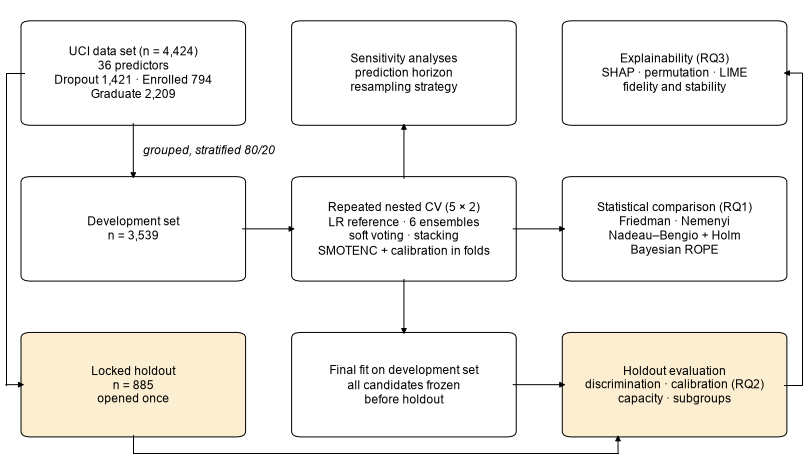

In [5]:
# ============================================================
# 3. TABLA 1 (POR DESENLACE), TABLAS S1–S2 Y FIGURA 1
# ============================================================
N = len(df)
pct = lambda k, n: f"{k:,} ({k / n * 100:.1f})" if n else "—"
rows = [{"Characteristic": "Students, n (%)", "Overall": f"{N:,}",
         **{c: pct(int((y_all == i).sum()), N) for i, c in enumerate(CLASSES)}, "p value": "", "Effect size": ""}]
QUANT_T1 = ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "Application order",
            "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
            "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)", "Unemployment rate", "Inflation rate", "GDP"]
BIN_T1 = ["Gender", "Scholarship holder", "Debtor", "Tuition fees up to date", "Displaced", "International",
          "Daytime/evening attendance", "Educational special needs"]
med = lambda s: f"{num(s.median(), 1)} ({num(s.quantile(.25), 1)}–{num(s.quantile(.75), 1)})"
for c in QUANT_T1:
    groups = [df.loc[y_all == i, c].astype(float) for i in range(K)]
    H, p = stats.kruskal(*groups)
    eps2 = max(0.0, (H - K + 1) / (N - K))
    rows.append({"Characteristic": f"{c}, median (IQR)", "Overall": med(df[c].astype(float)),
                 **{CLASSES[i]: med(groups[i]) for i in range(K)}, "p value": fmt_p(p), "Effect size": f"ε² = {eps2:.2f}"})
for c in BIN_T1:
    tab = pd.crosstab(df[c], y_all)
    chi2, p, *_ = stats.chi2_contingency(tab, correction=False)
    v = math.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    pos = (df[c] == 1).to_numpy()
    rows.append({"Characteristic": f"{c} = yes, n (%)" if c != "Gender" else "Male, n (%)", "Overall": pct(int(pos.sum()), N),
                 **{CLASSES[i]: pct(int((pos & (y_all == i)).sum()), int((y_all == i).sum())) for i in range(K)},
                 "p value": fmt_p(p), "Effect size": f"V = {v:.2f}"})
t1 = pd.DataFrame(rows)
t1.insert(0, "Block", ["Sample"] + ["Quantitative characteristics"] * len(QUANT_T1) + ["Binary characteristics"] * len(BIN_T1))
register_table(t1, "Table1_characteristics", "1", "Characteristics of the students by academic outcome",
               "Quantitative variables: median (interquartile range, IQR), Kruskal–Wallis test, ε² effect size. Binary "
               "variables: n (column %), Pearson χ² test without continuity correction, Cramér's V. Descriptive statistics use "
               f"the full sample (development and holdout). Exact duplicate records removed: {n_dup}",
               landscape=True, group_col="Block")
audit = pd.DataFrame({"Variable": ALL_PRED,
                      "Type": ["nominal" if c in NOMINAL else "binary" if c in BINARY else "quantitative" for c in ALL_PRED],
                      "Missing": [int(df[c].isna().sum()) for c in ALL_PRED],
                      "Unique values": [int(df[c].nunique()) for c in ALL_PRED],
                      "Available at": ["end of 2nd semester" if c in SEM2 else "end of 1st semester" if c in SEM1
                                       else "enrolment" for c in ALL_PRED],
                      "Figure label": [SHORT[c] for c in ALL_PRED]})
register_table(audit, "TableS1_data_audit", "S1", "Predictor audit: type, completeness and time of availability",
               "Nominal predictors are integer-coded in the source file and were one-hot encoded within training folds "
               f"(categories with < {CFG.min_category_frequency} training records pooled as infrequent). Time of availability "
               "follows the data descriptor (Realinho et al., 2022). Figure label: abbreviation used in the figures "
               "(CU1/CU2, curricular units in the first/second semester)", supplementary=True)
register_table(profile_audit, "TableS2_profile_audit", "S2", "Audit of predictor-profile multiplicity",
               "A profile is the full vector of the 36 predictors. All partitions (holdout, outer and inner cross-validation, "
               "calibration and stacking folds) were grouped by profile so that identical profiles never appear on both sides "
               "of a split", supplementary=True)


def box(ax, xy, text, w, h, fc="white", fs=7):
    ax.add_patch(mpl.patches.FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h,
                 boxstyle="round,pad=0.004,rounding_size=0.012", fc=fc, ec="black", lw=0.6))
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=fs, linespacing=1.3)


def arrow(ax, a, b):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=0.6, color="black", mutation_scale=7,
                                                    shrinkA=0, shrinkB=0))


cnt = np.bincount(y_all, minlength=K)
HOLD_FC = tint(OKABE_ITO["orange"], 0.18)
fig, ax = new_figure("double", 100)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
W_, H_ = 0.27, 0.22
X1, X2, X3 = 0.165, 0.50, 0.835
Y1, Y2, Y3 = 0.84, 0.50, 0.16
e = W_ / 2
box(ax, (X1, Y1), f"UCI data set (n = {N:,})\n36 predictors\nDropout {cnt[0]:,} · Enrolled {cnt[1]:,}\nGraduate {cnt[2]:,}", W_, H_)
box(ax, (X1, Y2), f"Development set\nn = {len(y_dev):,}", W_, H_)
box(ax, (X1, Y3), f"Locked holdout\nn = {len(y_hold):,}\nopened once", W_, H_, fc=HOLD_FC)
box(ax, (X2, Y1), "Sensitivity analyses\nprediction horizon\nresampling strategy", W_, H_)
box(ax, (X2, Y2), f"Repeated nested CV ({CFG.outer_splits} × {CFG.outer_repeats})\nLR reference · 6 ensembles\n"
    "soft voting · stacking\nSMOTENC + calibration in folds", W_, H_)
box(ax, (X2, Y3), "Final fit on development set\nall candidates frozen\nbefore holdout", W_, H_)
box(ax, (X3, Y1), "Explainability (RQ3)\nSHAP · permutation · LIME\nfidelity and stability", W_, H_)
box(ax, (X3, Y2), "Statistical comparison (RQ1)\nFriedman · Nemenyi\nNadeau–Bengio + Holm\nBayesian ROPE", W_, H_)
box(ax, (X3, Y3), "Holdout evaluation\ndiscrimination · calibration (RQ2)\ncapacity · subgroups", W_, H_, fc=HOLD_FC)
arrow(ax, (X1, Y1 - H_ / 2), (X1, Y2 + H_ / 2))
ax.text(X1 + 0.012, (Y1 + Y2) / 2, "grouped, stratified 80/20", fontsize=7, style="italic", va="center")
arrow(ax, (X1 + e, Y2), (X2 - e, Y2)); arrow(ax, (X2, Y2 + H_ / 2), (X2, Y1 - H_ / 2)); arrow(ax, (X2 + e, Y2), (X3 - e, Y2))
arrow(ax, (X2, Y2 - H_ / 2), (X2, Y3 + H_ / 2)); arrow(ax, (X2 + e, Y3), (X3 - e, Y3))
ax.plot([X1, X1, X3 - 0.07], [Y3 - H_ / 2, 0.012, 0.012], color="black", lw=0.6)
arrow(ax, (X3 - 0.07, 0.012), (X3 - 0.07, Y3 - H_ / 2))
ax.plot([X3 + e, 0.993, 0.993], [Y3, Y3, Y1], color="black", lw=0.6); arrow(ax, (0.993, Y1), (X3 + e, Y1))
ax.plot([X1 - e, 0.007, 0.007], [Y1, Y1, Y3], color="black", lw=0.6); arrow(ax, (0.007, Y3), (X1 - e, Y3))
save_figure(fig, "Fig1_study_design",
            "Fig. 1 Study design. A holdout stratified by the three outcomes and grouped by predictor profile was locked "
            "before any analysis. Encoding, SMOTENC oversampling, hyperparameter tuning, stacking and calibration were fitted "
            "only on training folds of repeated nested cross-validation; all candidates were refitted on the development set "
            "and frozen before the holdout was opened once. CV, cross-validation; LR, logistic regression; RQ, research "
            "question; ROPE, region of practical equivalence")

## 4. Arquitecturas: remuestreo, codificación y ajuste solo dentro de cada ajuste

Cada candidato es un `ResampledPipeline`: en `fit` aplica **SMOTENC** sobre las variables originales (nominales y binarias declaradas categóricas), luego ajusta la codificación *one-hot*/estandarización y el clasificador; en `predict_proba` solo transforma. Así ningún registro sintético llega a validación, calibración ni reserva.

Los metaensambles combinan aprendices base **heterogéneos** (`CFG.meta_base`), cada uno con su propio remuestreo y codificación, usando **los hiperparámetros ajustados para esos mismos aprendices en el mismo pliegue externo**. El *stacking* (`GroupedStackingClassifier`) entrena su metaaprendiz (LR multinomial) con probabilidades fuera de pliegue obtenidas con pliegues **agrupados por perfil**.

**Memoización (solo afecta al tiempo).** El conjunto remuestreado y los ajustes de los aprendices base se guardan en memoria por huella exacta de los datos, hiperparámetros y semillas, de modo que la votación y el *stacking* reutilizan los modelos ya ajustados. Las semillas están alineadas para que un aprendiz base dentro de un metaensamble sea idéntico al modelo evaluado por separado.

In [6]:
# ============================================================
# 4. ARQUITECTURAS (con memoización determinista de ajustes)
# ============================================================
# --- Almacén por proceso: cada proceso de trabajo tiene su propia memoria caché (no se serializa entre procesos) ---
def _store():
    st = sys.modules.get("_eait_store")
    if st is None:
        st = types.ModuleType("_eait_store")
        st.res, st.fit, st.stats = OrderedDict(), OrderedDict(), Counter()
        st.write_fit, st.pinned, st.max_fit, st.max_res = False, frozenset(), 24, 64
        sys.modules["_eait_store"] = st
    return st


def cache_reset(pinned=(), max_fit=24, max_res=64):
    st = _store()
    st.res.clear(); st.fit.clear(); st.stats.clear()
    st.write_fit, st.pinned, st.max_fit, st.max_res = False, frozenset(pinned), int(max_fit), int(max_res)
    return st


@contextlib.contextmanager
def fit_cache_writes(flag):
    st = _store(); old = st.write_fit; st.write_fit = flag
    try:
        yield
    finally:
        st.write_fit = old


def _lru_put(d, key, value, cap):
    d[key] = value; d.move_to_end(key)
    while len(d) > cap:
        d.popitem(last=False)


def data_key(X, y):
    """Huella del contenido exacto de (X, y): mismo contenido y orden → misma huella."""
    h = hashlib.blake2b(digest_size=16)
    h.update(pd.util.hash_pandas_object(X, index=False).to_numpy().tobytes())
    h.update(np.ascontiguousarray(np.asarray(y, dtype=np.int64)).tobytes())
    h.update("|".join(map(str, X.columns)).encode())
    return h.hexdigest()


class _SimpleROS(BaseEstimator):
    """Respaldo mínimo si imbalanced-learn no está instalado (solo pruebas estructurales en modo rápido)."""
    def __init__(self, random_state=None):
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.default_rng(self.random_state); y = np.asarray(y)
        n_max = np.bincount(y).max()
        idx = np.concatenate([np.r_[ic, rng.choice(ic, n_max - len(ic), replace=True)]
                              for ic in (np.where(y == c)[0] for c in np.unique(y))])
        return X.iloc[idx].reset_index(drop=True), y[idx]


def make_prep(cols):
    nom = [c for c in cols if c in NOMINAL]; qn_ = [c for c in cols if c not in NOMINAL]
    parts = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), qn_)]
    if nom:
        parts.append(("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                       ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                             min_frequency=CFG.min_category_frequency,
                                                             sparse_output=False))]), nom))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)


class ResampledPipeline(ClassifierMixin, BaseEstimator):
    """Remuestreo → codificación → clasificador, todo ajustado SOLO con los datos que recibe fit().

    SMOTENC opera sobre las variables originales (nominales y binarias como categóricas), de modo que los registros
    sintéticos conservan categorías válidas; predict_proba solo transforma y nunca remuestrea.
    Optimización sin efecto en los resultados: (i) el conjunto remuestreado se memoiza por huella de los datos y semilla
    (todos los modelos de un mismo pliegue comparten los mismos registros sintéticos: diseño pareado); (ii) los ajustes de
    los aprendices base de los metaensambles se memoizan y se reutilizan (ajuste idéntico, mismas semillas)."""
    def __init__(self, estimator=None, cols=None, resampling="smotenc", random_state=None):
        self.estimator, self.cols, self.resampling, self.random_state = estimator, cols, resampling, random_state

    def _sampler(self, y):
        kind = self.resampling
        if kind in (None, "none"):
            return None
        if kind == "smotenc":
            if SMOTENC is not None:
                cat = [i for i, c in enumerate(self.cols) if c in NOMINAL or c in BINARY]
                k = int(max(1, min(5, np.bincount(y).min() - 1)))
                return SMOTENC(categorical_features=cat, k_neighbors=k, random_state=self.random_state)
            if not QUICK:
                raise ImportError("SMOTENC requires imbalanced-learn")
            return _SimpleROS(self.random_state)                  # solo prueba estructural
        if kind == "random_oversampling":
            return RandomOverSampler(random_state=self.random_state) if RandomOverSampler else _SimpleROS(self.random_state)
        raise ValueError(f"Unknown resampling strategy: {kind}")

    def _restore(self, Xr):
        Xr = Xr if isinstance(Xr, pd.DataFrame) else pd.DataFrame(Xr, columns=self.cols)
        Xr = Xr[self.cols].reset_index(drop=True).copy()
        for c in self.cols:
            Xr[c] = Xr[c].astype(str).astype(object) if c in NOMINAL else Xr[c].astype(float)
        return Xr

    def _resample(self, X, y, dk):
        s = self._sampler(y)
        if s is None:
            return X.reset_index(drop=True), y
        st = _store(); key = (dk, tuple(self.cols), self.resampling, self.random_state)
        hit = st.res.get(key)
        if hit is not None:
            st.res.move_to_end(key); st.stats["resample_hit"] += 1
            return hit
        Xr, yr = s.fit_resample(X, y)
        out = (self._restore(Xr), np.asarray(yr).astype(int))
        _lru_put(st.res, key, out, st.max_res); st.stats["resample_miss"] += 1
        return out

    def fit(self, X, y):
        X, y = X[self.cols], np.asarray(y).astype(int)
        st, dk = _store(), data_key(X, y)
        pinned = type(self.estimator).__name__ in st.pinned
        if pinned:
            fkey = (dk, joblib.hash((type(self.estimator).__name__, self.estimator.get_params(), tuple(self.cols),
                                     self.resampling, self.random_state)))
            hit = st.fit.get(fkey)
            if hit is not None:
                st.fit.move_to_end(fkey); st.stats["fit_hit"] += 1
                self.prep_, self.estimator_, self.n_resampled_ = hit
                self.classes_ = np.asarray(self.estimator_.classes_)
                return self
        Xr, yr = self._resample(X, y, dk)
        self.prep_ = make_prep(self.cols).fit(Xr)
        self.estimator_ = clone(self.estimator).fit(self.prep_.transform(Xr), yr)
        self.classes_ = np.asarray(self.estimator_.classes_)
        self.n_resampled_ = int(len(yr))
        if pinned and st.write_fit:
            _lru_put(st.fit, fkey, (self.prep_, self.estimator_, self.n_resampled_), st.max_fit); st.stats["fit_store"] += 1
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(self.prep_.transform(X[self.cols]))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class GroupedStackingClassifier(ClassifierMixin, BaseEstimator):
    """Stacking con probabilidades fuera de pliegue obtenidas con pliegues ESTRATIFICADOS Y AGRUPADOS POR PERFIL
    (coherente con el resto del diseño: perfiles idénticos nunca a ambos lados de una partición). Metaaprendiz: LR
    multinomial sobre las K × B probabilidades de los aprendices base (equivalente a stack_method='predict_proba')."""
    def __init__(self, estimators=None, final_estimator=None, n_splits=5, random_state=None):
        self.estimators, self.final_estimator, self.n_splits, self.random_state = estimators, final_estimator, n_splits, random_state

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        cv = list(StratifiedGroupKFold(self.n_splits, shuffle=True, random_state=self.random_state)
                  .split(np.zeros(len(y)), y, profile_codes(X)))
        Z = np.full((len(y), K * len(self.estimators)), np.nan)
        with fit_cache_writes(False):                          # ajustes internos de un solo uso: no se memoizan
            for j, (_, est) in enumerate(self.estimators):
                for tr, va in cv:
                    m = clone(est).fit(X.iloc[tr], y[tr])
                    assert list(m.classes_) == list(range(K)), "Every class must be present in each stacking fold"
                    Z[va, j * K:(j + 1) * K] = m.predict_proba(X.iloc[va])
        assert np.isfinite(Z).all(), "Stacking folds must cover every training observation"
        self.estimators_ = [clone(est).fit(X, y) for _, est in self.estimators]
        self.final_estimator_ = clone(self.final_estimator).fit(Z, y)
        self.classes_ = np.arange(K)
        return self

    def predict_proba(self, X):
        return self.final_estimator_.predict_proba(np.hstack([e.predict_proba(X) for e in self.estimators_]))

    def predict(self, X):
        return self.predict_proba(X).argmax(1)


REF = "LogisticRegression (reference)"
DISPLAY = {"RandomForest": "Random forest", "ExtraTrees": "Extra trees", "GradientBoosting": "Gradient boosting",
           "XGBoost": "XGBoost", "LightGBM": "LightGBM", "CatBoost": "CatBoost", "VotingSoft": "Soft voting",
           "Stacking": "Stacking", REF: "Logistic regression"}
MODEL_OFFSET = {n: 7 * (i + 1) for i, n in enumerate(
    ["RandomForest", "ExtraTrees", "GradientBoosting", "XGBoost", "LightGBM", "CatBoost", REF])}


def make_estimator(name, seed):
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=400, random_state=seed, n_jobs=1)
    if name == "ExtraTrees":
        return ExtraTreesClassifier(n_estimators=400, random_state=seed, n_jobs=1)
    if name == "GradientBoosting":
        return GradientBoostingClassifier(random_state=seed)
    if name == REF:
        return LogisticRegression(max_iter=5000, C=1.0)            # multinomial (lbfgs) con penalización L2
    if name == "XGBoost" and XGBClassifier:
        return XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist", n_estimators=400,
                             max_depth=4, learning_rate=0.05, subsample=0.85, colsample_bytree=0.8, random_state=seed,
                             n_jobs=1, verbosity=0)
    if name == "LightGBM" and LGBMClassifier:
        return LGBMClassifier(objective="multiclass", n_estimators=400, learning_rate=0.05, num_leaves=15,
                              subsample_freq=1, random_state=seed, n_jobs=1, verbose=-1)
    if name == "CatBoost" and CatBoostClassifier:
        return CatBoostClassifier(loss_function="MultiClass", iterations=500, depth=6, learning_rate=0.05,
                                  random_seed=seed, verbose=False, allow_writing_files=False, thread_count=1)
    return None


ENSEMBLES = [m for m in ["RandomForest", "ExtraTrees", "GradientBoosting", "XGBoost", "LightGBM", "CatBoost"]
             if make_estimator(m, SEED) is not None]
META_MODELS = ["VotingSoft", "Stacking"]
META_BASE = [b for b in CFG.meta_base if b in ENSEMBLES]
if len(META_BASE) < 3:                                          # respaldo solo si faltan librerías (modo rápido)
    META_BASE = [b for b in ["RandomForest", "ExtraTrees", "GradientBoosting"] if b in ENSEMBLES]
MODEL_NAMES = ENSEMBLES + META_MODELS + [REF]                   # los individuales primero: los meta reutilizan su ajuste
CANDIDATES = ENSEMBLES + META_MODELS                            # elegibles; la LR es solo referencia
PINNED = frozenset(type(make_estimator(b, SEED)).__name__ for b in META_BASE)
FIT_CACHE_N = max(CFG.fit_cache_size, (CFG.calibration_splits + 1) * len(META_BASE) + 4)
P = "estimator__"
PARAMS = {
    "RandomForest": {P + "n_estimators": [200, 400, 600], P + "max_depth": [None, 10, 20],
                     P + "min_samples_leaf": [1, 2, 4], P + "max_features": ["sqrt", "log2", 0.5]},
    "ExtraTrees": {P + "n_estimators": [200, 400, 600], P + "max_depth": [None, 10, 20],
                   P + "min_samples_leaf": [1, 2, 4], P + "max_features": ["sqrt", "log2", 0.5]},
    "GradientBoosting": {P + "n_estimators": [100, 200, 300], P + "learning_rate": [0.03, 0.05, 0.1],
                         P + "max_depth": [2, 3, 4], P + "subsample": [0.7, 0.85, 1.0]},
    "XGBoost": {P + "n_estimators": [200, 400, 600], P + "max_depth": [3, 4, 6], P + "learning_rate": [0.03, 0.05, 0.1],
                P + "subsample": [0.7, 0.85, 1.0], P + "colsample_bytree": [0.6, 0.8, 1.0], P + "min_child_weight": [1, 3, 5]},
    "LightGBM": {P + "n_estimators": [200, 400, 600], P + "learning_rate": [0.03, 0.05, 0.1], P + "num_leaves": [7, 15, 31],
                 P + "min_child_samples": [10, 20, 40], P + "subsample": [0.7, 0.85, 1.0],
                 P + "colsample_bytree": [0.6, 0.8, 1.0], P + "reg_lambda": [0.0, 1.0, 5.0]},
    "CatBoost": {P + "iterations": [300, 500, 800], P + "depth": [4, 6, 8], P + "learning_rate": [0.03, 0.05, 0.1],
                 P + "l2_leaf_reg": [1, 3, 10]},
    REF: {P + "C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
}
if QUICK:                                                       # solo prueba estructural: árboles mucho más pequeños
    for _g in PARAMS.values():
        for _k in [k for k in _g if k.endswith(("n_estimators", "iterations"))]:
            _g[_k] = [20, 40]


def build_model(name, cols, seed, resampling=None, base_params=None):
    """seed = semilla del bloque. El remuestreo usa la semilla del bloque (datos sintéticos compartidos por todos los
    modelos del pliegue) y cada estimador una semilla propia y fija; así un aprendiz base dentro de un metaensamble
    es idéntico al mismo modelo evaluado individualmente (comparación pareada exacta en la familia B)."""
    resampling = CFG.resampling if resampling is None else resampling
    if name in META_MODELS:
        base_params = base_params or {}
        est = []
        for b in META_BASE:
            rp = ResampledPipeline(make_estimator(b, seed + MODEL_OFFSET[b]), cols, resampling, seed)
            if base_params.get(b):
                rp.set_params(**base_params[b])
            est.append((b, rp))
        if name == "VotingSoft":
            return VotingClassifier(est, voting="soft", n_jobs=1)
        return GroupedStackingClassifier(est, final_estimator=LogisticRegression(max_iter=5000, C=1.0),
                                         n_splits=CFG.stacking_splits, random_state=seed + 24)
    return ResampledPipeline(make_estimator(name, seed + MODEL_OFFSET[name]), cols, resampling, seed)


def audit_meta_architecture(model):
    """Verificación: cada aprendiz base tiene su propio remuestreo y codificación; una sola corrección del desbalance;
    el stacking usa pliegues agrupados por perfil."""
    for nm, est in model.estimators:
        assert isinstance(est, ResampledPipeline), nm
        assert est.resampling == CFG.resampling, nm
    if isinstance(model, GroupedStackingClassifier):
        assert model.n_splits >= 2 and getattr(model.final_estimator, "class_weight", None) is None
    return True


assert all(audit_meta_architecture(build_model(m, COLS, SEED)) for m in META_MODELS)
print("Candidates:", CANDIDATES, "| reference:", REF, "| meta-ensemble base learners:", META_BASE,
      "| workers:", N_WORKERS)

Candidates: ['RandomForest', 'ExtraTrees', 'GradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost', 'VotingSoft', 'Stacking'] | reference: LogisticRegression (reference) | meta-ensemble base learners: ['RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM'] | workers: 8


## 5. Métricas multiclase, calibración dentro del pliegue y ajuste interno

**Calibración.** Para cada candidato, el estimador ajustado se reentrena en `calibration_splits` pliegues internos (agrupados por perfil) para obtener probabilidades **fuera de pliegue**; con ellas se ajustan los mapas de calibración y, por último, el estimador se reajusta con todo el entrenamiento. Métodos: *temperature scaling* (primario; un parámetro, conserva la clase predicha), regresión isotónica uno-contra-resto renormalizada y calibración de Dirichlet (*matrix scaling* con L2; Kull et al., 2019).

**Métricas.** F1 macro (primaria), exactitud balanceada, MCC, κ, AUC macro uno-contra-resto, F1 ponderado (solo para comparar con la literatura), F1/*recall*/precisión/AUC por clase; Brier multiclase, log-loss, ECE *top-label* y ECE por clase (15 intervalos de igual anchura), e intercepto y pendiente de calibración uno-contra-resto. Las métricas están vectorizadas y la celda **verifica** que coinciden con scikit-learn antes de continuar.

In [7]:
# ============================================================
# 5. MÉTRICAS (VECTORIZADAS Y VERIFICADAS), CALIBRACIÓN Y AJUSTE
# ============================================================
EPS = 1e-6


def _logp(P):
    return np.log(np.clip(np.asarray(P, float), EPS, 1.0))


def _softmax(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z)
    return E / E.sum(1, keepdims=True)


def nll(y, P):
    P = np.clip(np.asarray(P, float), EPS, 1.0)
    return float(-np.mean(np.log(P[np.arange(len(y)), np.asarray(y).astype(int)])))


class CalibrationMap:
    """Mapa de calibración multiclase ajustado sobre probabilidades fuera de pliegue."""
    def __init__(self, method):
        self.method = method

    def fit(self, P, y):
        m, y = self.method, np.asarray(y).astype(int)
        if m == "temperature":
            L = _logp(P)
            res = minimize_scalar(lambda lt: nll(y, _softmax(L / np.exp(lt))), bounds=(-3, 3), method="bounded")
            self.T_ = float(np.exp(res.x))
        elif m == "isotonic":
            self.iso_ = [IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(P[:, k], (y == k).astype(float))
                         for k in range(K)]
        elif m == "dirichlet":
            self.lr_ = LogisticRegression(C=1.0, max_iter=5000).fit(_logp(P), y)
        elif m != "uncalibrated":
            raise ValueError(m)
        return self

    def transform(self, P):
        m, P = self.method, np.asarray(P, float)
        if m == "uncalibrated":
            return P
        if m == "temperature":
            return _softmax(_logp(P) / self.T_)
        if m == "isotonic":
            Q = np.column_stack([iso.predict(P[:, k]) for k, iso in enumerate(self.iso_)]); s = Q.sum(1, keepdims=True)
            return np.where(s > 0, Q / np.where(s > 0, s, 1.0), P)
        return self.lr_.predict_proba(_logp(P))


class CVCalibratedClassifier(ClassifierMixin, BaseEstimator):
    """Ajusta el estimador en pliegues internos → probabilidades OOF → mapas de calibración; reajusta en todo el entrenamiento."""
    def __init__(self, estimator=None, method="temperature", cv=None, methods=None):
        self.estimator, self.method, self.cv, self.methods = estimator, method, cv, methods

    def fit(self, X, y):
        y = np.asarray(y).astype(int); oof = np.full((len(y), K), np.nan)
        for tr, va in self.cv:
            m = clone(self.estimator).fit(X.iloc[tr], y[tr])
            assert list(m.classes_) == list(range(K)), "Every class must be present in each calibration fold"
            oof[va] = m.predict_proba(X.iloc[va])
        assert np.isfinite(oof).all(), "Calibration folds must cover every training observation"
        meths = set(self.methods or ()) | {self.method}
        self.maps_ = {mm: CalibrationMap(mm).fit(oof, y) for mm in meths}
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = np.arange(K)
        return self

    def predict_proba(self, X, method=None):
        return self.maps_[method or self.method].transform(self.estimator_.predict_proba(X))

    def predict(self, X):
        return self.predict_proba(X).argmax(1)


# ---------- Métricas vectorizadas (≈ 20–50× más rápidas que llamar a scikit-learn en cada remuestreo bootstrap) ----------
def ece_binary(yb, pb, bins=None):
    """ECE con intervalos de igual anchura cerrados por la derecha (idéntico a np.digitize(right=True))."""
    bins = bins or CFG.ece_bins
    yb, pb = np.asarray(yb, float), np.clip(np.asarray(pb, float), 0, 1)
    idx = np.searchsorted(np.linspace(0, 1, bins + 1)[1:-1], pb, side="left")
    return float(np.abs(np.bincount(idx, yb, bins) - np.bincount(idx, pb, bins)).sum() / len(pb))


def auc_binary(yk, s):
    """AUC = estadístico de Mann–Whitney con empates a 0.5 (idéntico a roc_auc_score)."""
    yk = np.asarray(yk).astype(bool); n1 = int(yk.sum()); n0 = len(yk) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(s)
    return float((r[yk].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def mc_metrics(y, P):
    y = np.asarray(y).astype(int); P = np.asarray(P, float); n = len(y); z = P.argmax(1)
    C = np.bincount(y * K + z, minlength=K * K).reshape(K, K).astype(float)
    t, p, tp = C.sum(1), C.sum(0), np.diag(C)
    fp, fn = p - tp, t - tp
    rec = np.divide(tp, t, out=np.zeros(K), where=t > 0)
    prec = np.divide(tp, p, out=np.zeros(K), where=p > 0)
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)
    c, s = tp.sum(), float(n)
    cov_tp, cov_pp, cov_tt = c * s - t @ p, s * s - p @ p, s * s - t @ t
    pe = (t @ p) / s ** 2
    Y = np.eye(K)[y]
    aucs = [auc_binary(y == k, P[:, k]) for k in range(K)]
    out = {"accuracy": c / s, "balanced_accuracy": float(rec[t > 0].mean()), "f1_macro": float(f1.mean()),
           "f1_weighted": float((f1 * t).sum() / s), "mcc": float(cov_tp / math.sqrt(cov_tt * cov_pp)) if cov_tt * cov_pp > 0 else 0.0,
           "kappa": float((c / s - pe) / (1 - pe)) if pe < 1 else np.nan,
           "roc_auc_macro": float(np.mean(aucs)) if (t > 0).all() else np.nan,
           "brier": float(np.mean(np.sum((P - Y) ** 2, 1))), "log_loss": nll(y, P),
           "ece": ece_binary((z == y).astype(float), P.max(1))}
    eces = []
    for k, cl in enumerate(CLASSES):
        out[f"recall_{cl}"], out[f"precision_{cl}"], out[f"f1_{cl}"], out[f"auc_{cl}"] = rec[k], prec[k], f1[k], aucs[k]
        out[f"ece_{cl}"] = ece_binary(y == k, P[:, k]); eces.append(out[f"ece_{cl}"])
    out["cw_ece"] = float(np.mean(eces))
    return out


def _mc_metrics_sklearn(y, P):
    """Implementación de referencia con scikit-learn, usada solo para verificar mc_metrics."""
    y = np.asarray(y).astype(int); P = np.asarray(P, float); z = P.argmax(1)
    full = len(np.unique(y)) == K
    out = {"accuracy": accuracy_score(y, z), "balanced_accuracy": balanced_accuracy_score(y, z),
           "f1_macro": f1_score(y, z, average="macro", labels=range(K), zero_division=0),
           "f1_weighted": f1_score(y, z, average="weighted", labels=range(K), zero_division=0),
           "mcc": matthews_corrcoef(y, z), "kappa": cohen_kappa_score(y, z),
           "roc_auc_macro": roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(K))) if full else np.nan}
    for k, cl in enumerate(CLASSES):
        yk = (y == k).astype(int)
        out[f"recall_{cl}"] = recall_score(yk, (z == k).astype(int), zero_division=0)
        out[f"precision_{cl}"] = precision_score(yk, (z == k).astype(int), zero_division=0)
        out[f"f1_{cl}"] = f1_score(yk, (z == k).astype(int), zero_division=0)
        out[f"auc_{cl}"] = roc_auc_score(yk, P[:, k]) if 0 < yk.sum() < len(yk) else np.nan
    return out


def _verify_metrics(n_trials=60, seed=7):
    rng = np.random.default_rng(seed); worst = 0.0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for tr in range(n_trials):
            n = int(rng.integers(30, 400)); y = rng.integers(0, K, n)
            P = rng.dirichlet(np.ones(K) * rng.uniform(0.3, 3), n)
            if tr % 5 == 0:                                   # sin predicciones de una clase
                P[:, 1] *= 0.01; P /= P.sum(1, keepdims=True)
            if tr % 7 == 0:                                   # empates en las puntuaciones
                P = np.round(P, 1) + 1e-9; P /= P.sum(1, keepdims=True)
            a, b = mc_metrics(y, P), _mc_metrics_sklearn(y, P)
            for k_, v in b.items():
                if np.isnan(v):
                    assert np.isnan(a[k_]), k_
                else:
                    worst = max(worst, abs(a[k_] - v))
    assert worst < 1e-9, f"Vectorised metrics differ from scikit-learn (max |Δ| = {worst})"
    return worst


METRICS_MAX_ABS_DIFF = _verify_metrics()
print(f"Vectorised metrics verified against scikit-learn (max |Δ| = {METRICS_MAX_ABS_DIFF:.1e})")


def logistic_recalibration(yb, pb, iters=100):
    """Calibración débil uno-contra-resto (Van Calster et al., 2019): intercepto con desplazamiento logit(p)
    ('calibration-in-the-large', ideal 0) y pendiente de la recalibración logística (ideal 1). Newton–Raphson."""
    yb = np.asarray(yb, float); pb = np.clip(np.asarray(pb, float), EPS, 1 - EPS); x = np.log(pb / (1 - pb))
    if yb.min() == yb.max():
        return np.nan, np.nan
    a = 0.0
    for _ in range(iters):
        mu = expit(a + x); h = (mu * (1 - mu)).sum()
        st_ = (yb - mu).sum() / max(h, 1e-12); a += st_
        if abs(st_) < 1e-10:
            break
    Xd = np.column_stack([np.ones_like(x), x]); b = np.array([0.0, 1.0])
    for _ in range(iters):
        mu = expit(Xd @ b); W = mu * (1 - mu)
        step = np.linalg.solve(Xd.T @ (Xd * W[:, None]) + 1e-10 * np.eye(2), Xd.T @ (yb - mu)); b += step
        if np.abs(step).max() < 1e-10:
            break
    return (float(a), float(b[1])) if np.isfinite([a, b[1]]).all() else (np.nan, np.nan)


def cal_lr_metrics(y, P):
    out = {}
    for k, cl in enumerate(CLASSES):
        out[f"citl_{cl}"], out[f"slope_{cl}"] = logistic_recalibration(np.asarray(y) == k, np.asarray(P)[:, k])
    return out


def gsplits(n_splits, y, groups, seed):
    """Particiones estratificadas por clase y agrupadas por perfil (reutilizables)."""
    groups = np.arange(len(y)) if groups is None else np.asarray(groups)
    return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))


def tune(name, X, y, seed, cols=None, resampling=None, groups=None, n_jobs=None):
    """Búsqueda aleatoria interna (F1 macro) con las MISMAS particiones internas para todos los modelos del bloque.
    Devuelve el estimador SIN ajustar con los mejores hiperparámetros."""
    cols = COLS if cols is None else cols
    n_jobs = CFG.n_jobs if n_jobs is None else n_jobs
    model, grid = build_model(name, cols, seed, resampling), PARAMS[name]
    cv = gsplits(CFG.inner_splits, y, groups, seed + 1)
    search = RandomizedSearchCV(model, grid, n_iter=min(CFG.search_n_iter, math.prod(len(v) for v in grid.values())),
                                scoring=CFG.tuning_scoring, cv=cv, random_state=seed + MODEL_OFFSET[name] + 2,
                                n_jobs=n_jobs, refit=False, error_score="raise")
    search.fit(X, y)
    return clone(model).set_params(**search.best_params_), search.best_params_, search.best_score_


def fit_candidate(name, X, y, seed, cols=None, resampling=None, groups=None, base_cache=None, n_jobs=None):
    """Ajusta (y, si es un metaensamble, construye con aprendices base ajustados) y calibra dentro de X.
    seed = semilla del bloque (compartida por todos los modelos del bloque)."""
    cols = COLS if cols is None else cols
    if name in META_MODELS:
        bp = {b: (base_cache[b] if base_cache and b in base_cache else tune(b, X, y, seed, cols, resampling, groups, n_jobs)[1])
              for b in META_BASE}
        est, inner, params = build_model(name, cols, seed, resampling, base_params=bp), np.nan, {"base_learners": bp}
    else:
        est, params, inner = tune(name, X, y, seed, cols, resampling, groups, n_jobs)
    with fit_cache_writes(True):
        cal = CVCalibratedClassifier(est, method=CFG.calibration_primary, methods=CFG.calibration_methods,
                                     cv=gsplits(CFG.calibration_splits, y, groups, seed + 101)).fit(X, y)
    return cal, params, inner


def short_params(bp):
    def _c(v):
        return v if isinstance(v, (int, float, str, type(None))) else str(v)
    if "base_learners" in bp:
        return json.dumps({b: {k.split("__")[-1]: _c(v) for k, v in p.items()} for b, p in bp["base_learners"].items()})
    return json.dumps({k.split("__")[-1]: _c(v) for k, v in bp.items()})


LABELS = {"accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy", "f1_macro": "Macro-F1",
          "f1_weighted": "Weighted F1", "mcc": "MCC", "kappa": "Cohen's κ", "roc_auc_macro": "Macro AUC",
          "brier": "Brier score", "log_loss": "Log-loss", "ece": "ECE (top-label)", "cw_ece": "Class-wise ECE",
          **{f"{m}_{c}": f"{n} ({c})" for c in CLASSES for m, n in
             [("recall", "Recall"), ("precision", "Precision"), ("f1", "F1"), ("auc", "AUC"), ("ece", "ECE"),
              ("citl", "Calibration intercept"), ("slope", "Calibration slope")]}}
CAL_LABEL = {"uncalibrated": "Uncalibrated", "temperature": "Temperature scaling", "isotonic": "Isotonic (OvR)",
             "dirichlet": "Dirichlet (matrix scaling)"}

Vectorised metrics verified against scikit-learn (max |Δ| = 2.1e-16)


## 6. Validación cruzada anidada repetida

Externa: `StratifiedGroupKFold` repetido (estratificado por las tres clases y agrupado por perfil). Interna (también agrupada y **común a todos los modelos del bloque**): búsqueda aleatoria con F1 macro y, después, calibración con predicciones fuera de pliegue. En cada bloque externo, los metaensambles se construyen con los hiperparámetros que los aprendices base obtuvieron **en ese mismo bloque**. Todos los candidatos comparten exactamente las mismas observaciones de validación, lo que permite contrastes pareados.

Cada bloque externo se ejecuta en un proceso independiente y se guarda en `models/cv_blocks/`; al volver a ejecutar la celda solo se calculan los bloques que faltan.

In [8]:
# ============================================================
# 6. CV ANIDADA REPETIDA (bloques externos en paralelo, reanudable)
# ============================================================
STAGE.start("Repeated nested cross-validation")
splits = [sp for r in range(CFG.outer_repeats) for sp in gsplits(CFG.outer_splits, y_dev, g_dev, SEED + 100 + r)]
N_BLOCKS = len(splits)
# La clave incluye la configuración, las rejillas, la versión del pipeline y las versiones de las librerías: una caché
# solo se reutiliza si todo lo que puede alterar los resultados es idéntico.
key = json.dumps({k: v for k, v in asdict(CFG).items() if k in (
    "pipeline_version", "outer_splits", "outer_repeats", "inner_splits", "search_n_iter", "tuning_scoring",
    "calibration_primary", "calibration_methods", "calibration_splits", "resampling", "stacking_splits",
    "min_category_frequency", "random_state", "test_size", "group_by_predictor_profile", "meta_base", "ece_bins")}
    | {"models": MODEL_NAMES, "meta_base_used": META_BASE, "n": len(y_dev), "params": PARAMS, "data_sha256": DATA_SHA,
       "libs": {k: VERSIONS[k] for k in ("scikit-learn", "imbalanced-learn", "xgboost", "lightgbm", "catboost")}},
    sort_keys=True, default=str)
KEY_HASH = hashlib.sha256(key.encode()).hexdigest()[:12]
BLOCK_DIR = MOD / "cv_blocks"; BLOCK_DIR.mkdir(exist_ok=True)
block_path = lambda k: BLOCK_DIR / f"block{k + 1:02d}_{KEY_HASH}.joblib"


def run_block(k):
    """Un bloque externo completo: ajuste, calibración y evaluación de todos los modelos (secuencial dentro del proceso)."""
    t_block = time.perf_counter()
    tr, va = splits[k]
    st = cache_reset(PINNED, FIT_CACHE_N, CFG.resample_cache_size)
    seed = SEED + 1000 * k
    rep, fold = k // CFG.outer_splits + 1, k % CFG.outer_splits + 1
    Xtr, ytr, gtr, Xva, yva = X_dev.iloc[tr], y_dev[tr], g_dev[tr], X_dev.iloc[va], y_dev[va]
    rows, prm, oofs, base_cache, tune_s = [], [], [], {}, {}
    for name in MODEL_NAMES:
        t0 = time.perf_counter()
        cal, bp, inner = fit_candidate(name, Xtr, ytr, seed, groups=gtr, base_cache=base_cache, n_jobs=1)
        fit_s = time.perf_counter() - t0
        if name in ENSEMBLES:
            base_cache[name], tune_s[name] = bp, fit_s
        if name in META_MODELS:                                   # el costo incluye el ajuste de sus aprendices base
            fit_s += sum(tune_s.get(b, 0.0) for b in META_BASE)
        for meth in CFG.calibration_methods:
            Pv = cal.predict_proba(Xva, method=meth)
            rows.append({"block": k + 1, "repeat": rep, "fold": fold, "model": name, "calibration": meth,
                         "fit_s": fit_s, **mc_metrics(yva, Pv)})
            if meth in (CFG.calibration_primary, "uncalibrated"):
                oofs.append(pd.DataFrame({"block": k + 1, "model": name, "calibration": meth, "row_id": dev_ids[va],
                                          "observed": yva, **{f"p_{c}": Pv[:, i] for i, c in enumerate(CLASSES)}}))
        prm.append({"Block": k + 1, "Model": name, "Inner macro-F1": None if np.isnan(inner) else round(inner, 4),
                    "Temperature (T)": round(cal.maps_["temperature"].T_, 3) if "temperature" in cal.maps_ else None,
                    "Selected hyperparameters": short_params(bp)})
    res = {"key": key, "rows": rows, "prm": prm, "oof": pd.concat(oofs, ignore_index=True),
           "cache_stats": dict(st.stats), "seconds": time.perf_counter() - t_block}
    cache_reset()
    joblib.dump(res, block_path(k))
    return k, res["seconds"], res["cache_stats"]


todo = [k for k in range(N_BLOCKS) if not (CFG.reuse_cache and block_path(k).exists()
                                           and joblib.load(block_path(k))["key"] == key)]
print(f"{N_BLOCKS - len(todo)} block(s) loaded from cache; {len(todo)} to compute with {min(N_WORKERS, max(1, len(todo)))} worker(s)")
if todo:
    done_info = Parallel(n_jobs=min(N_WORKERS, len(todo)), verbose=10)(delayed(run_block)(k) for k in todo)
    for k, sec, cs in sorted(done_info):
        print(f"  block {k + 1:2d}: {sec / 60:5.1f} min | cache {cs}")
blocks = [joblib.load(block_path(k)) for k in range(N_BLOCKS)]
fold_df = pd.DataFrame([r for b in blocks for r in b["rows"]])
param_df = pd.DataFrame([r for b in blocks for r in b["prm"]])
oof_df = pd.concat([b["oof"] for b in blocks], ignore_index=True)
CV_CACHE_STATS = pd.DataFrame([b["cache_stats"] for b in blocks]).sum().to_dict()
CV_BLOCK_SECONDS = [b["seconds"] for b in blocks]

FP = fold_df[fold_df.calibration == CFG.calibration_primary].copy()          # calibración primaria
counts = oof_df[oof_df.calibration == CFG.calibration_primary].groupby(["block", "model"]).size().unstack()
assert counts.nunique(axis=1).eq(1).all(), "Models did not share validation observations within a block"
assert oof_df.groupby(["model", "calibration"]).size().eq(len(y_dev) * CFG.outer_repeats).all(), "Incomplete repeated OOF"
_pc = oof_df[[f"p_{c}" for c in CLASSES]].to_numpy()
assert np.allclose(_pc.sum(1), 1, atol=1e-6) and (_pc >= 0).all(), "Invalid probability vectors"
print(FP.groupby("model")[["f1_macro", "mcc", "roc_auc_macro", "brier", "cw_ece"]].mean().round(3))
print("Cache statistics over all blocks:", CV_CACHE_STATS)
STAGE.stop()

▶ Repeated nested cross-validation
0 block(s) loaded from cache; 10 to compute with 8 worker(s)


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   3 out of  10 | elapsed: 45.6min remaining: 106.5min
[Parallel(n_jobs=8)]: Done   5 out of  10 | elapsed: 50.1min remaining: 50.1min
[Parallel(n_jobs=8)]: Done   7 out of  10 | elapsed: 54.2min remaining: 23.2min


  block  1:  54.1 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  2:  59.9 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  3:  45.2 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  4:  50.1 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  5:  48.7 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  6:  50.2 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  7:  42.4 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  8:  45.6 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block  9:  28.8 min | cache {'resample_miss': 27, 'resample_hit': 372, 'fit_store': 16, 'fit_hit': 32}
  block 10:  39.3 min | cache {'resample_miss': 27, 're

[Parallel(n_jobs=8)]: Done  10 out of  10 | elapsed: 84.5min finished


## 7. PI1 — Discriminación: ranking, prueba de Friedman, Nemenyi y contrastes pareados corregidos

* **Familia A (PI1):** cada ensamble y metaensamble frente a la LR multinomial calibrada, en F1 macro y MCC.
* **Familia B (vacío sobre metaensambles):** cada metaensamble frente a su mejor aprendiz base y frente al mejor ensamble individual.
* Prueba *t* corregida de Nadeau–Bengio (varianza inflada por n<sub>prueba</sub>/n<sub>entrenamiento</sub>) con ajuste de Holm dentro de cada familia y métrica. La **relevancia práctica** se juzga comparando el IC 95 % con el margen preespecificado (±0.01). Como complemento se informa la prueba *t* bayesiana correlacionada (Benavoli et al., 2017): P(mejor) y P(ROPE).
* Friedman con la corrección de Iman–Davenport (Demšar, 2006) y diagrama de diferencias críticas de Nemenyi.
* El candidato para la evaluación final se selecciona con una jerarquía de tolerancias preespecificada (F1 macro → MCC → AUC macro → Brier → menor costo). La LR no es elegible.

▶ RQ1 statistical comparison
Selected candidate: VotingSoft | Friedman p = 0.001 | Iman–Davenport p = <0.001 | CD = 3.799

Table 2  Discrimination of the candidates in repeated nested cross-validation (5-fold × 2 repeats; development set, n = 3,539)
              Model        Family      Macro-F1 Balanced accuracy           MCC     Cohen's κ     Macro AUC    F1 Dropout   F1 Enrolled   F1 Graduate   Weighted F1 Mean rank Time (s)
       Soft voting* Meta-ensemble 0.725 ± 0.016     0.720 ± 0.016 0.640 ± 0.017 0.638 ± 0.018 0.896 ± 0.008 0.785 ± 0.016 0.525 ± 0.040 0.864 ± 0.009 0.778 ± 0.011      2.00      666
            XGBoost      Ensemble 0.715 ± 0.020     0.711 ± 0.021 0.630 ± 0.021 0.628 ± 0.021 0.893 ± 0.008 0.780 ± 0.014 0.506 ± 0.054 0.860 ± 0.010 0.771 ± 0.014      4.20      155
           LightGBM      Ensemble 0.715 ± 0.017     0.709 ± 0.017 0.633 ± 0.018 0.632 ± 0.018 0.893 ± 0.007 0.783 ± 0.014 0.498 ± 0.043 0.864 ± 0.010 0.772 ± 0.012      4.10       95
  Gradient boostin

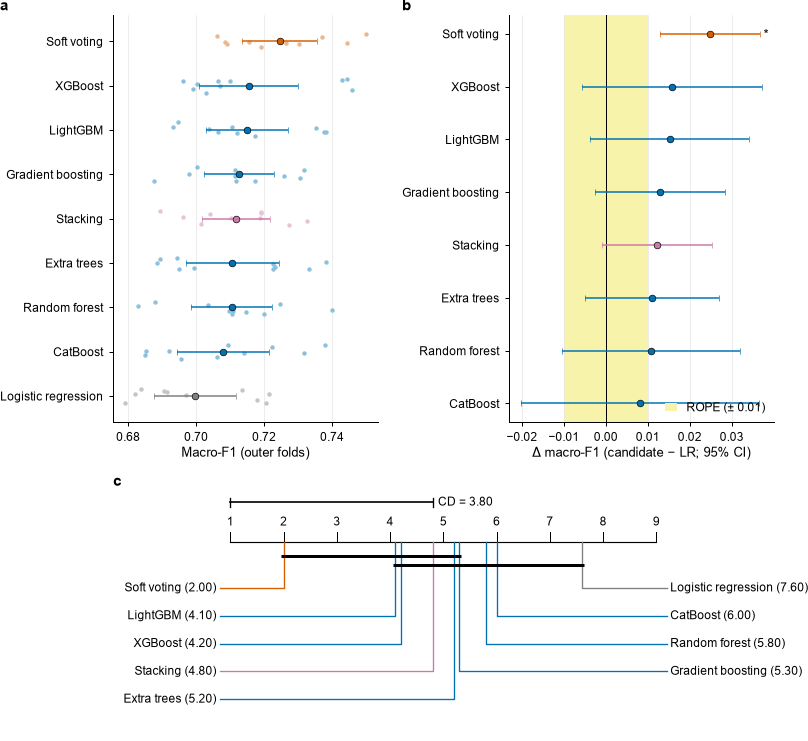

✔ RQ1 statistical comparison: 0.1 min


In [9]:
# ============================================================
# 7. PI1: RANKING, FRIEDMAN (IMAN–DAVENPORT)–NEMENYI, NADEAU–BENGIO + HOLM, ROPE BAYESIANO, SELECCIÓN
# ============================================================
STAGE.start("RQ1 statistical comparison")
METS_D = ["f1_macro", "balanced_accuracy", "mcc", "kappa", "roc_auc_macro", "f1_Dropout", "f1_Enrolled", "f1_Graduate",
          "recall_Enrolled", "f1_weighted", "brier", "cw_ece", "log_loss"]
summary = FP.groupby("model")[METS_D + ["fit_s"]].agg(["mean", "std"])
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
S = summary.set_index("model")
TEST_RATIO = 1 / (CFG.outer_splits - 1)                         # n_test / n_train de cada pliegue externo
dn = lambda m: DISPLAY.get(m, m)


def nb_test(d):
    """t corregido de Nadeau–Bengio para CV repetida (Bouckaert y Frank, 2004): media, IC 95 %, t y p."""
    d = np.asarray(d, float); n = len(d); mu = d.mean(); v = d.var(ddof=1) if n > 1 else np.nan
    se = math.sqrt((1 / n + TEST_RATIO) * v) if n > 1 and v > 0 else np.nan
    if not np.isfinite(se):
        return mu, np.nan, np.nan, np.nan, 1.0
    t = mu / se; tq = stats.t.ppf(1 - CFG.alpha / 2, n - 1)
    return mu, mu - tq * se, mu + tq * se, t, float(2 * stats.t.sf(abs(t), n - 1))


def bayes_rope(d, rope):
    """Prueba t bayesiana correlacionada (Benavoli et al., 2017): P(peor), P(ROPE), P(mejor)."""
    d = np.asarray(d, float); n = len(d); v = d.var(ddof=1) if n > 1 else np.nan
    sc = math.sqrt((1 / n + TEST_RATIO) * v) if n > 1 and v > 0 else np.nan
    if not np.isfinite(sc):
        return np.nan, np.nan, np.nan
    dist = stats.t(n - 1, loc=d.mean(), scale=sc)
    lo, hi = dist.cdf(-rope), dist.cdf(rope)
    return float(lo), float(hi - lo), float(1 - hi)


def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    return adj


def verdict(diff, lo, hi, p_adj, margin):
    if not np.isfinite(lo):
        return "not estimable"
    if lo > margin:
        return "superior (practically relevant)"
    if hi < -margin:
        return "inferior (practically relevant)"
    if p_adj < CFG.alpha:
        return ("superior" if diff > 0 else "inferior") + " (below practical margin)"
    if lo > -margin and hi < margin:
        return "practically equivalent"
    return "inconclusive"


def pivot_of(metric):
    return FP.pivot(index="block", columns="model", values=metric)[MODEL_NAMES]


PV = {m: pivot_of(m) for m in ("f1_macro", "mcc", "roc_auc_macro", "brier", "cw_ece", "ece_Enrolled")}
fr_stat, fr_p = stats.friedmanchisquare(*[PV["f1_macro"][c] for c in MODEL_NAMES])
k_mod = len(MODEL_NAMES)
ID_F = (N_BLOCKS - 1) * fr_stat / (N_BLOCKS * (k_mod - 1) - fr_stat) if N_BLOCKS * (k_mod - 1) > fr_stat else np.inf
ID_DF = (k_mod - 1, (k_mod - 1) * (N_BLOCKS - 1))
ID_P = float(stats.f.sf(ID_F, *ID_DF)) if np.isfinite(ID_F) else 0.0
ranks = PV["f1_macro"].rank(axis=1, ascending=False).mean()
q_alpha = float(studentized_range.ppf(1 - CFG.alpha, k_mod, np.inf) / math.sqrt(2))
CD = q_alpha * math.sqrt(k_mod * (k_mod + 1) / (6 * N_BLOCKS))
MARGIN = {"f1_macro": CFG.practical_margin_f1m, "mcc": CFG.practical_margin_mcc}

# --- Familia A: cada candidato frente a la LR calibrada ---
famA = []
for metric in ("f1_macro", "mcc"):
    rr = []
    for m in CANDIDATES:
        d = PV[metric][m] - PV[metric][REF]
        mu, lo, hi, t, p = nb_test(d); pw, pr, pb = bayes_rope(d, MARGIN[metric])
        rr.append({"metric": metric, "model": m, "diff": mu, "lo": lo, "hi": hi, "t": t, "p": p,
                   "p_worse": pw, "p_rope": pr, "p_better": pb})
    rr = pd.DataFrame(rr); rr["p_holm"] = holm(rr.p); famA.append(rr)
famA = pd.concat(famA, ignore_index=True)
famA["verdict"] = [verdict(r["diff"], r.lo, r.hi, r.p_holm, MARGIN[r.metric]) for _, r in famA.iterrows()]

# --- Familia B: metaensamble frente a su mejor aprendiz base y al mejor ensamble individual ---
best_base = max(META_BASE, key=lambda b: S.loc[b, "f1_macro_mean"])
best_single = max(ENSEMBLES, key=lambda b: S.loc[b, "f1_macro_mean"])
famB = []
for m in META_MODELS:
    for lab, comp in [("best base learner", best_base), ("best individual ensemble", best_single)]:
        if lab == "best individual ensemble" and comp == best_base:
            continue
        d = PV["f1_macro"][m] - PV["f1_macro"][comp]
        mu, lo, hi, t, p = nb_test(d); pw, pr, pb = bayes_rope(d, CFG.practical_margin_f1m)
        famB.append({"model": m, "comparator": comp, "comparator_role": lab, "diff": mu, "lo": lo, "hi": hi, "t": t,
                     "p": p, "p_worse": pw, "p_rope": pr, "p_better": pb})
famB = pd.DataFrame(famB); famB["p_holm"] = holm(famB.p)
famB["verdict"] = [verdict(r["diff"], r.lo, r.hi, r.p_holm, CFG.practical_margin_f1m) for _, r in famB.iterrows()]


def practical_select(s, candidates):
    cand = s[s.model.isin(candidates)].copy(); aud = []
    for col, tol, d in [("f1_macro_mean", CFG.tol_f1m, "max"), ("mcc_mean", CFG.tol_mcc, "max"),
                        ("roc_auc_macro_mean", CFG.tol_auc, "max"), ("brier_mean", CFG.tol_brier, "min")]:
        best = cand[col].max() if d == "max" else cand[col].min()
        keep = cand[col] >= best - tol if d == "max" else cand[col] <= best + tol
        aud.append({"Criterion": LABELS[col.replace("_mean", "")], "Direction": "maximise" if d == "max" else "minimise",
                    "Best": num(best, 4), "Tolerance": num(tol, 3), "Before": len(cand), "After": int(keep.sum()),
                    "Retained models": ", ".join(dn(m) for m in cand.loc[keep, "model"])})
        cand = cand[keep]
        if len(cand) == 1:
            break
    return cand.sort_values(["fit_s_mean", "model"], kind="mergesort").iloc[0].model, pd.DataFrame(aud)


BEST, sel_audit = practical_select(summary, CANDIDATES)
print("Selected candidate:", BEST, "| Friedman p =", fmt_p(fr_p), "| Iman–Davenport p =", fmt_p(ID_P), "| CD =", round(CD, 3))


def ms(m, col, d=3):
    return fmt_ms(S.loc[m, col + "_mean"], S.loc[m, col + "_std"], d)


family_of = lambda m: "Reference" if m == REF else ("Meta-ensemble" if m in META_MODELS else "Ensemble")
order_f1 = summary.sort_values("f1_macro_mean", ascending=False).model.tolist()
t2 = pd.DataFrame([{"Model": dn(m) + ("*" if m == BEST else ""), "Family": family_of(m),
       "Macro-F1": ms(m, "f1_macro"), "Balanced accuracy": ms(m, "balanced_accuracy"), "MCC": ms(m, "mcc"),
       "Cohen's κ": ms(m, "kappa"), "Macro AUC": ms(m, "roc_auc_macro"), "F1 Dropout": ms(m, "f1_Dropout"),
       "F1 Enrolled": ms(m, "f1_Enrolled"), "F1 Graduate": ms(m, "f1_Graduate"), "Weighted F1": ms(m, "f1_weighted"),
       "Mean rank": num(ranks[m], 2), "Time (s)": f"{S.loc[m, 'fit_s_mean']:.0f}"} for m in order_f1])
register_table(t2, "Table2_nested_cv_discrimination", "2",
               f"Discrimination of the candidates in repeated nested cross-validation ({CFG.outer_splits}-fold × "
               f"{CFG.outer_repeats} repeats; development set, n = {len(y_dev):,})",
               f"Mean ± SD over {N_BLOCKS} outer validation folds; bold, best value per column. Each candidate was tuned in "
               f"the inner loop ({CFG.inner_splits}-fold grouped CV, {CFG.search_n_iter} random configurations, macro-F1), "
               "with SMOTENC applied only to training data, and calibrated by temperature scaling on inner out-of-fold "
               "predictions. Classes were predicted by the highest probability. Mean rank: average Friedman rank on macro-F1 "
               f"(1 = best); Friedman χ²({k_mod - 1}) = {fr_stat:.2f}, p = {fmt_p(fr_p)}; Iman–Davenport F({ID_DF[0]}, "
               f"{ID_DF[1]}) = {ID_F:.2f}, p = {fmt_p(ID_P)}; Nemenyi critical difference = {CD:.2f}. * Selected by the "
               f"prespecified tolerance hierarchy (macro-F1 ± {CFG.tol_f1m}, MCC ± {CFG.tol_mcc}, macro AUC ± {CFG.tol_auc}, "
               f"Brier ± {CFG.tol_brier}, then lowest time); the logistic regression reference was not eligible. Weighted F1 "
               "is shown only for comparability with previous studies. Time: mean single-core tuning and calibration time "
               "per fold (meta-ensembles include the tuning of their base learners). AUC, area under the ROC curve "
               "(one-vs-rest); MCC, Matthews correlation coefficient; SD, standard deviation", landscape=True,
               bold=best_cells(t2, cols_max=["Macro-F1", "Balanced accuracy", "MCC", "Cohen's κ", "Macro AUC", "F1 Dropout",
                                             "F1 Enrolled", "F1 Graduate", "Weighted F1"], cols_min=["Mean rank"]))


def _row3(r, contrast, metric):
    return {"Panel": None, "Contrast": contrast, "Metric": LABELS[metric],
            "Mean difference (95% CI)": fmt_ci(r["diff"], r.lo, r.hi, 3, signed=True), "Corrected t": num(r.t, 2),
            "p": fmt_p(r.p), "Holm p": fmt_p(r.p_holm), "P(better)": num(r.p_better, 2), "P(ROPE)": num(r.p_rope, 2),
            "Verdict": r.verdict}


t3a = [{**_row3(r, f"{dn(r.model)} − LR", r.metric), "Panel": "A. Each candidate versus the calibrated multinomial LR"}
       for _, r in famA.sort_values(["metric", "diff"], ascending=[True, False]).iterrows()]
t3b = [{**_row3(r, f"{dn(r.model)} − {dn(r.comparator)} ({r.comparator_role})", "f1_macro"),
        "Panel": "B. Meta-ensemble versus its best base learner and the best individual ensemble"} for _, r in famB.iterrows()]
t3 = pd.DataFrame(t3a + t3b)
register_table(t3, "Table3_statistical_comparisons", "3",
               "Paired comparisons in repeated nested cross-validation: (A) each candidate versus the calibrated multinomial "
               "logistic regression (LR) and (B) each meta-ensemble versus its best base learner and the best individual ensemble",
               f"Differences across {N_BLOCKS} outer folds. Nadeau–Bengio corrected resampled t test (variance inflated by "
               f"n_test/n_train = {TEST_RATIO:.2f}); Holm adjustment within each panel and metric. Practical margin (region of "
               f"practical equivalence, ROPE): ± {CFG.practical_margin_f1m:.2f} for macro-F1 and ± {CFG.practical_margin_mcc:.2f} "
               "for MCC. 'Practically relevant' requires the whole 95% CI beyond the margin; 'practically equivalent' requires "
               "it within ± margin. P(better) and P(ROPE): posterior probabilities from the Bayesian correlated t test "
               "(Benavoli et al., 2017) that the difference exceeds the margin or lies within it. Base learners inside the "
               "meta-ensembles are the very same fitted models evaluated individually, so panel B isolates the effect of "
               "combination. Repeated CV folds are not independent, so the tests are approximate; non-significance does not "
               "establish equivalence", landscape=True, group_col="Panel")
register_table(sel_audit, "TableS3_selection_audit", "S3", "Audit of the prespecified tolerance-based selection",
               "Each criterion retains the candidates within the stated tolerance of the best value among those still eligible",
               supplementary=True)
pdf_ = param_df.copy(); pdf_["Model"] = pdf_["Model"].map(dn)
register_table(pdf_, "TableS4_hyperparameters", "S4", "Hyperparameters selected in the inner loop of each outer fold",
               "Meta-ensembles reuse the hyperparameters tuned for their base learners in the same outer fold. T, fitted "
               "temperature", supplementary=True)

# --- Figura 2: a) F1 macro por pliegue; b) Δ frente a LR con ROPE; c) diagrama de diferencias críticas ---
col_of = lambda m: C_POS if m == BEST else (C_REF if m == REF else (C_META if m in META_MODELS else C_NEG))
fig = new_canvas("double", 160, wspace=0.06, hspace=0.04)
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 0.8])
a1, a3, a2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
order = summary.sort_values("f1_macro_mean").model.tolist()
for i, m in enumerate(order):
    v = PV["f1_macro"][m].values; col = col_of(m)
    a1.scatter(v, i + (np.random.default_rng(i).random(len(v)) - 0.5) * 0.35, s=7, color=tint(col, 0.45), lw=0, zorder=2)
    h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / math.sqrt(len(v)) if len(v) > 1 else 0
    a1.errorbar(v.mean(), i, xerr=h, fmt="o", ms=4, color=col, mec="black", mew=0.4, capsize=2, elinewidth=0.9, zorder=3)
a1.set_yticks(range(len(order)), [dn(m) for m in order]); a1.set_xlabel("Macro-F1 (outer folds)")
a1.grid(axis="x", lw=0.4, color=GRID); a1.set_axisbelow(True)
q = famA[famA.metric == "f1_macro"].sort_values("diff").reset_index(drop=True)
a3.axvspan(-CFG.practical_margin_f1m, CFG.practical_margin_f1m, color=tint(OKABE_ITO["yellow"], 0.45), lw=0, zorder=0,
           label=f"ROPE (± {CFG.practical_margin_f1m:.2f})")
a3.axvline(0, color="black", lw=0.6, zorder=1)
for i, r in q.iterrows():
    col = col_of(r.model)
    a3.errorbar(r["diff"], i, xerr=[[r["diff"] - r.lo], [r.hi - r["diff"]]], fmt="o", ms=4, color=col, mec="black",
                mew=0.4, capsize=2, elinewidth=0.9, zorder=3)
    if r.p_holm < CFG.alpha:
        a3.annotate("*", (r.hi, i), xytext=(2, -1), textcoords="offset points", va="center", fontsize=8)
a3.set_yticks(range(len(q)), [dn(m) for m in q.model]); a3.set_xlabel("Δ macro-F1 (candidate − LR; 95% CI)")
a3.grid(axis="x", lw=0.4, color=GRID); a3.set_axisbelow(True)
a3.legend(loc="lower right", handlelength=1.0)
# diagrama de diferencias críticas (Demšar, 2006)
rk = ranks.sort_values(); lo_r, hi_r = 1, k_mod
a2.set_xlim(lo_r - 2.2, hi_r + 2.2); a2.set_ylim(0, 1.08); a2.axis("off")
a2.plot([lo_r, hi_r], [0.86, 0.86], color="black", lw=0.7)
for r_ in range(lo_r, hi_r + 1):
    a2.plot([r_, r_], [0.86, 0.90], color="black", lw=0.6); a2.text(r_, 0.93, str(r_), ha="center", fontsize=7)
half = math.ceil(len(rk) / 2)
for i, (m, r_) in enumerate(rk.items()):
    left = i < half; yy = 0.66 - (i if left else len(rk) - 1 - i) * 0.12
    xt = lo_r - 0.2 if left else hi_r + 0.2
    a2.plot([r_, r_, xt], [0.86, yy, yy], color=col_of(m), lw=0.8)
    a2.text(xt + (-0.06 if left else 0.06), yy, f"{dn(m)} ({r_:.2f})", ha="right" if left else "left", va="center", fontsize=7)
cliques, vals = [], rk.values
for i in range(len(vals)):
    j = max(jj for jj in range(i, len(vals)) if vals[jj] - vals[i] <= CD)
    if j > i and not any(a <= i and j <= b for a, b in cliques):
        cliques.append((i, j))
for n_, (i, j) in enumerate(cliques):
    yy = 0.80 - n_ * 0.04
    a2.plot([vals[i] - 0.04, vals[j] + 0.04], [yy, yy], color="black", lw=1.8, solid_capstyle="butt")
cd_end = min(lo_r + CD, hi_r)
a2.plot([lo_r, cd_end], [1.03, 1.03], color="black", lw=1.0)
for xx in (lo_r, cd_end):
    a2.plot([xx, xx], [1.01, 1.05], color="black", lw=0.8)
a2.text(cd_end + 0.1, 1.03, f"CD = {CD:.2f}", ha="left", va="center", fontsize=7)
panel_label(a1, "a"); panel_label(a3, "b"); panel_label(a2, "c")
save_figure(fig, "Fig2_benchmarking",
            "Fig. 2 Benchmarking in repeated nested cross-validation. a Macro-F1 in each outer fold (light dots) with mean "
            f"and 95% CI; vermillion, selected candidate ({dn(BEST)}); purple, meta-ensembles; grey, logistic regression (LR) "
            "reference. b Mean paired difference in macro-F1 between each candidate and the calibrated LR with Nadeau–Bengio "
            "corrected 95% CIs; shaded band, region of practical equivalence (ROPE); * Holm-adjusted p < 0.05. "
            "c Critical-difference (CD) diagram of average Friedman ranks (1 = best); candidates joined by a thick bar do "
            "not differ significantly (Nemenyi test, α = 0.05)")
STAGE.stop()

## 8. PI2 — Calibración por clase en la validación anidada

Se comparan las probabilidades sin calibrar y con los tres métodos sobre las mismas observaciones de validación. El efecto de la calibración primaria se contrasta con el *t* corregido de Nadeau–Bengio. La atención se centra en el ECE de la clase *Enrolled*.


Table 4  Probabilistic accuracy and class-wise calibration of the candidates in repeated nested cross-validation (temperature scaling)
              Model     Brier score      Log-loss ECE (top-label) Class-wise ECE ECE (Dropout) ECE (Enrolled) ECE (Graduate) Δ Class-wise ECE (95% CI) Δ ECE (Enrolled) (95% CI)
       Soft voting* 0.3108 ± 0.0095 0.553 ± 0.015   0.034 ± 0.007  0.039 ± 0.006 0.034 ± 0.005  0.042 ± 0.010  0.041 ± 0.007 −0.015 (−0.023 to −0.007) −0.015 (−0.026 to −0.004)
            XGBoost 0.3138 ± 0.0100 0.557 ± 0.015   0.039 ± 0.007  0.041 ± 0.003 0.036 ± 0.006  0.043 ± 0.007  0.045 ± 0.005 −0.002 (−0.006 to +0.002) −0.002 (−0.010 to +0.006)
           LightGBM 0.3141 ± 0.0076 0.558 ± 0.011   0.041 ± 0.009  0.043 ± 0.006 0.039 ± 0.008  0.041 ± 0.006  0.048 ± 0.010 +0.004 (−0.003 to +0.011) +0.000 (−0.011 to +0.011)
  Gradient boosting 0.3189 ± 0.0093 0.566 ± 0.015   0.041 ± 0.008  0.043 ± 0.005 0.037 ± 0.005  0.043 ± 0.008  0.050 ± 0.009 +0.000 (−0.005 to +0.005) −0.00

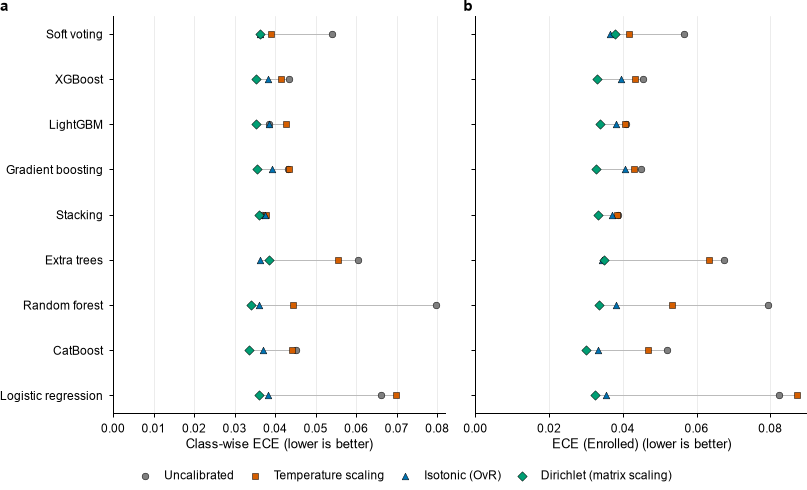

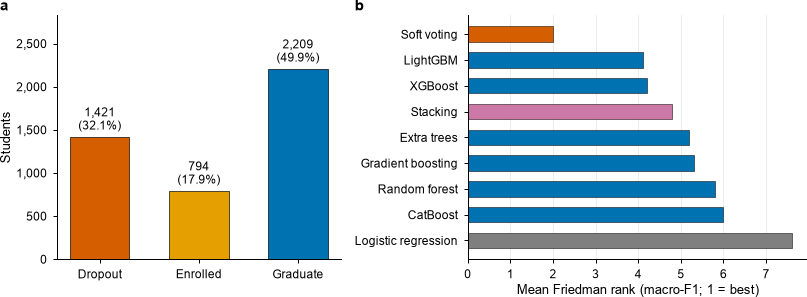

In [10]:
# ============================================================
# 8. PI2: CALIBRACIÓN (DESARROLLO)
# ============================================================
CAL_METS = ["brier", "log_loss", "ece", "cw_ece", "ece_Dropout", "ece_Enrolled", "ece_Graduate"]
CM = fold_df.groupby(["model", "calibration"])[CAL_METS + ["f1_macro"]].agg(["mean", "std"])
CM.columns = [f"{a}_{b}" for a, b in CM.columns]
CM = CM.reset_index()
PU = {m: fold_df[fold_df.calibration == "uncalibrated"].pivot(index="block", columns="model", values=m)[MODEL_NAMES]
      for m in ("cw_ece", "ece_Enrolled")}
t4 = []
for m in order_f1:
    r = CM[(CM.model == m) & (CM.calibration == CFG.calibration_primary)].iloc[0]
    row = {"Model": dn(m) + ("*" if m == BEST else "")}
    for c in CAL_METS:
        row[LABELS[c]] = fmt_ms(r[c + "_mean"], r[c + "_std"], 4 if c == "brier" else 3)
    for c in ("cw_ece", "ece_Enrolled"):
        mu, lo, hi, t, p = nb_test(PV[c][m] - PU[c][m])
        row[f"Δ {LABELS[c]} (95% CI)"] = fmt_ci(mu, lo, hi, 3, signed=True)
    t4.append(row)
t4 = pd.DataFrame(t4)
register_table(t4, "Table4_calibration_cv", "4",
               "Probabilistic accuracy and class-wise calibration of the candidates in repeated nested cross-validation "
               "(temperature scaling)",
               f"Mean ± SD over {N_BLOCKS} outer folds; bold, best value per column. Brier: multiclass Brier score (sum over "
               "classes); ECE (top-label): expected calibration error of the predicted class; class-wise ECE: mean of the "
               f"one-vs-rest ECEs; {CFG.ece_bins} equal-width bins. Δ: calibrated − uncalibrated with Nadeau–Bengio corrected "
               "95% CIs (negative values indicate improvement). The temperature was fitted on inner out-of-fold predictions "
               "only. Lower values are better", landscape=True,
               bold=best_cells(t4, cols_min=[LABELS[c] for c in CAL_METS]))
tS5 = []
for m in order_f1:
    sub = CM[CM.model == m].set_index("calibration").reindex(list(CFG.calibration_methods))
    best_m = sub["cw_ece_mean"].idxmin()
    for meth, r in sub.iterrows():
        tS5.append({"Model": dn(m), "Calibration": CAL_LABEL[meth] + (" †" if meth == best_m else ""),
                    "Macro-F1": num(r.f1_macro_mean), "Brier score": num(r.brier_mean, 4), "Log-loss": num(r.log_loss_mean),
                    "ECE (top-label)": num(r.ece_mean), "Class-wise ECE": num(r.cw_ece_mean),
                    "ECE (Enrolled)": num(r.ece_Enrolled_mean)})
register_table(pd.DataFrame(tS5), "TableS5_calibration_methods", "S5",
               "Comparison of calibration methods in repeated nested cross-validation",
               "Means over outer folds; all methods evaluated on the same validation observations. † Lowest class-wise ECE for "
               "the model. Temperature scaling was prespecified as primary because it preserves the predicted class; isotonic "
               "regression was fitted one-vs-rest and renormalised; Dirichlet calibration is a multinomial logistic regression "
               "on log-probabilities (matrix scaling, L2)", supplementary=True, group_col="Model")

ordc = order_f1[::-1]
mk = {"uncalibrated": ("o", C_REF), "temperature": ("s", C_POS), "isotonic": ("^", C_NEG), "dirichlet": ("D", OKABE_ITO["green"])}
fig, axs = new_figure("double", 34 + 8 * len(MODEL_NAMES), ncols=2, sharey=True)
for ax, metric in zip(axs, ["cw_ece", "ece_Enrolled"]):
    for i, m in enumerate(ordc):
        sub = CM[CM.model == m].set_index("calibration")
        xs_ = [sub.loc[mm, metric + "_mean"] for mm in CFG.calibration_methods]
        ax.plot([min(xs_), max(xs_)], [i, i], color="#BBBBBB", lw=0.6, zorder=1)
        for mm in CFG.calibration_methods:
            ax.scatter(sub.loc[mm, metric + "_mean"], i, marker=mk[mm][0], s=16, color=mk[mm][1], edgecolor="black",
                       lw=0.3, zorder=2, label=CAL_LABEL[mm] if i == 0 else None)
    ax.set_xlabel(LABELS[metric] + " (lower is better)"); ax.grid(axis="x", lw=0.4, color=GRID); ax.set_axisbelow(True)
    ax.set_xlim(left=0)
axs[0].set_yticks(range(len(ordc)), [dn(m) for m in ordc])
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
panel_label(axs[0], "a"); panel_label(axs[1], "b")
save_figure(fig, "FigS2_calibration_methods",
            "Fig. S2 Effect of post-hoc calibration in repeated nested cross-validation. a Class-wise expected calibration "
            "error (ECE) and b ECE for the Enrolled class, averaged over outer folds, without calibration and with temperature "
            "scaling (primary), isotonic and Dirichlet calibration", supplementary=True)

fig, (a1, a2) = new_figure("double", 66, ncols=2, gridspec_kw=dict(width_ratios=[1, 1.2]))
cnt3 = pd.Series(np.bincount(y_all, minlength=K), index=CLASSES)
a1.bar(range(K), cnt3.values, color=[C_CLASS[c] for c in CLASSES], width=0.6, edgecolor="black", lw=0.4)
for i, v in enumerate(cnt3.values):
    a1.text(i, v + cnt3.max() * 0.02, f"{v:,}\n({v / N:.1%})", ha="center", va="bottom", fontsize=7)
a1.set_xticks(range(K), CLASSES); a1.set_ylabel("Students"); a1.set_ylim(0, cnt3.max() * 1.28)
a1.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
rk_ = ranks.sort_values()
a2.barh(range(len(rk_)), rk_.values, color=[col_of(m) for m in rk_.index], height=0.6, edgecolor="black", lw=0.3)
a2.set_yticks(range(len(rk_)), [dn(m) for m in rk_.index]); a2.invert_yaxis()
a2.set_xlabel("Mean Friedman rank (macro-F1; 1 = best)"); a2.grid(axis="x", lw=0.4, color=GRID); a2.set_axisbelow(True)
panel_label(a1, "a"); panel_label(a2, "b")
save_figure(fig, "FigS1_outcomes_and_ranks",
            f"Fig. S1 a Distribution of the three academic outcomes (n = {N:,}). b Mean Friedman ranks of the candidates "
            f"across {N_BLOCKS} outer folds (Friedman χ²({k_mod - 1}) = {fr_stat:.2f}, p = {fmt_p(fr_p)}); vermillion, selected "
            "candidate; purple, meta-ensembles; grey, logistic regression reference", supplementary=True)

## 9. Ajuste final de todos los candidatos (solo desarrollo) y punto de congelación

Todos los candidatos se reajustan y recalibran con el conjunto de desarrollo completo y se congelan **antes** de abrir la reserva. Así la reserva evalúa una sola vez a todos los modelos.

In [11]:
# ============================================================
# 9. AJUSTE FINAL Y CONGELACIÓN
# ============================================================
STAGE.start("Final fit on the development set")
FINAL, FINAL_PARAMS, FINAL_SECONDS, base_cache_final = {}, {}, {}, {}
SEED_FINAL = SEED + 12000
cache_reset(PINNED, FIT_CACHE_N, CFG.resample_cache_size)
for name in MODEL_NAMES:
    t0 = time.perf_counter()
    FINAL[name], FINAL_PARAMS[name], _ = fit_candidate(name, X_dev, y_dev, SEED_FINAL, groups=g_dev,
                                                       base_cache=base_cache_final, n_jobs=CFG.n_jobs)
    if name in ENSEMBLES:
        base_cache_final[name] = FINAL_PARAMS[name]
    assert list(FINAL[name].classes_) == list(range(K)), "predict_proba columns must follow CLASSES"
    FINAL_SECONDS[name] = time.perf_counter() - t0
    print(f"final fit: {dn(name):20s} {FINAL_SECONDS[name]:7.0f} s")
print("Cache statistics (final fit):", dict(_store().stats))
cache_reset()                                                   # libera memoria; FINAL conserva sus propios ajustes
joblib.dump(FINAL[BEST], MOD / "final_selected_model.joblib", compress=3)
joblib.dump(FINAL[REF], MOD / "final_reference_lr.joblib", compress=3)
FROZEN = {"selected_model": BEST, "reference": REF, "class_order": CLASSES,
          "hyperparameters": {m: json.loads(short_params(p)) for m, p in FINAL_PARAMS.items()},
          "temperature": {m: FINAL[m].maps_["temperature"].T_ for m in MODEL_NAMES},
          "calibration_primary": CFG.calibration_primary, "resampling": CFG.resampling,
          "decision_rule": "argmax of calibrated probabilities", "frozen_utc": pd.Timestamp.now(tz="UTC").isoformat(),
          "note": "Models were serialised with joblib; reloading requires the class definitions of §4–§5 of this notebook"}
(META / "frozen_configuration_before_holdout.json").write_text(json.dumps(FROZEN, indent=2, default=str), encoding="utf-8")
print(json.dumps({k: v for k, v in FROZEN.items() if k != "hyperparameters"}, indent=2, default=str))
STAGE.stop()

▶ Final fit on the development set
final fit: Random forest             39 s
final fit: Extra trees               66 s
final fit: Gradient boosting         77 s
final fit: XGBoost                   34 s
final fit: LightGBM                  16 s
final fit: CatBoost                 202 s
final fit: Soft voting                1 s
final fit: Stacking                 250 s
final fit: Logistic regression        6 s
Cache statistics (final fit): {'resample_miss': 24, 'fit_store': 16, 'resample_hit': 84, 'fit_hit': 32}
{
  "selected_model": "VotingSoft",
  "reference": "LogisticRegression (reference)",
  "class_order": [
    "Dropout",
    "Enrolled",
    "Graduate"
  ],
  "temperature": {
    "RandomForest": 0.6169827067577266,
    "ExtraTrees": 0.8520093600166067,
    "GradientBoosting": 0.9307270612411304,
    "XGBoost": 1.2615353145912978,
    "LightGBM": 0.9824280521434738,
    "CatBoost": 1.0418308258108255,
    "VotingSoft": 0.813961218036158,
    "Stacking": 0.9715989869412652,
    "Lo

## 10. Apertura única de la reserva bloqueada: PI1 y PI2 en datos no vistos

Ninguna observación de la reserva se ha usado hasta aquí. Los IC 95 % se obtienen por *bootstrap* estratificado por clase, condicional a los modelos congelados. Las diferencias entre el candidato seleccionado y la LR usan remuestreos pareados. Además del ECE, se informan el intercepto (*calibration-in-the-large*) y la pendiente de calibración de cada clase.

▶ Holdout evaluation

Table 5  Performance of all frozen candidates on the locked holdout (n = 885)
              Model        Family Macro-F1 Balanced accuracy   MCC Macro AUC Recall (Enrolled) Brier score Class-wise ECE ECE (Enrolled)
       Soft voting* Meta-ensemble    0.743             0.732 0.662     0.897             0.503      0.3031          0.036          0.026
           Stacking Meta-ensemble    0.733             0.719 0.661     0.896             0.434      0.3019          0.039          0.034
            XGBoost      Ensemble    0.727             0.715 0.650     0.900             0.447      0.2993          0.031          0.023
  Gradient boosting      Ensemble    0.726             0.720 0.634     0.887             0.497      0.3217          0.039          0.042
           LightGBM      Ensemble    0.725             0.716 0.640     0.892             0.465      0.3120          0.040          0.034
           CatBoost      Ensemble    0.723             0.716 0.637     0.891  

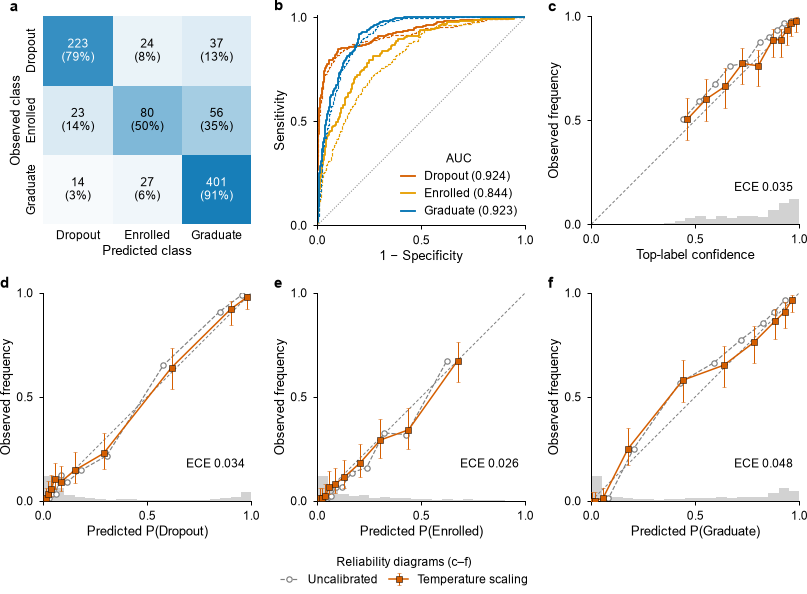

✔ Holdout evaluation: 0.2 min


In [12]:
# ============================================================
# 10. RESERVA: MÉTRICAS, INTERVALOS Y FIGURA 3
# ============================================================
STAGE.start("Holdout evaluation")
t0 = time.perf_counter()
PH = {m: FINAL[m].predict_proba(X_hold) for m in MODEL_NAMES}
infer_s = time.perf_counter() - t0
PH_unc = {m: FINAL[m].predict_proba(X_hold, method="uncalibrated") for m in (BEST, REF)}
P_best, P_ref = PH[BEST], PH[REF]
pd.DataFrame({"row_id": hold_ids, "observed": [CLASSES[i] for i in y_hold],
              **{f"{BEST}_p_{c}": P_best[:, i] for i, c in enumerate(CLASSES)},
              **{f"LR_p_{c}": P_ref[:, i] for i, c in enumerate(CLASSES)}}).to_csv(META / "holdout_predictions.csv", index=False)
MH = {m: mc_metrics(y_hold, PH[m]) for m in MODEL_NAMES}
CH = {m: cal_lr_metrics(y_hold, PH[m]) for m in (BEST, REF)}

t5 = pd.DataFrame([{"Model": dn(m) + ("*" if m == BEST else ""), "Family": family_of(m),
       "Macro-F1": num(MH[m]["f1_macro"]), "Balanced accuracy": num(MH[m]["balanced_accuracy"]), "MCC": num(MH[m]["mcc"]),
       "Macro AUC": num(MH[m]["roc_auc_macro"]), "Recall (Enrolled)": num(MH[m]["recall_Enrolled"]),
       "Brier score": num(MH[m]["brier"], 4), "Class-wise ECE": num(MH[m]["cw_ece"]), "ECE (Enrolled)": num(MH[m]["ece_Enrolled"])}
      for m in sorted(MODEL_NAMES, key=lambda m: -MH[m]["f1_macro"])])
register_table(t5, "Table5_holdout_all", "5", f"Performance of all frozen candidates on the locked holdout (n = {len(y_hold):,})",
               "All candidates were refitted and calibrated (temperature scaling) on the development set and frozen before the "
               "holdout was opened once. Point estimates; bold, best value per column. The selected candidate (*) was chosen "
               "in cross-validation, not on the holdout. ECE, expected calibration error (15 equal-width bins); MCC, Matthews "
               "correlation coefficient", landscape=True,
               bold=best_cells(t5, cols_max=["Macro-F1", "Balanced accuracy", "MCC", "Macro AUC", "Recall (Enrolled)"],
                               cols_min=["Brier score", "Class-wise ECE", "ECE (Enrolled)"]))


def strat_boot_idx(y, B, seed):
    rng = np.random.default_rng(seed); g = [np.where(y == c)[0] for c in range(K)]
    for _ in range(B):
        yield np.concatenate([rng.choice(x, len(x), replace=True) for x in g])


BB, BR, BD = [], [], []
for idx in strat_boot_idx(y_hold, CFG.holdout_bootstrap, SEED + 14000):
    a = {**mc_metrics(y_hold[idx], P_best[idx]), **cal_lr_metrics(y_hold[idx], P_best[idx])}
    b = {**mc_metrics(y_hold[idx], P_ref[idx]), **cal_lr_metrics(y_hold[idx], P_ref[idx])}
    BB.append(a); BR.append(b); BD.append({k_: a[k_] - b[k_] for k_ in a})
BB, BR, BD = pd.DataFrame(BB), pd.DataFrame(BR), pd.DataFrame(BD)
ql, qh = CFG.alpha / 2, 1 - CFG.alpha / 2
fci = lambda est, lo, hi, d=3, signed=False: fmt_ci(est, lo, hi, d, signed)
rows6 = []
SECTIONS6 = [("Discrimination", ["f1_macro", "balanced_accuracy", "mcc", "kappa", "roc_auc_macro", "accuracy", "f1_weighted"]),
             ("Per-class discrimination", ["recall_Dropout", "recall_Enrolled", "recall_Graduate", "precision_Dropout",
                                           "precision_Enrolled", "precision_Graduate", "f1_Dropout", "f1_Enrolled", "f1_Graduate"]),
             ("Probabilistic accuracy and calibration", ["brier", "log_loss", "ece", "cw_ece", "ece_Dropout", "ece_Enrolled",
                                                          "ece_Graduate"]),
             ("Weak calibration, one-vs-rest (ideal: intercept 0, slope 1)",
              [f"{p_}_{c}" for p_ in ("citl", "slope") for c in CLASSES])]
for sec, mets in SECTIONS6:
    for m in mets:
        d = 4 if m == "brier" else 3
        est_b = MH[BEST][m] if m in MH[BEST] else CH[BEST][m]
        est_r = MH[REF][m] if m in MH[REF] else CH[REF][m]
        rows6.append({"Section": sec, "Metric": LABELS[m],
                      dn(BEST): fci(est_b, BB[m].quantile(ql), BB[m].quantile(qh), d, signed=m.startswith("citl")),
                      "LR reference": fci(est_r, BR[m].quantile(ql), BR[m].quantile(qh), d, signed=m.startswith("citl")),
                      f"Δ ({dn(BEST)} − LR)": fci(est_b - est_r, BD[m].quantile(ql), BD[m].quantile(qh), d, signed=True)})
register_table(pd.DataFrame(rows6), "Table6_holdout_selected_vs_lr", "6",
               f"Discrimination and calibration of the frozen {dn(BEST)} and the logistic regression (LR) reference on the "
               f"locked holdout, overall and by class (n = {len(y_hold):,}; Dropout = {int((y_hold == 0).sum())}, Enrolled = "
               f"{int((y_hold == 1).sum())}, Graduate = {int((y_hold == 2).sum())})",
               f"95% CIs from {CFG.holdout_bootstrap:,} bootstrap resamples stratified by class, conditional on the frozen "
               "models (percentile method); Δ from paired resamples. Classes assigned by the highest calibrated probability. "
               "For Brier score, log-loss and ECE, lower is better. Calibration intercept (calibration-in-the-large) and slope "
               "from a one-vs-rest logistic recalibration of logit(p) (Van Calster et al., 2019). ECE, expected calibration "
               "error; MCC, Matthews correlation coefficient", landscape=True, group_col="Section")


def reliability_q(yb, pb, bins=None):
    """Diagrama de fiabilidad con intervalos de igual frecuencia e IC de Wilson al 95 % para la frecuencia observada."""
    bins = bins or CFG.reliability_bins
    yb, pb = np.asarray(yb, float), np.asarray(pb, float)
    edges = np.unique(np.quantile(pb, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.searchsorted(edges[1:-1], pb, side="right"), 0, max(len(edges) - 2, 0))
    out = []
    for b in np.unique(idx):
        s = idx == b; n_ = int(s.sum()); k_ = yb[s].sum(); z = 1.959964
        c_ = (k_ + z * z / 2) / (n_ + z * z); h_ = z * math.sqrt(k_ * (n_ - k_) / n_ + z * z / 4) / (n_ + z * z)
        out.append((pb[s].mean(), k_ / n_, n_, c_ - h_, c_ + h_))
    return np.array(out)


def reliability_panel(ax, yb, pb, pbu, xlabel):
    ax.plot([0, 1], [0, 1], ls=(0, (3, 2)), color=C_REF, lw=0.6, zorder=1)
    h_, e_ = np.histogram(pb, bins=20, range=(0, 1))
    ax.bar(e_[:-1], h_ / max(h_.max(), 1) * 0.12, width=0.05, align="edge", color=tint(C_REF, 0.35), lw=0, zorder=0)
    ru, rc = reliability_q(yb, pbu), reliability_q(yb, pb)
    ax.plot(ru[:, 0], ru[:, 1], "o--", color=C_REF, ms=3.2, mfc="white", mew=0.7, lw=0.7, label="Uncalibrated", zorder=2)
    ax.errorbar(rc[:, 0], rc[:, 1], yerr=[rc[:, 1] - rc[:, 3], rc[:, 4] - rc[:, 1]], fmt="s-", color=C_POS, ms=3.2,
                mec="black", mew=0.3, lw=0.9, elinewidth=0.6, capsize=1.2, label="Temperature scaling", zorder=3)
    ax.set(xlabel=xlabel, ylabel="Observed frequency", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
    ax.text(0.97, 0.16, f"ECE {num(ece_binary(yb, pb))}", transform=ax.transAxes, ha="right", fontsize=7)


fig = new_canvas("double", 128, wspace=0.03, hspace=0.05)
gs = fig.add_gridspec(2, 3)
axs = [fig.add_subplot(gs[i, j]) for i in (0, 1) for j in (0, 1, 2)]
cm = confusion_matrix(y_hold, P_best.argmax(1), labels=range(K)); cr = cm / cm.sum(1, keepdims=True)
axs[0].imshow(cr, cmap=CMAP_SEQ, vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        axs[0].text(j, i, f"{cm[i, j]}\n({cr[i, j]:.0%})", ha="center", va="center", fontsize=7,
                    color="white" if cr[i, j] > 0.55 else "black")
axs[0].set_xticks(range(K), CLASSES); axs[0].set_yticks(range(K), CLASSES, rotation=90, va="center")
axs[0].set_xlabel("Predicted class"); axs[0].set_ylabel("Observed class"); axs[0].tick_params(length=0)
for s_ in axs[0].spines.values():
    s_.set_visible(False)
for i, c in enumerate(CLASSES):
    f_, t_, _ = roc_curve((y_hold == i).astype(int), P_best[:, i])
    axs[1].plot(f_, t_, color=C_CLASS[c], lw=1.1, label=f"{c} ({num(MH[BEST][f'auc_{c}'])})")
    f2, t2_, _ = roc_curve((y_hold == i).astype(int), P_ref[:, i])
    axs[1].plot(f2, t2_, color=C_CLASS[c], lw=0.7, ls=(0, (3, 1.5)))
axs[1].plot([0, 1], [0, 1], ls=":", color=C_REF, lw=0.6)
axs[1].set(xlabel="1 − Specificity", ylabel="Sensitivity", xlim=(0, 1), ylim=(0, 1.01), aspect="equal")
axs[1].set_xticks([0, 0.5, 1]); axs[1].set_yticks([0, 0.5, 1])
axs[1].legend(loc="lower right", title="AUC", handlelength=1.2)
conf_, corr_ = P_best.max(1), (P_best.argmax(1) == y_hold).astype(float)
cu = PH_unc[BEST]
reliability_panel(axs[2], corr_, conf_, cu.max(1), "Top-label confidence")
for i, c in enumerate(CLASSES):
    reliability_panel(axs[3 + i], (y_hold == i).astype(float), P_best[:, i], cu[:, i], f"Predicted P({c})")
fig.legend(*axs[2].get_legend_handles_labels(), loc="outside lower center", ncol=2, title="Reliability diagrams (c–f)")
for ax_, l_ in zip(axs, "abcdef"):
    panel_label(ax_, l_)
save_figure(fig, "Fig3_holdout_discrimination_calibration",
            f"Fig. 3 Discrimination and calibration of the frozen {dn(BEST)} on the locked holdout (n = {len(y_hold):,}). "
            "a Confusion matrix (counts and row percentages). b One-vs-rest ROC curves for each class (solid, selected "
            "candidate, AUC in brackets; dashed, logistic regression reference). c Top-label reliability diagram. d–f "
            "Class-wise reliability diagrams for Dropout, Enrolled and Graduate before (open circles) and after (squares, "
            f"Wilson 95% CIs) temperature scaling, using {CFG.reliability_bins} equal-frequency bins; grey bars, distribution "
            f"of the calibrated probabilities. ECE ({CFG.ece_bins} equal-width bins) refers to the calibrated probabilities. "
            "ECE, expected calibration error")
STAGE.stop()

## 11. Análisis orientado a la decisión (reserva)

Cuando la capacidad de tutoría es limitada, las probabilidades calibradas sirven para **priorizar**. Se ordena a los estudiantes por P(Dropout) y por P(no titularse a tiempo) = P(Dropout) + P(Enrolled), y se evalúa a quiénes se alcanzaría con capacidades del 10, 20 y 30 %. Además se comparan los recuentos esperados por clase (Σ probabilidades) con los observados, un uso directo de la calibración para planificar recursos, y se presenta una curva de decisión exploratoria para el abandono.


Table 7  Capacity-constrained prioritisation of students on the locked holdout
                              Score      Capacity        Model Target captured, % (95% CI) Precision, % (95% CI) Dropouts captured Enrolled captured
              Ranking by P(Dropout)  10% (n = 89)  Soft voting            30.6 (25.3–36.4)      97.8 (92.1–99.7)            87/284             2/159
              Ranking by P(Dropout)  10% (n = 89) LR reference            31.3 (26.0–37.1)    100.0 (95.9–100.0)            89/284             0/159
              Ranking by P(Dropout) 20% (n = 177)  Soft voting            59.2 (53.2–64.9)      94.9 (90.6–97.6)           168/284             9/159
              Ranking by P(Dropout) 20% (n = 177) LR reference            58.8 (52.8–64.6)      94.4 (89.9–97.3)           167/284             9/159
              Ranking by P(Dropout) 30% (n = 266)  Soft voting            79.2 (74.0–83.8)      84.6 (79.7–88.7)           225/284            25/159
              Ranking by P

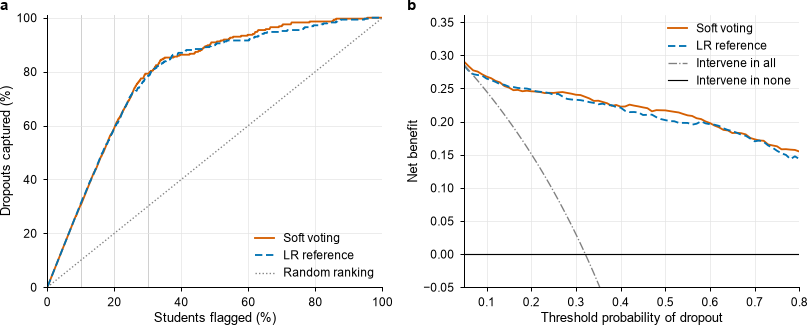

In [13]:
# ============================================================
# 11. DECISIÓN: CAPACIDAD LIMITADA, RECUENTOS ESPERADOS Y CURVA DE DECISIÓN
# ============================================================
from scipy.stats import beta as beta_dist


def clopper(k, n, a=0.05):
    if n == 0:
        return np.nan, np.nan
    return (0.0 if k == 0 else beta_dist.ppf(a / 2, k, n - k + 1)), (1.0 if k == n else beta_dist.ppf(1 - a / 2, k + 1, n - k))


nH = len(y_hold); is_d, is_e = (y_hold == 0), (y_hold == 1)
rows7 = []
for score_name, sc_fn, target in [("P(Dropout)", lambda P: P[:, 0], is_d),
                                  ("P(Dropout) + P(Enrolled)", lambda P: P[:, 0] + P[:, 1], is_d | is_e)]:
    for cap in CFG.capacity_levels:
        n_flag = int(math.ceil(cap * nH))
        for lab, P_ in [(dn(BEST), P_best), ("LR reference", P_ref)]:
            top = np.argsort(-sc_fn(P_), kind="mergesort")[:n_flag]; fl = np.zeros(nH, bool); fl[top] = True
            hit = int((fl & target).sum())
            rows7.append({"Score": f"Ranking by {score_name}", "Capacity": f"{cap:.0%} (n = {n_flag})", "Model": lab,
                          "Target captured, % (95% CI)": fci(hit / target.sum() * 100, *(np.array(clopper(hit, int(target.sum()))) * 100), 1),
                          "Precision, % (95% CI)": fci(hit / n_flag * 100, *(np.array(clopper(hit, n_flag)) * 100), 1),
                          "Dropouts captured": f"{int((fl & is_d).sum())}/{int(is_d.sum())}",
                          "Enrolled captured": f"{int((fl & is_e).sum())}/{int(is_e.sum())}"})
register_table(pd.DataFrame(rows7), "Table7_capacity", "7", "Capacity-constrained prioritisation of students on the locked holdout",
               "Students were ranked by the calibrated probability and the top fraction was flagged for support. Target: "
               "dropouts for P(Dropout); dropouts and still-enrolled students (not graduating on time) for P(Dropout) + "
               "P(Enrolled). Exact Clopper–Pearson 95% CIs. Capacities were prespecified; none was chosen using the holdout",
               landscape=True, group_col="Score")
exp_rows = []
for lab, P_ in [(f"{dn(BEST)} (temperature scaling)", P_best), (f"{dn(BEST)} (uncalibrated)", PH_unc[BEST]), ("LR reference", P_ref)]:
    for i, c in enumerate(CLASSES):
        e_, o_ = P_[:, i].sum(), int((y_hold == i).sum())
        exp_rows.append({"Model": lab, "Class": c, "Observed": o_, "Expected (Σ p)": num(e_, 1), "Expected/observed": num(e_ / o_)})
register_table(pd.DataFrame(exp_rows), "TableS9_expected_vs_observed", "S9",
               "Expected versus observed number of students per class on the holdout",
               "Expected counts are sums of predicted probabilities; ratios close to 1 indicate calibration-in-the-large, "
               "which determines whether probabilities can be used to plan support capacity", supplementary=True, group_col="Model")


def net_benefit(yb, pb, t):
    n = len(yb); tp = ((pb >= t) & (yb == 1)).sum(); fp = ((pb >= t) & (yb == 0)).sum()
    return tp / n - fp / n * t / (1 - t)


fig, (a1, a2) = new_figure("double", 72, ncols=2)
xs = np.arange(1, nH + 1) / nH * 100
for cap in CFG.capacity_levels:
    a1.axvline(cap * 100, color="#C8C8C8", lw=0.5, zorder=0)
for lab, P_, col, ls in [(dn(BEST), P_best, C_POS, "-"), ("LR reference", P_ref, C_NEG, (0, (4, 2)))]:
    o = np.argsort(-P_[:, 0], kind="mergesort"); a1.plot(xs, np.cumsum(is_d[o]) / is_d.sum() * 100, color=col, ls=ls, lw=1.1, label=lab)
a1.plot([0, 100], [0, 100], color=C_REF, ls=":", lw=0.8, label="Random ranking")
a1.set(xlabel="Students flagged (%)", ylabel="Dropouts captured (%)", xlim=(0, 100), ylim=(0, 101)); a1.legend(loc="lower right")
ts = np.round(np.arange(0.05, 0.81, 0.01), 2); yb = is_d.astype(int); prev = yb.mean()
for lab, P_, col, ls in [(dn(BEST), P_best, C_POS, "-"), ("LR reference", P_ref, C_NEG, (0, (4, 2)))]:
    a2.plot(ts, [net_benefit(yb, P_[:, 0], t) for t in ts], color=col, ls=ls, lw=1.1, label=lab)
a2.plot(ts, prev - (1 - prev) * ts / (1 - ts), color=C_REF, ls="-.", lw=0.8, label="Intervene in all")
a2.axhline(0, color="black", lw=0.7, label="Intervene in none")
a2.set(xlabel="Threshold probability of dropout", ylabel="Net benefit", xlim=(0.05, 0.8), ylim=(-0.05, prev + 0.04))
a2.legend(loc="upper right")
for a_ in (a1, a2):
    a_.grid(lw=0.4, color=GRID); a_.set_axisbelow(True)
panel_label(a1, "a"); panel_label(a2, "b")
save_figure(fig, "Fig4_decision",
            f"Fig. 4 Decision-oriented use of calibrated probabilities on the locked holdout. a Cumulative share of dropouts "
            f"captured when students are ranked by P(Dropout) ({dn(BEST)}, solid; logistic regression reference, dashed); "
            "vertical lines mark the prespecified capacities. b Exploratory decision curve for intervening in students at "
            "predicted risk of dropout (one-vs-rest)")

## 12. Desempeño y calibración por subgrupos (reserva)

Comprobación exploratoria de equidad: el desempeño agregado puede ocultar errores desiguales (Elsayed et al., 2026). Se informan los niveles con n ≥ `subgroup_min_n` (Tabla S6 y gráfico de bosque de la Fig. S3).


Table S6  Performance and calibration of the frozen Soft voting by subgroup (holdout)
          Subgroup      Level   n   Macro-F1 (95% CI) Recall Dropout Recall Enrolled Recall Graduate Brier score Class-wise ECE
            Gender     Female 580 0.754 (0.710–0.792)          0.748           0.515           0.938      0.2883          0.038
            Gender       Male 305 0.708 (0.655–0.763)          0.823           0.483           0.811      0.3312          0.054
Scholarship holder         No 674 0.740 (0.706–0.777)          0.821           0.522           0.863      0.3184          0.044
Scholarship holder        Yes 211 0.678 (0.584–0.772)          0.500           0.381           0.987      0.2542          0.057
  Age at enrolment > 20 years 357 0.766 (0.710–0.817)          0.877           0.517           0.891      0.2702          0.048
  Age at enrolment ≤ 20 years 528 0.711 (0.667–0.757)          0.664           0.495           0.915      0.3253          0.047
         Displace

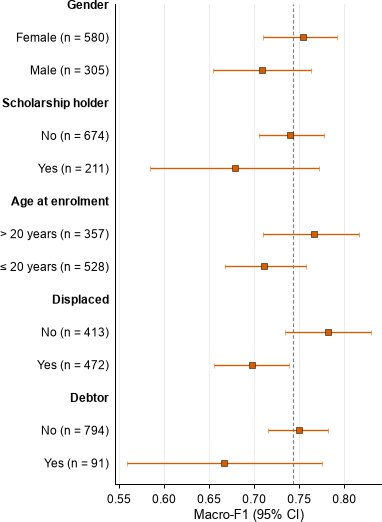

In [14]:
# ============================================================
# 12. SUBGRUPOS
# ============================================================
SUBG = {"Gender": X_hold["Gender"].map({0.0: "Female", 1.0: "Male"}),
        "Scholarship holder": X_hold["Scholarship holder"].map({0.0: "No", 1.0: "Yes"}),
        "Age at enrolment": np.where(X_hold["Age at enrollment"] <= 20, "≤ 20 years", "> 20 years"),
        "Displaced": X_hold["Displaced"].map({0.0: "No", 1.0: "Yes"}),
        "Debtor": X_hold["Debtor"].map({0.0: "No", 1.0: "Yes"})}
rowsS, forest = [], []
for var, lev in SUBG.items():
    lev = pd.Series(lev).astype(str).to_numpy()
    for L in sorted(set(lev)):
        msk = lev == L; n_ = int(msk.sum())
        if n_ < CFG.subgroup_min_n or len(np.unique(y_hold[msk])) < K:
            rowsS.append({"Subgroup": var, "Level": L, "n": n_, "Macro-F1 (95% CI)": "NE"}); continue
        mm = mc_metrics(y_hold[msk], P_best[msk])
        bs = np.array([mc_metrics(y_hold[msk][i], P_best[msk][i])["f1_macro"]
                       for i in strat_boot_idx(y_hold[msk], max(200, CFG.holdout_bootstrap // 5), SEED + 16000)])
        lo_, hi_ = np.quantile(bs, ql), np.quantile(bs, qh)
        forest.append({"var": var, "level": L, "n": n_, "est": mm["f1_macro"], "lo": lo_, "hi": hi_})
        rowsS.append({"Subgroup": var, "Level": L, "n": n_, "Macro-F1 (95% CI)": fci(mm["f1_macro"], lo_, hi_),
                      "Recall Dropout": num(mm["recall_Dropout"]), "Recall Enrolled": num(mm["recall_Enrolled"]),
                      "Recall Graduate": num(mm["recall_Graduate"]), "Brier score": num(mm["brier"], 4),
                      "Class-wise ECE": num(mm["cw_ece"])})
tS6 = pd.DataFrame(rowsS).fillna("")
register_table(tS6, "TableS6_subgroups", "S6", f"Performance and calibration of the frozen {dn(BEST)} by subgroup (holdout)",
               f"Exploratory fairness check; levels with n < {CFG.subgroup_min_n} or without all three classes are not "
               "estimated (NE). 95% CIs from bootstrap resamples stratified by class within the subgroup. Subgroup estimates "
               "are imprecise and should not be over-interpreted", supplementary=True, group_col="Subgroup")

if forest:
    fo = pd.DataFrame(forest)
    fig, ax = new_figure("single", 16 + 6.5 * (len(fo) + fo["var"].nunique()))
    ypos, labels_, y_ = [], [], 0
    for var, g in fo.groupby("var", sort=False):
        labels_.append((y_, var, True)); y_ += 1
        for _, r in g.iterrows():
            ypos.append(y_); labels_.append((y_, f"{r.level} (n = {r.n})", False)); y_ += 1
    ax.axvline(MH[BEST]["f1_macro"], color=C_REF, ls=(0, (3, 2)), lw=0.7, zorder=0)
    ax.errorbar(fo.est, ypos, xerr=[fo.est - fo.lo, fo.hi - fo.est], fmt="s", ms=3.5, color=C_POS, mec="black", mew=0.3,
                elinewidth=0.8, capsize=1.5)
    ax.set_yticks([p for p, _, _ in labels_], [t for _, t, _ in labels_])
    for tl, (_, _, hdr) in zip(ax.get_yticklabels(), labels_):
        tl.set_fontweight("bold" if hdr else "normal")
    ax.tick_params(axis="y", length=0); ax.invert_yaxis()
    ax.set_xlabel("Macro-F1 (95% CI)"); ax.grid(axis="x", lw=0.4, color=GRID); ax.set_axisbelow(True)
    save_figure(fig, "FigS3_subgroups",
                f"Fig. S3 Macro-F1 of the frozen {dn(BEST)} by subgroup on the locked holdout with stratified bootstrap 95% "
                "CIs; dashed line, overall holdout macro-F1. Exploratory analysis", supplementary=True)

## 13. Análisis de sensibilidad preespecificados (conjunto de desarrollo)

* **Horizonte de predicción:** solo matrícula / + 1.er semestre / fin del 1.er año (Martins et al., 2023; Berens et al., 2026). El modelo se reajusta y recalibra en cada pliegue.
* **Tratamiento del desbalance:** SMOTENC (primario) frente a sobremuestreo aleatorio y ausencia de remuestreo (Cho et al., 2023; Mduma, 2023), también con reajuste en cada pliegue.

`SENS_MODEL` es por defecto el candidato seleccionado. Los ajustes (configuración × pliegue) son independientes y se ejecutan en paralelo; el resultado se guarda en caché.

▶ Sensitivity analyses


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:  6.9min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed: 15.2min
[Parallel(n_jobs=8)]: Done  13 out of  25 | elapsed: 16.4min remaining: 15.2min
[Parallel(n_jobs=8)]: Done  16 out of  25 | elapsed: 18.2min remaining: 10.3min
[Parallel(n_jobs=8)]: Done  19 out of  25 | elapsed: 22.3min remaining:  7.1min
[Parallel(n_jobs=8)]: Done  22 out of  25 | elapsed: 23.5min remaining:  3.2min
[Parallel(n_jobs=8)]: Done  25 out of  25 | elapsed: 25.9min finished



Table 9  Prespecified sensitivity analyses for Soft voting (development set)
          Analysis                   Setting      Macro-F1           MCC     Macro AUC Recall Dropout Recall Enrolled Recall Graduate     Brier score Class-wise ECE
Prediction horizon            Enrolment only 0.575 ± 0.016 0.406 ± 0.028 0.784 ± 0.015  0.645 ± 0.061   0.346 ± 0.054   0.732 ± 0.021 0.4730 ± 0.0178  0.062 ± 0.007
Prediction horizon  Enrolment + 1st semester 0.692 ± 0.014 0.593 ± 0.020 0.871 ± 0.013  0.731 ± 0.032   0.466 ± 0.034   0.868 ± 0.029 0.3494 ± 0.0166  0.050 ± 0.006
Prediction horizon End of first year (all) † 0.722 ± 0.019 0.636 ± 0.019 0.895 ± 0.012  0.757 ± 0.038   0.510 ± 0.063   0.887 ± 0.025 0.3113 ± 0.0165  0.042 ± 0.007
Imbalance handling         SMOTENC (primary) 0.722 ± 0.019 0.636 ± 0.019 0.895 ± 0.012  0.757 ± 0.038   0.510 ± 0.063   0.887 ± 0.025 0.3113 ± 0.0165  0.042 ± 0.007
Imbalance handling       Random oversampling 0.719 ± 0.016 0.624 ± 0.020 0.893 ± 0.013  0.717 ± 0

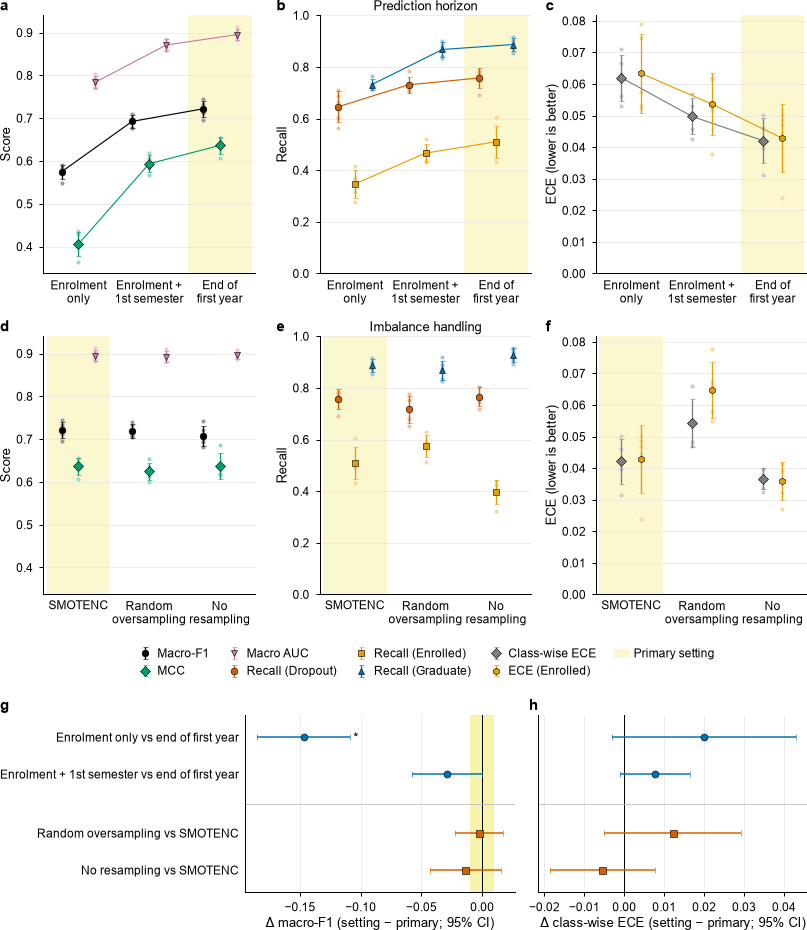

✔ Sensitivity analyses: 26.0 min


In [15]:
# ============================================================
# 13. SENSIBILIDAD — Tabla 9, Tabla S10 (contrastes pareados) y Fig. 7
# ============================================================
STAGE.start("Sensitivity analyses")
SENS_MODEL = BEST
s_splits = [sp for r in range(CFG.sensitivity_repeats) for sp in gsplits(CFG.sensitivity_splits, y_dev, g_dev, SEED + 300 + r)]
settings = [("Prediction horizon", nm, cols, CFG.resampling) for nm, cols in PRED_SETS.items()] + \
           [("Imbalance handling", lab, COLS, rs) for lab, rs in [("SMOTENC (primary)", CFG.resampling),
                                                                    ("Random oversampling", "random_oversampling"),
                                                                    ("No resampling", "none")]]
ANALYSES = ["Prediction horizon", "Imbalance handling"]
PRIMARY = {"Prediction horizon": "End of first year (all)", "Imbalance handling": "SMOTENC (primary)"}
uniq = list(dict.fromkeys((tuple(cols), rs) for _, _, cols, rs in settings))   # fin del 1.er año + SMOTENC se ajusta una vez


def run_sens(u, b):
    cols, rs = list(uniq[u][0]), uniq[u][1]
    tr, va = s_splits[b]
    cache_reset(PINNED, FIT_CACHE_N, CFG.resample_cache_size)
    cal, *_ = fit_candidate(SENS_MODEL, X_dev.iloc[tr], y_dev[tr], SEED + 20000 + 100 * b, cols=cols, resampling=rs,
                            groups=g_dev[tr], n_jobs=1)
    out = {"u": u, "fold": b + 1, **mc_metrics(y_dev[va], cal.predict_proba(X_dev.iloc[va]))}
    cache_reset()
    return out


sens_cache = MOD / f"sensitivity_{KEY_HASH}_{SENS_MODEL}_{CFG.sensitivity_splits}x{CFG.sensitivity_repeats}.joblib"
tasks = [(u, b) for u in range(len(uniq)) for b in range(len(s_splits))]
if CFG.reuse_cache and sens_cache.exists():
    sens_raw = joblib.load(sens_cache); print("Sensitivity analyses loaded from cache")
else:
    sens_raw = Parallel(n_jobs=min(N_WORKERS, len(tasks)), verbose=10)(delayed(run_sens)(u, b) for u, b in tasks)
    joblib.dump(sens_raw, sens_cache)
by_u = pd.DataFrame(sens_raw)
sens = pd.concat([by_u[by_u.u == uniq.index((tuple(cols), rs))].assign(Analysis=an, Setting=st)
                  for an, st, cols, rs in settings], ignore_index=True).drop(columns="u")


def fold_values(an, st, m):
    """Valores por pliegue ordenados por pliegue (todos los ajustes usan las MISMAS particiones: diseño pareado)."""
    return sens[(sens.Analysis == an) & (sens.Setting == st)].sort_values("fold")[m].to_numpy()


# ---------------------------------------------------------------- Tabla 9 (media ± DE; negrita = mejor por análisis)
T9_METS = [("f1_macro", "Macro-F1", "max", 3), ("mcc", "MCC", "max", 3), ("roc_auc_macro", "Macro AUC", "max", 3),
           ("recall_Dropout", "Recall Dropout", "max", 3), ("recall_Enrolled", "Recall Enrolled", "max", 3),
           ("recall_Graduate", "Recall Graduate", "max", 3), ("brier", "Brier score", "min", 4),
           ("cw_ece", "Class-wise ECE", "min", 3)]
t9, bold9 = [], set()
for an in ANALYSES:
    sts = [st for a_, st, *_ in settings if a_ == an]
    first = len(t9)
    for st in sts:
        row = {"Analysis": an, "Setting": st + (" †" if st == PRIMARY[an] and "primary" not in st else "")}
        for m, lab, _, d in T9_METS:
            v = fold_values(an, st, m)
            row[lab] = fmt_ms(v.mean(), v.std(ddof=1), d) if len(v) > 1 else num(v.mean(), d)
        t9.append(row)
    for m, lab, direction, _ in T9_METS:                   # mejor valor dentro de cada análisis
        means = np.array([fold_values(an, st, m).mean() for st in sts])
        best = np.nanmax(means) if direction == "max" else np.nanmin(means)
        bold9 |= {(first + i, lab) for i in np.where(np.isclose(means, best))[0]}
register_table(pd.DataFrame(t9), "Table9_sensitivity", "9", f"Prespecified sensitivity analyses for {dn(SENS_MODEL)} (development set)",
               f"Mean ± SD over {len(s_splits)} folds of stratified, profile-grouped cross-validation; bold, best value within "
               "each analysis; † primary setting. In every setting the model was re-tuned and re-calibrated (temperature "
               "scaling) within each training fold. Enrolment-only predictors exclude all curricular-unit variables; the "
               "first-semester horizon adds the six first-semester variables. Paired contrasts against the primary setting "
               "are reported in Table S10. For Brier score and ECE, lower is better",
               landscape=True, group_col="Analysis", bold=bold9)

# ---------------------------------------------------------------- Tabla S10: contrastes pareados frente al ajuste primario
SENS_RATIO = 1 / (CFG.sensitivity_splits - 1)             # n_test / n_train de la CV de sensibilidad


def nb_paired(d, ratio=SENS_RATIO):
    """t corregido de Nadeau–Bengio sobre diferencias pareadas por pliegue: media, IC 95 % y p."""
    d = np.asarray(d, float); n = len(d); mu = float(d.mean())
    v = d.var(ddof=1) if n > 1 else np.nan
    se = math.sqrt((1 / n + ratio) * v) if n > 1 and v > 0 else np.nan
    if not np.isfinite(se):
        return mu, np.nan, np.nan, np.nan
    tq = stats.t.ppf(1 - CFG.alpha / 2, n - 1)
    return mu, mu - tq * se, mu + tq * se, float(2 * stats.t.sf(abs(mu / se), n - 1))


CONTRASTS = [(an, st) for an, st, *_ in settings if st != PRIMARY[an]]
DELTA_METS = ["f1_macro", "recall_Enrolled", "cw_ece"]
CLAB = {"Enrolment only": "Enrolment only vs end of first year",
        "Enrolment + 1st semester": "Enrolment + 1st semester vs end of first year",
        "Random oversampling": "Random oversampling vs SMOTENC", "No resampling": "No resampling vs SMOTENC"}
dl = []
for m in DELTA_METS:
    r_ = []
    for an, st in CONTRASTS:
        mu, lo, hi, p = nb_paired(fold_values(an, st, m) - fold_values(an, PRIMARY[an], m))
        r_.append({"metric": m, "analysis": an, "setting": st, "diff": mu, "lo": lo, "hi": hi, "p": p})
    r_ = pd.DataFrame(r_); r_["p_holm"] = holm(r_.p.fillna(1.0).to_numpy()); dl.append(r_)
sens_delta = pd.concat(dl, ignore_index=True)
tS10 = pd.DataFrame([{"Analysis": an, "Contrast": CLAB.get(st, st), "Metric": LABELS[m],
                      "Mean difference (95% CI)": fmt_ci(r["diff"], r.lo, r.hi, 3, signed=True),
                      "p": fmt_p(r.p), "Holm p": fmt_p(r.p_holm)}
                     for an in ANALYSES for st in [s for a_, s in CONTRASTS if a_ == an] for m in DELTA_METS
                     for _, r in sens_delta[(sens_delta.analysis == an) & (sens_delta.setting == st) &
                                            (sens_delta.metric == m)].iterrows()])
register_table(tS10, "TableS10_sensitivity_contrasts", "S10",
               f"Paired differences between each sensitivity setting and the primary setting ({dn(SENS_MODEL)}, development set)",
               f"Differences (setting − primary) across the same {len(s_splits)} folds; Nadeau–Bengio corrected t test "
               f"(n_test/n_train = {SENS_RATIO:.2f}) with Holm adjustment within each metric over the "
               f"{len(CONTRASTS)} contrasts. For class-wise ECE, negative differences indicate better calibration. "
               "Cross-validation folds are not independent, so the tests are approximate",
               supplementary=True, group_col="Analysis")

# ---------------------------------------------------------------- Figura 7 (múltiplos pequeños + contrastes pareados)
FAMILIES = [("Discrimination", "Score", [("f1_macro", "o", OKABE_ITO["black"]), ("mcc", "D", OKABE_ITO["green"]),
                                         ("roc_auc_macro", "v", OKABE_ITO["purple"])]),
            ("Recall by class", "Recall", [(f"recall_{c}", M_CLASS[c], C_CLASS[c]) for c in CLASSES]),
            ("Calibration error", "ECE (lower is better)", [("cw_ece", "D", C_REF), ("ece_Enrolled", "h", C_CLASS["Enrolled"])])]
TICKS = {"Enrolment only": "Enrolment\nonly", "Enrolment + 1st semester": "Enrolment +\n1st semester",
         "End of first year (all)": "End of\nfirst year", "SMOTENC (primary)": "SMOTENC",
         "Random oversampling": "Random\noversampling", "No resampling": "No\nresampling"}
BAND = tint(OKABE_ITO["yellow"], 0.25)

fig = new_canvas("double", 200, wspace=0.03, hspace=0.025)
gs = fig.add_gridspec(4, 3, height_ratios=[1, 1, 0.17, 0.95])
axes = np.empty((2, 3), dtype=object)
for r in range(2):
    for c in range(3):
        axes[r, c] = fig.add_subplot(gs[r, c], sharey=axes[0, c] if r else None)
handles = {}
for r, an in enumerate(ANALYSES):
    st_ = [st for a_, st, *_ in settings if a_ == an]; xs_ = np.arange(len(st_)); ip = st_.index(PRIMARY[an])
    for c, (fam, ylab, mets) in enumerate(FAMILIES):
        ax = axes[r, c]
        ax.axvspan(ip - 0.45, ip + 0.45, color=BAND, lw=0, zorder=0)
        w = 0.24 if len(mets) == 3 else 0.28
        for j, (m, mk_, col) in enumerate(mets):
            off = (j - (len(mets) - 1) / 2) * w
            vals = [fold_values(an, s_, m) for s_ in st_]
            for i, v in enumerate(vals):                                  # pliegues individuales
                ax.scatter(np.full(len(v), i + off), v, s=6, color=tint(col, 0.40), lw=0, zorder=2)
            mu = np.array([v.mean() for v in vals]); sd = np.array([v.std(ddof=1) if len(v) > 1 else 0.0 for v in vals])
            if an == "Prediction horizon":                                # eje ordinal: se unen las medias
                ax.plot(xs_ + off, mu, "-", color=col, lw=0.7, zorder=3)
            handles.setdefault(m, ax.errorbar(xs_ + off, mu, yerr=sd, fmt=mk_, ms=4, color=col, mec="black", mew=0.35,
                                              elinewidth=0.8, capsize=1.5, zorder=4))
        ax.set_xticks(xs_, [TICKS.get(s_, s_) for s_ in st_]); ax.set_xlim(-0.5, len(st_) - 0.5)
        ax.tick_params(axis="x", length=0); ax.set_ylabel(ylab)
        ax.grid(axis="y", lw=0.4, color=GRID); ax.set_axisbelow(True)
        if c == 1:
            ax.set_title(an)
axes[0, 1].set_ylim(0, 1.0)
axes[0, 2].set_ylim(bottom=0)
for (r, c), letter in zip([(r, c) for r in range(2) for c in range(3)], "abcdef"):
    panel_label(axes[r, c], letter)
# fila de leyenda común (fuera de los datos)
lax = fig.add_subplot(gs[2, :]); lax.axis("off")
order_h = [m for _, _, mets in FAMILIES for m, *_ in mets]
lax.legend([handles[m] for m in order_h] + [mpl.patches.Patch(color=BAND)],
           [LABELS[m] for m in order_h] + ["Primary setting"], loc="center", ncol=5, handletextpad=0.4,
           columnspacing=1.4, handlelength=1.4)
# contrastes pareados frente al ajuste primario
fg = gs[3, :].subgridspec(1, 2)
ag = fig.add_subplot(fg[0, 0]); ah = fig.add_subplot(fg[0, 1], sharey=ag)
YPOS, y_ = {}, 0.0
for an in ANALYSES:
    for a_, st in CONTRASTS:
        if a_ == an:
            YPOS[(an, st)] = y_; y_ += 1
    y_ += 0.6
AN_STYLE = {"Prediction horizon": (OKABE_ITO["blue"], "o"), "Imbalance handling": (OKABE_ITO["vermillion"], "s")}


def forest(ax, metric, xlabel, rope=None):
    q = sens_delta[sens_delta.metric == metric]
    if rope:
        ax.axvspan(-rope, rope, color=tint(OKABE_ITO["yellow"], 0.45), lw=0, zorder=0)
    ax.axvline(0, color="black", lw=0.6, zorder=1)
    for _, r in q.iterrows():
        y0 = YPOS[(r.analysis, r.setting)]; col, mk_ = AN_STYLE[r.analysis]
        err = [[r["diff"] - r.lo], [r.hi - r["diff"]]] if np.isfinite(r.lo) else None
        ax.errorbar(r["diff"], y0, xerr=err, fmt=mk_, ms=4.2, color=col, mec="black", mew=0.35, elinewidth=0.9,
                    capsize=1.8, zorder=3)
        if np.isfinite(r.p_holm) and r.p_holm < CFG.alpha:
            ax.annotate("*", (r.hi if np.isfinite(r.hi) else r["diff"], y0), xytext=(2, -1), textcoords="offset points",
                        va="center", fontsize=8)
    sep = max(v for (a_, _), v in YPOS.items() if a_ == ANALYSES[0]) + 0.8
    ax.axhline(sep, color="#BBBBBB", lw=0.5, zorder=1)
    ax.set_xlabel(xlabel); ax.grid(axis="x", lw=0.4, color=GRID); ax.set_axisbelow(True)


forest(ag, "f1_macro", "Δ macro-F1 (setting − primary; 95% CI)", rope=CFG.practical_margin_f1m)
forest(ah, "cw_ece", "Δ class-wise ECE (setting − primary; 95% CI)")
ag.set_yticks(list(YPOS.values()), [CLAB.get(st, st) for (_, st) in YPOS])
ag.set_ylim(max(YPOS.values()) + 0.6, -0.6); ag.tick_params(axis="y", length=0)
ah.tick_params(axis="y", labelleft=False, length=0)
panel_label(ag, "g"); panel_label(ah, "h")
save_figure(fig, "Fig7_sensitivity",
            f"Fig. 7 Prespecified sensitivity analyses for {dn(SENS_MODEL)} in profile-grouped cross-validation on the "
            f"development set ({len(s_splits)} folds). a–c Prediction horizon and d–f imbalance handling: discrimination "
            "(macro-F1, Matthews correlation coefficient and macro AUC), recall by class, and calibration error (class-wise "
            "ECE and ECE for Enrolled; lower is better). Light dots, individual folds; markers and whiskers, mean ± SD; "
            "shaded column, primary setting. g, h Paired differences between each setting and the primary setting in "
            f"macro-F1 and class-wise ECE with Nadeau–Bengio corrected 95% CIs; shaded band in g, practical margin "
            f"(± {CFG.practical_margin_f1m:.2f}); * Holm-adjusted p < 0.05 (Table S10). The model was re-tuned and "
            "re-calibrated within every training fold. AUC, area under the ROC curve; ECE, expected calibration error")
STAGE.stop()

## 14. PI3 — Explicabilidad *post hoc* con control de fidelidad, concordancia y estabilidad

Todas las explicaciones se calculan sobre **las probabilidades calibradas** del modelo congelado, a nivel de variable original y con la misma función de predicción (verificada).

* **Global:** SHAP por clase (explicador por permutación, agnóstico al modelo) e importancia por permutación (Δ log-loss).
* **Local:** LIME (nominales y binarias como categóricas) para la clase predicha, interpretable solo si R² local ≥ 0.50.
* **Consistencia:** concordancia de rankings SHAP–permutación–LIME (τ de Kendall, Jaccard top-10); estabilidad *bootstrap* de SHAP; estabilidad entre los mejores modelos; acuerdo local SHAP–LIME en los mismos estudiantes (Lu et al., 2026).

SHAP se calcula en una sola pasada para la muestra global, los casos LIME y el caso de la Fig. 6.

▶ Explainability

Table 8  Most influential predictors of the calibrated probabilities of the frozen Soft voting (holdout)
                             Predictor Mean |SHAP| × 100 (all classes) Mean |SHAP| × 100 (Dropout) Mean |SHAP| × 100 (Enrolled) Mean |SHAP| × 100 (Graduate) Top-10 in SHAP bootstrap (%) Permutation Δ log-loss (95% range) In LIME top-10 (% of cases)
   Curricular units 2nd sem (approved)                           11.83                       13.44                         5.86                        16.18                          100             0.2421 (0.2185–0.2748)                          93
   Curricular units 1st sem (approved)                            5.95                        4.75                         4.35                         8.74                          100             0.0666 (0.0544–0.0786)                          97
               Tuition fees up to date                            4.02                        6.03                         2.57   

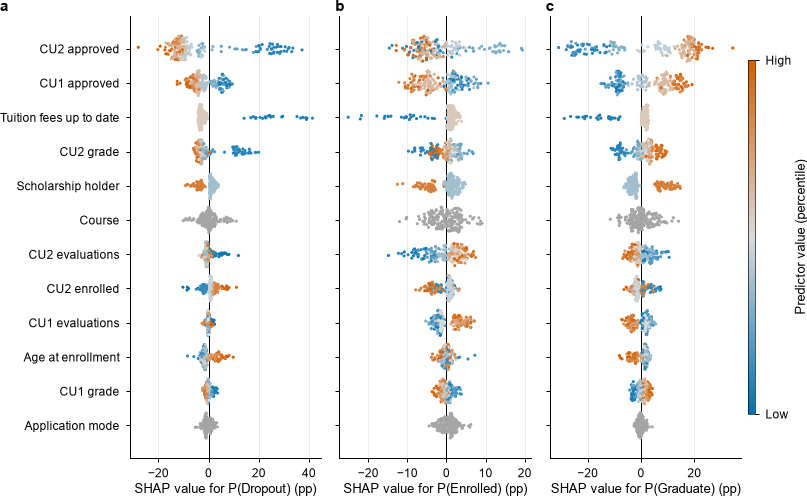

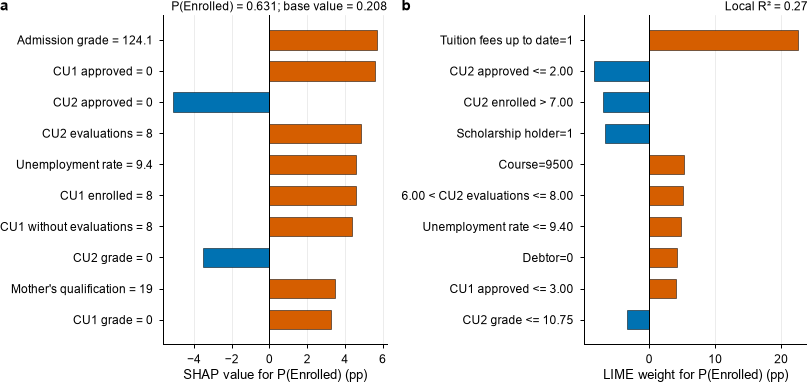

{'SHAP': 'permutation explainer; 200 students; background 100; 145 evaluations per student; bootstrap τ median 0.96', 'LIME': 'median R² 0.342; not reportable (low fidelity)'}
✔ Explainability: 7.8 min


In [16]:
# ============================================================
# 14. PI3: EXPLICABILIDAD
# ============================================================
STAGE.start("Explainability")
EXPL, FM = {}, FINAL[BEST]


def num_view(X):
    D = X[COLS].copy()
    for c in NOMINAL:
        D[c] = D[c].astype(float)
    return D.astype(float)


def from_num(A):
    D = pd.DataFrame(np.asarray(A, float), columns=COLS)
    for c in NOMINAL:
        D[c] = D[c].round().astype(int).astype(str).astype(object)
    return D


f_proba = lambda A: FM.predict_proba(from_num(A))
assert np.allclose(f_proba(num_view(X_hold.iloc[:50]).values), FM.predict_proba(X_hold.iloc[:50]), atol=1e-10), \
    "Prediction function differs from the frozen pipeline"
kt = lambda a, b: float(stats.kendalltau(a, b)[0])
jac = lambda a, b: len(set(a) & set(b)) / len(set(a) | set(b))
topk = lambda v, k=10: list(np.argsort(-np.asarray(v))[:k])


def perm_importance(model, X, y, reps, seed):
    """Importancia por permutación (Δ log-loss) con predicción por lotes: todas las repeticiones de una variable se
    evalúan en una sola llamada a predict_proba (mucho más rápido que permutation_importance para metaensambles)."""
    rng = np.random.default_rng(seed); Xv = X[COLS].reset_index(drop=True); n = len(Xv)
    base = nll(y, model.predict_proba(Xv)); out = np.zeros((len(COLS), reps))
    for j, c in enumerate(COLS):
        big = pd.concat([Xv] * reps, ignore_index=True)
        big[c] = np.concatenate([Xv[c].to_numpy()[rng.permutation(n)] for _ in range(reps)])
        Pb = model.predict_proba(big)
        out[j] = [nll(y, Pb[r * n:(r + 1) * n]) - base for r in range(reps)]
    return out


pi = perm_importance(FM, X_hold, y_hold, CFG.perm_repeats, SEED)
imp = pd.DataFrame({"perm": pi.mean(1), "perm_lo": np.percentile(pi, 2.5, axis=1), "perm_hi": np.percentile(pi, 97.5, axis=1)},
                   index=COLS)
stab_models = [BEST] + [m for m in summary[summary.model.isin(CANDIDATES)].sort_values("f1_macro_mean", ascending=False).model
                        if m != BEST][:CFG.stability_models - 1]
cross = []
for m in stab_models[1:]:
    v = perm_importance(FINAL[m], X_hold, y_hold, max(5, CFG.perm_repeats // 2), SEED).mean(1)
    cross.append({"Comparison": f"{dn(BEST)} vs {dn(m)}", "Kendall τ (all predictors)": num(kt(imp.perm, v), 2),
                  "Top-10 overlap (Jaccard)": num(jac(topk(imp.perm), topk(v)), 2)})

# --- Estudiantes a explicar: muestra global, casos LIME y caso de la Fig. 6 (SHAP se calcula UNA sola vez para todos) ---
rng_e = np.random.default_rng(SEED + 1)
EXi = np.sort(rng_e.choice(len(X_hold), min(CFG.shap_explain, len(X_hold)), replace=False))
rng_l = np.random.default_rng(SEED + 31); per = int(math.ceil(CFG.lime_cases / K))
cases = np.concatenate([rng_l.choice(np.where(y_hold == i)[0], min(per, int((y_hold == i).sum())), replace=False) for i in range(K)])
ok_e = np.where((y_hold == 1) & (P_best.argmax(1) == 1))[0]
CASE = int(ok_e[np.argmin(np.abs(P_best[ok_e, 1] - np.median(P_best[ok_e, 1])))]) if len(ok_e) \
    else int(np.argmax(np.where(y_hold == 1, P_best[:, 1], -1)))
ALL_EX = np.unique(np.r_[EXi, cases, CASE])
pos_of = {r: i for i, r in enumerate(ALL_EX)}

# --- SHAP por clase ---
SV = SV_ALL = BASE_ALL = None
if shap is not None:
    try:
        bg = num_view(X_dev.sample(min(CFG.shap_background, len(X_dev)), random_state=SEED))
        explainer = shap.PermutationExplainer(f_proba, shap.maskers.Independent(bg.values), seed=SEED)
        MAXE = 2 * len(COLS) + 1 if QUICK else 4 * len(COLS) + 1
        sv_all = explainer(num_view(X_hold.iloc[ALL_EX]).values, max_evals=MAXE, silent=True)
        SV_ALL = np.asarray(sv_all.values); SV_ALL = SV_ALL[:, :, None] if SV_ALL.ndim == 2 else SV_ALL
        BASE_ALL = np.asarray(sv_all.base_values).reshape(len(ALL_EX), -1)
        SV = SV_ALL[[pos_of[r] for r in EXi]]
        np.save(META / "shap_values_holdout.npy", SV)
        shap_cls = np.abs(SV).mean(0); imp["shap"] = shap_cls.mean(1)
        for i, c in enumerate(CLASSES):
            imp[f"shap_{c}"] = shap_cls[:, i]
        rng = np.random.default_rng(SEED + 40); taus, keep10 = [], np.zeros(len(COLS))
        for _ in range(CFG.shap_bootstrap):
            ib = rng.integers(0, len(SV), len(SV)); ob = np.abs(SV[ib]).mean(0).mean(1)
            taus.append(kt(imp.shap, ob)); keep10[topk(ob)] += 1
        imp["shap_top10_freq"] = keep10 / CFG.shap_bootstrap
        EXPL["SHAP"] = (f"permutation explainer; {len(SV)} students; background {len(bg)}; {MAXE} evaluations per student; "
                        f"bootstrap τ median {np.median(taus):.2f}")
    except Exception as e:
        EXPL["SHAP"] = f"failed: {e!r}"; print("[SHAP warning]", repr(e)); SV = SV_ALL = None
else:
    EXPL["SHAP"] = "shap not installed"

# --- LIME con control de fidelidad y acuerdo local con SHAP ---
lime_rows, lime_agg, lime_freq = [], np.zeros(len(COLS)), np.zeros(len(COLS))
if LimeTabularExplainer is not None:
    try:
        lime = LimeTabularExplainer(num_view(X_dev).values, feature_names=COLS, class_names=CLASSES,
                                    categorical_features=[COLS.index(c) for c in NOMINAL + BINARY], mode="classification",
                                    random_state=SEED, discretize_continuous=True)
        for i in cases:
            x = num_view(X_hold.iloc[[i]]).values[0]; lab = int(P_best[i].argmax())
            e_ = lime.explain_instance(x, f_proba, labels=(lab,), num_features=10, num_samples=CFG.lime_num_samples)
            sc = e_.score[lab] if isinstance(e_.score, dict) else e_.score
            wmap = dict(e_.as_map()[lab]); fidx = list(wmap); lw = np.array([wmap[f] for f in fidx])
            lime_agg[fidx] += np.abs(lw); lime_freq[fidx] += 1
            row = {"case": int(i), "observed": CLASSES[y_hold[i]], "predicted": CLASSES[lab], "r2": float(sc)}
            if SV_ALL is not None:
                s_ = SV_ALL[pos_of[i], :, lab]; sw = s_[fidx]
                row.update({"spearman_abs": float(stats.spearmanr(np.abs(sw), np.abs(lw))[0]) if len(fidx) >= 3 else np.nan,
                            "sign_agreement": float(np.mean(np.sign(sw) == np.sign(lw))),
                            "top5_jaccard": jac(topk(np.abs(s_), 5), [fidx[j] for j in np.argsort(-np.abs(lw))[:5]])})
            lime_rows.append(row)
        lime_df = pd.DataFrame(lime_rows); lime_df.to_csv(SUP / "lime_cases.csv", index=False)
        imp["lime_freq"] = lime_freq / len(cases); imp["lime_abs"] = lime_agg / len(cases)
        fid = lime_df.r2.to_numpy()
        EXPL["LIME"] = f"median R² {np.median(fid):.3f}; " + ("reportable" if np.median(fid) >= CFG.lime_min_fidelity
                                                             else "not reportable (low fidelity)")
    except Exception as e:
        EXPL["LIME"] = f"failed: {e!r}"; print("[LIME warning]", repr(e)); lime_rows = []
else:
    EXPL["LIME"] = "lime not installed"

# --- Tabla 8: predictores más influyentes y concordancia entre métodos ---
imp = imp.sort_values("shap" if "shap" in imp else "perm", ascending=False)
top = imp.head(15)
t8 = {"Predictor": top.index}
if "shap" in top:
    t8["Mean |SHAP| × 100 (all classes)"] = (top.shap * 100).map(lambda v: num(v, 2))
    for c in CLASSES:
        t8[f"Mean |SHAP| × 100 ({c})"] = (top[f"shap_{c}"] * 100).map(lambda v: num(v, 2))
    t8["Top-10 in SHAP bootstrap (%)"] = (top.shap_top10_freq * 100).map(lambda v: f"{v:.0f}")
t8["Permutation Δ log-loss (95% range)"] = [fmt_ci(a, b, c, 4) for a, b, c in zip(top.perm, top.perm_lo, top.perm_hi)]
if "lime_freq" in top:
    t8["In LIME top-10 (% of cases)"] = (top.lime_freq * 100).map(lambda v: f"{v:.0f}")
conc = []
if "shap" in imp:
    conc.append(("SHAP vs permutation", kt(imp.shap, imp.perm), jac(topk(imp.shap), topk(imp.perm))))
    if "lime_abs" in imp:
        conc.append(("SHAP vs LIME (aggregated)", kt(imp.shap, imp.lime_abs), jac(topk(imp.shap), topk(imp.lime_abs))))
if "lime_abs" in imp:
    conc.append(("Permutation vs LIME (aggregated)", kt(imp.perm, imp.lime_abs), jac(topk(imp.perm), topk(imp.lime_abs))))
conc_txt = "; ".join(f"{a}: τ = {num(b, 2)}, top-10 Jaccard = {num(c, 2)}" for a, b, c in conc) or "not computed"
register_table(pd.DataFrame(t8), "Table8_explainability", "8",
               f"Most influential predictors of the calibrated probabilities of the frozen {dn(BEST)} (holdout)",
               "Mean |SHAP|: mean absolute SHAP value of the calibrated probability of each class (percentage points), "
               "permutation explainer with a development-set background; 'all classes' is the mean over classes. Top-10 in "
               f"SHAP bootstrap: share of {CFG.shap_bootstrap} bootstrap resamples of the explained students in which the "
               "predictor ranked in the top 10. Permutation Δ log-loss: increase in multiclass log-loss after permuting the "
               f"predictor ({CFG.perm_repeats} repeats; 2.5th–97.5th percentiles). LIME top-10: share of explained students "
               f"whose local explanation included the predictor. Global concordance — {conc_txt}. Attributions describe the "
               "fitted model, not causal effects; correlated curricular-unit variables share attribution", landscape=True)
s7 = []
if lime_rows:
    for lab_, g in [("All explained students", lime_df)] + [(f"Predicted {c}", lime_df[lime_df.predicted == c]) for c in CLASSES]:
        if len(g):
            s7.append({"Measure": f"LIME local R², median (IQR) — {lab_} (n = {len(g)})",
                       "Value": f"{num(g.r2.median())} ({num(g.r2.quantile(.25))}–{num(g.r2.quantile(.75))})"})
    s7.append({"Measure": f"LIME R² ≥ {CFG.lime_min_fidelity:.2f}, n (%)",
               "Value": f"{int((lime_df.r2 >= CFG.lime_min_fidelity).sum())} ({(lime_df.r2 >= CFG.lime_min_fidelity).mean():.0%})"})
    if "spearman_abs" in lime_df:
        s7 += [{"Measure": "Local SHAP–LIME Spearman ρ of |attributions|, median (IQR)",
                "Value": fmt_ci(lime_df.spearman_abs.median(), lime_df.spearman_abs.quantile(.25), lime_df.spearman_abs.quantile(.75), 2)},
               {"Measure": "Local SHAP–LIME sign agreement, median", "Value": num(lime_df.sign_agreement.median(), 2)},
               {"Measure": "Local SHAP–LIME top-5 overlap (Jaccard), median", "Value": num(lime_df.top5_jaccard.median(), 2)}]
if SV is not None:
    s7.append({"Measure": "SHAP bootstrap Kendall τ with full-sample ranking, median (2.5th–97.5th percentile)",
               "Value": fmt_ci(np.median(taus), np.quantile(taus, .025), np.quantile(taus, .975), 2)})
s7 += [{"Measure": a, "Value": f"τ = {num(b, 2)}; top-10 Jaccard = {num(c, 2)}"} for a, b, c in conc]
if s7:
    register_table(pd.DataFrame(s7), "TableS7_explanation_quality", "S7", "Fidelity, agreement and stability of the explanations",
                   f"LIME ({CFG.lime_num_samples:,} perturbations per student; nominal and binary predictors declared categorical) "
                   "explained the predicted class of students sampled evenly from the three observed classes; explanations are "
                   f"interpretable only if R² ≥ {CFG.lime_min_fidelity:.2f}. Local agreement compares SHAP and LIME for the same "
                   "student, class and frozen model over the predictors selected by LIME", supplementary=True)
if cross:
    register_table(pd.DataFrame(cross), "TableS8_cross_model_stability", "S8",
                   "Stability of global importance across the best-performing frozen candidates (permutation importance, holdout)",
                   "Kendall τ over all 36 predictors and overlap of the top-10 predictors between the selected candidate and the "
                   "next-best candidates in nested cross-validation", supplementary=True)

# --- Figura 5: SHAP por clase (enjambre con jitter según densidad) ---
if SV is not None:
    feats = list(imp.index[:12])[::-1]
    XE = num_view(X_hold.iloc[EXi])
    fig, axs = new_figure("double", 108, ncols=K, sharey=True)
    for k_, (ax, c) in enumerate(zip(axs, CLASSES)):
        for i, f in enumerate(feats):
            j = COLS.index(f); sv_ = SV[:, j, k_] * 100; xv = XE[f].to_numpy()
            h_, e_ = np.histogram(sv_, bins=30); dens = h_[np.clip(np.digitize(sv_, e_[1:-1]), 0, 29)] / max(h_.max(), 1)
            jit = (np.random.default_rng(i + 10 * k_).random(len(sv_)) - 0.5) * 0.75 * np.sqrt(dens)
            col = [tint(C_REF, 0.7)] * len(sv_) if f in NOMINAL else CMAP_DIV(pd.Series(xv).rank(pct=True).to_numpy())
            ax.scatter(sv_, i + jit, s=3.5, c=col, lw=0, zorder=2)
        ax.axvline(0, color="black", lw=0.6, zorder=1); ax.set_xlabel(f"SHAP value for P({c}) (pp)")
        ax.grid(axis="x", lw=0.4, color=GRID); ax.set_axisbelow(True)
        panel_label(ax, "abc"[k_])
    axs[0].set_yticks(range(len(feats)), [SHORT[f] for f in feats])
    cb = fig.colorbar(mpl.cm.ScalarMappable(cmap=CMAP_DIV), ax=axs, fraction=0.015, pad=0.01, aspect=45, shrink=0.8)
    cb.set_ticks([0, 1]); cb.set_ticklabels(["Low", "High"]); cb.set_label("Predictor value (percentile)")
    cb.outline.set_linewidth(0.4)
    save_figure(fig, "Fig5_shap_by_class",
                f"Fig. 5 SHAP values of the 12 most influential predictors for the calibrated probabilities of a Dropout, "
                f"b Enrolled and c Graduate ({len(SV)} holdout students; {dn(BEST)}). Each point is one student; colour shows "
                "the percentile of the predictor value (grey for nominal predictors). Positive values increase the probability "
                "of the class. CU1/CU2, curricular units in the first/second semester; pp, percentage points. Attributions "
                "describe the model, not causal effects")

# --- Figura 6: SHAP y LIME del MISMO estudiante, clase Enrolled, mismo modelo congelado ---
x_case = num_view(X_hold.iloc[[CASE]]).values
consistency = {"case_row_id": int(hold_ids[CASE]), "observed": CLASSES[y_hold[CASE]], "class_explained": "Enrolled",
               "p_pipeline": float(P_best[CASE, 1]), "p_prediction_function": float(f_proba(x_case)[0, 1])}
assert abs(consistency["p_pipeline"] - consistency["p_prediction_function"]) < 1e-9
loc_shap = loc_lime = None
if SV_ALL is not None:
    v1, b1 = SV_ALL[pos_of[CASE]], BASE_ALL[pos_of[CASE]]
    loc_shap = pd.Series(v1[:, 1], index=COLS)
    consistency.update({"shap_base": float(b1[1]), "shap_base_plus_sum": float(b1[1] + loc_shap.sum())})
    assert abs(b1[1] + loc_shap.sum() - consistency["p_pipeline"]) < 1e-6, "SHAP additivity check failed"
if LimeTabularExplainer is not None and lime_rows:
    e_ = lime.explain_instance(x_case[0], f_proba, labels=(1,), num_features=10, num_samples=CFG.lime_num_samples)
    loc_lime = pd.DataFrame(e_.as_list(label=1), columns=["condition", "weight"])
    sc = e_.score[1] if isinstance(e_.score, dict) else e_.score
    consistency.update({"lime_local_R2": float(sc)})
(META / "shap_lime_consistency.json").write_text(json.dumps(consistency, indent=2), encoding="utf-8")


def _short_condition(s):
    for c in sorted(COLS, key=len, reverse=True):
        if c in s:
            return s.replace(c, SHORT[c])
    return s


def _val(c, v):
    return f"{v}" if c in NOMINAL else (f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}")


if loc_shap is not None:
    nc = 2 if loc_lime is not None else 1
    fig, axs = new_figure("double" if nc == 2 else "single", 84, ncols=nc)
    axs = np.atleast_1d(axs)
    tl = loc_shap.reindex(loc_shap.abs().sort_values().index[-10:])
    axs[0].barh(range(len(tl)), tl.values * 100, color=[C_POS if v > 0 else C_NEG for v in tl.values], height=0.62,
                edgecolor="black", lw=0.3)
    axs[0].set_yticks(range(len(tl)), [f"{SHORT[c]} = {_val(c, X_hold.iloc[CASE][c])}" for c in tl.index])
    axs[0].axvline(0, color="black", lw=0.6); axs[0].set_xlabel("SHAP value for P(Enrolled) (pp)")
    axs[0].set_title(f"P(Enrolled) = {consistency['p_pipeline']:.3f}; base value = {consistency['shap_base']:.3f}",
                     loc="right", fontsize=7)
    axs[0].grid(axis="x", lw=0.4, color=GRID); axs[0].set_axisbelow(True)
    panel_label(axs[0], "a")
    if nc == 2:
        q_ = loc_lime.iloc[::-1]
        axs[1].barh(range(len(q_)), q_.weight * 100, color=[C_POS if v > 0 else C_NEG for v in q_.weight], height=0.62,
                    edgecolor="black", lw=0.3)
        axs[1].set_yticks(range(len(q_)), [_short_condition(c) for c in q_.condition])
        axs[1].axvline(0, color="black", lw=0.6); axs[1].set_xlabel("LIME weight for P(Enrolled) (pp)")
        axs[1].set_title(f"Local R² = {consistency['lime_local_R2']:.2f}", loc="right", fontsize=7)
        axs[1].grid(axis="x", lw=0.4, color=GRID); axs[1].set_axisbelow(True)
        panel_label(axs[1], "b")
    save_figure(fig, "Fig6_local_explanation_enrolled",
                f"Fig. 6 Local explanations of the same holdout student in the Enrolled class (prespecified: correctly classified "
                f"student closest to the median P(Enrolled)) from the same frozen {dn(BEST)} and prediction function. a SHAP "
                "contributions (10 largest; base value plus contributions reproduces the calibrated probability). "
                + (f"b LIME weights of the local surrogate (R² = {consistency['lime_local_R2']:.2f}); LIME is interpretable only "
                   f"if R² ≥ {CFG.lime_min_fidelity:.2f}. " if nc == 2 else "")
                + "Vermillion bars increase and blue bars decrease the probability of remaining enrolled. CU1/CU2, curricular "
                "units in the first/second semester; pp, percentage points")
(META / "explainability_status.json").write_text(json.dumps(EXPL, indent=2), encoding="utf-8")
print(EXPL)
STAGE.stop()

## 15. Verificaciones de integridad, exportación Springer y paquete de resultados

Si una verificación falla, el notebook se detiene (incluidos los controles de tamaño y tipografía de las figuras). Salidas: tablas de tres líneas en DOCX (`tables/`, `supplementary/`), LaTeX para `sn-jnl`, `results_all.xlsx` con formato, figuras PDF/EPS (vectoriales), TIFF (600 ppp, RGB) y PNG, `figure_captions.txt`, `figure_quality_control.csv`, `runtime_log.csv`, `results_draft.md` (organizado por PI1–PI3), `TRIPOD_AI_checklist.md`, manifiesto SHA-256 y ZIP (sin cachés).

In [17]:
# ============================================================
# 15. INTEGRIDAD Y EXPORTACIÓN
# ============================================================
STAGE.start("Integrity checks and export")
fqa = pd.DataFrame(FIGURE_QA)
fqa.to_csv(META / "figure_quality_control.csv", index=False)
CHECKS = {
    "split_disjoint": set(dev_ids).isdisjoint(hold_ids),
    "profiles_disjoint_dev_holdout": set(g_dev).isdisjoint(g_hold),
    "class_counts_match_source": tuple(int(c) for c in np.bincount(y_all, minlength=K)) == tuple(CFG.expected_counts),
    "predict_proba_column_order": all(list(FINAL[m].classes_) == list(range(K)) for m in MODEL_NAMES),
    "split_complete": len(dev_ids) + len(hold_ids) == len(df),
    "holdout_hash_unchanged": sha256(",".join(map(str, sorted(hold_ids))).encode()) == split_manifest["holdout_ids_sha256"],
    "meta_architecture_passed": all(audit_meta_architecture(build_model(m, COLS, SEED)) for m in META_MODELS),
    "stacking_folds_grouped_by_profile": isinstance(build_model("Stacking", COLS, SEED), GroupedStackingClassifier),
    "same_validation_rows_across_models": bool(counts.nunique(axis=1).eq(1).all()),
    "complete_repeated_oof": bool(oof_df.groupby(["model", "calibration"]).size().eq(len(y_dev) * CFG.outer_repeats).all()),
    "all_calibration_methods_evaluated": set(fold_df.calibration) == set(CFG.calibration_methods),
    "vectorised_metrics_match_sklearn": METRICS_MAX_ABS_DIFF < 1e-9,
    "holdout_probabilities_valid": all(np.allclose(PH[m].sum(1), 1, atol=1e-6) and (PH[m] >= 0).all() for m in MODEL_NAMES),
    "all_candidates_frozen_and_evaluated": set(PH) == set(MODEL_NAMES) == set(fold_df.model),
    "selected_is_candidate_not_reference": BEST in CANDIDATES and BEST != REF,
    "frozen_selected_matches": FROZEN["selected_model"] == BEST,
    "figures_springer_width": bool(fqa.width_ok.all()),
    "figures_max_height_234mm": bool(fqa.height_ok.all()),
    "figures_min_font_7pt": bool(fqa.font_ok.all()),
}
INFO = {"data_sha256_matches_reference": SHA_MATCH, "cv_cache_statistics": CV_CACHE_STATS,
        "cv_block_minutes": [round(s / 60, 2) for s in CV_BLOCK_SECONDS], "workers": N_WORKERS}
failed = [k for k, v in CHECKS.items() if not v]
if failed:
    print(fqa.to_string(index=False))
    raise AssertionError(f"Quality gates failed: {failed}")
CHECKS["all_passed"] = True
(META / "quality_checks.json").write_text(json.dumps({"gates": CHECKS, "information": INFO}, indent=2, default=str), encoding="utf-8")
print("All integrity checks passed.")


# ---------------------------------------------------------------- DOCX (tablas de tres líneas, estilo Springer)
def _set_cell_border(cell, **edges):
    tcPr = cell._tc.get_or_add_tcPr()
    borders = tcPr.find(qn("w:tcBorders"))
    if borders is None:
        borders = OxmlElement("w:tcBorders"); tcPr.append(borders)
    for edge, val in edges.items():
        el = OxmlElement(f"w:{edge}")
        for k, v in val.items():
            el.set(qn(f"w:{k}"), str(v))
        borders.append(el)


def _tight(par, before=1, after=1):
    pf = par.paragraph_format
    pf.space_before = Pt(before); pf.space_after = Pt(after); pf.line_spacing = 1.0


def _repeat_header(row):
    trPr = row._tr.get_or_add_trPr()
    el = OxmlElement("w:tblHeader"); el.set(qn("w:val"), "true"); trPr.append(el)


def _cant_split(row):
    trPr = row._tr.get_or_add_trPr()
    el = OxmlElement("w:cantSplit"); el.set(qn("w:val"), "true"); trPr.append(el)


_NUMERIC = re.compile(r"^[\s<>≤≥]*[\u2212\-+]?\d")


def _is_numeric_col(s):
    v = [x for x in s.astype(str) if x not in ("", "NE", "—")]
    return bool(v) and np.mean([bool(_NUMERIC.match(x)) for x in v]) >= 0.8


def _layout(t):
    """Devuelve (df a mostrar, filas de grupo {posición: rótulo}, columnas numéricas, celdas en negrita)."""
    df_ = t["df"].astype(str).replace({"nan": "", "None": ""})
    gcol, groups, bold = t.get("group_col"), {}, set()
    if gcol and gcol in df_.columns:
        prev = None
        for i, g in enumerate(df_[gcol]):
            if g != prev:
                groups[i] = g; prev = g
        df_ = df_.drop(columns=gcol)
    bold = {(i, c) for i, c in t.get("bold", set()) if c in df_.columns}
    numeric = {c for j, c in enumerate(df_.columns) if j > 0 and _is_numeric_col(df_[c])}
    return df_, groups, numeric, bold


def _col_widths(df_, usable, mm_per_char=1.45, pad=2.6):
    """Anchos (mm) que evitan partir números: cada columna recibe al menos su palabra más larga; el espacio sobrante se
    reparte en proporción a la longitud del contenido y, si falta espacio, solo se estrechan las columnas de texto largo."""
    cols = list(df_.columns)
    full = np.array([max([len(v) for v in df_[c]] + [len(str(c)) * 0.6, 1]) for c in cols], float)
    word = np.array([max(len(w) for v in list(df_[c]) + [str(c)] for w in (str(v).split() or [""])) for c in cols], float)
    need = full * mm_per_char + pad
    minw = np.minimum(word * mm_per_char * 1.1 + pad, need.max())
    need = np.maximum(need, minw)
    if need.sum() <= usable:
        return need * usable / need.sum()
    flex, deficit = need - minw, need.sum() - usable
    if flex.sum() >= deficit:
        return need - flex * deficit / flex.sum()
    return minw * usable / minw.sum()


def write_docx(tables, path, heading):
    if docx is None:
        print("python-docx not installed: DOCX export skipped"); return
    d = docx.Document()
    st = d.styles["Normal"]; st.font.name = "Times New Roman"; st.font.size = Pt(10)
    st.element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
    sec = d.sections[0]; sec.page_width, sec.page_height = Mm(210), Mm(297)
    for m in ("left_margin", "right_margin", "top_margin", "bottom_margin"):
        setattr(sec, m, Mm(25))
    d.add_paragraph().add_run(heading).bold = True
    first = True
    line = {"val": "single", "sz": 6, "color": "000000"}           # 0.75 pt
    thin = {"val": "single", "sz": 4, "color": "000000"}           # 0.5 pt
    none = {"val": "nil"}
    for t in tables:
        want_land = t["landscape"]
        if not first or want_land:
            new = d.add_section()
            new.orientation = WD_ORIENT.LANDSCAPE if want_land else WD_ORIENT.PORTRAIT
            new.page_width, new.page_height = (Mm(297), Mm(210)) if want_land else (Mm(210), Mm(297))
            for m in ("left_margin", "right_margin", "top_margin", "bottom_margin"):
                setattr(new, m, Mm(20 if want_land else 25))
        first = False
        df_, groups, numeric, bold = _layout(t)
        ncol = df_.shape[1]
        p = d.add_paragraph(); _tight(p, 0, 4); p.paragraph_format.keep_with_next = True
        r = p.add_run(f"Table {t['number']} "); r.bold = True; r.font.size = Pt(9)
        r2 = p.add_run(t["title"]); r2.font.size = Pt(9)
        tb = d.add_table(rows=1, cols=ncol); tb.autofit = False
        _repeat_header(tb.rows[0])
        for j, c in enumerate(df_.columns):
            cell = tb.rows[0].cells[j]; cell.text = ""
            run = cell.paragraphs[0].add_run(str(c)); run.bold = True; run.font.size = Pt(8)
            _tight(cell.paragraphs[0])
            cell.paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER if c in numeric else WD_ALIGN_PARAGRAPH.LEFT
            _set_cell_border(cell, top=line, bottom=thin, left=none, right=none)
        n_rows = len(df_)
        for i, row in enumerate(df_.itertuples(index=False)):
            if i in groups and groups[i]:
                gr = tb.add_row(); _cant_split(gr)
                mc = gr.cells[0].merge(gr.cells[-1]); mc.text = ""
                rr = mc.paragraphs[0].add_run(groups[i]); rr.italic = True; rr.font.size = Pt(8)
                _tight(mc.paragraphs[0], 3, 1)
                _set_cell_border(mc, top=none, bottom=none, left=none, right=none)
            cells = tb.add_row().cells; _cant_split(tb.rows[-1])
            last = i == n_rows - 1
            for j, v in enumerate(row):
                cells[j].text = ""
                run = cells[j].paragraphs[0].add_run(v); run.font.size = Pt(8)
                run.bold = (i, df_.columns[j]) in bold
                _tight(cells[j].paragraphs[0])
                cells[j].paragraphs[0].alignment = (WD_ALIGN_PARAGRAPH.CENTER if df_.columns[j] in numeric
                                                    else WD_ALIGN_PARAGRAPH.LEFT)
                _set_cell_border(cells[j], bottom=line if last else none, left=none, right=none, top=none)
        wmm = _col_widths(df_, (297 - 40) if want_land else (210 - 50))
        for j, col in enumerate(tb.columns):
            col.width = Mm(wmm[j])
        for row in tb.rows:
            for j, cell in enumerate(row.cells):
                if j < len(wmm):
                    cell.width = Mm(wmm[j])
        if t["note"]:
            np_ = d.add_paragraph(); _tight(np_, 3, 0)
            rn = np_.add_run(t["note"] if t["note"].endswith(".") else t["note"] + "."); rn.font.size = Pt(8)
    d.save(path)
    print("Saved", path)


# ---------------------------------------------------------------- LaTeX (plantilla sn-jnl de Springer Nature)
_TEX = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "_": r"\_", "#": r"\#", "$": r"\$", "{": r"\{", "}": r"\}",
        "^": r"\^{}", "~": r"\textasciitilde{}", "±": r"$\pm$", "≥": r"$\geq$", "≤": r"$\leq$", "χ": r"$\chi$",
        "²": r"$^{2}$", "−": r"$-$", "κ": r"$\kappa$", "Δ": r"$\Delta$", "×": r"$\times$", "α": r"$\alpha$",
        "τ": r"$\tau$", "ρ": r"$\rho$", "ε": r"$\varepsilon$", "Σ": r"$\Sigma$", "†": r"$^{\dagger}$", "‡": r"$^{\ddagger}$",
        "·": r"$\cdot$", "≈": r"$\approx$", "→": r"$\rightarrow$", "<": r"$<$", ">": r"$>$", "–": "--", "—": "---",
        "|": r"$|$", "’": "'", "'": "'"}


def latex_escape(s):
    return "".join(_TEX.get(ch, ch) for ch in str(s))


def write_latex(tables, path):
    out = ["% Tables for the Springer Nature LaTeX template (sn-jnl.cls). Requires booktabs; landscape tables use\n"
           "% sidewaystable (rotating package, loaded by sn-jnl). Bold marks the best value per column.\n"
           "\\providecommand{\\botrule}{\\bottomrule}\n\n"]
    for t in tables:
        df_, groups, numeric, bold = _layout(t)
        ncol = df_.shape[1]
        env = "sidewaystable" if t["landscape"] else "table"
        spec = "@{}" + "".join("c" if c in numeric else "l" for c in df_.columns) + "@{}"
        out.append(f"\\begin{{{env}}}[!htbp]\n\\caption{{{latex_escape(t['title'])}}}\\label{{tab:{t['key']}}}\n"
                   + ("\\footnotesize\n" if t["landscape"] or ncol > 6 else "\\small\n")
                   + f"\\begin{{tabular*}}{{\\textwidth}}{{@{{\\extracolsep\\fill}}{spec}}}\n\\toprule\n")
        out.append(" & ".join(latex_escape(c) for c in df_.columns) + r" \\" + "\n\\midrule\n")
        for i, row in enumerate(df_.itertuples(index=False)):
            if i in groups and groups[i]:
                if i > 0:
                    out.append("\\addlinespace[2pt]\n")
                out.append(f"\\multicolumn{{{ncol}}}{{@{{}}l}}{{\\textit{{{latex_escape(groups[i])}}}}} \\\\\n")
            cells_ = [(r"\textbf{" + latex_escape(v) + "}") if (i, df_.columns[j]) in bold else latex_escape(v)
                      for j, v in enumerate(row)]
            out.append(" & ".join(cells_) + r" \\" + "\n")
        out.append("\\botrule\n\\end{tabular*}\n")
        if t["note"]:
            out.append(f"\\footnotetext{{{latex_escape(t['note'])}.}}\n")
        out.append(f"\\end{{{env}}}\n\n")
    Path(path).write_text("".join(out), encoding="utf-8")
    print("Saved", path)


main_t = sorted([t for t in TABLE_REGISTRY if not t["supplementary"]], key=lambda t: int(t["number"]))
supp_t = sorted([t for t in TABLE_REGISTRY if t["supplementary"] and t["key"] != "TableS4_hyperparameters"],
                key=lambda t: int(t["number"][1:]))
write_docx(main_t, TAB / "Tables_Springer.docx", "Tables")
write_docx(supp_t, SUP / "Supplementary_Tables.docx", "Supplementary tables")
write_latex(main_t, TAB / "tables_sn-jnl.tex")
write_latex(supp_t, SUP / "supplementary_tables_sn-jnl.tex")

# ---------------------------------------------------------------- Excel con formato
from openpyxl.styles import Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter


def _xl_sheet(xw, df_, name, title=None, note=None):
    start = 2 if title else 0
    df_.to_excel(xw, sheet_name=name, index=False, startrow=start)
    ws = xw.sheets[name]
    if title:
        ws.cell(1, 1, title).font = Font(bold=True)
    thin_ = Side(style="thin", color="000000")
    for j, c in enumerate(df_.columns, 1):
        h = ws.cell(start + 1, j); h.font = Font(bold=True); h.alignment = Alignment(wrap_text=True, vertical="center")
        h.border = Border(top=thin_, bottom=thin_)
        w = max([len(str(c))] + [len(str(v)) for v in df_[c].head(500)]) if len(df_) else len(str(c))
        ws.column_dimensions[get_column_letter(j)].width = min(max(8, w * 1.05 + 1), 60)
    ws.freeze_panes = ws.cell(start + 2, 1)
    if note:
        ws.cell(start + len(df_) + 3, 1, "Note. " + note).alignment = Alignment(wrap_text=False)


with pd.ExcelWriter(OUT / "results_all.xlsx", engine="openpyxl") as xw:
    for t in TABLE_REGISTRY:
        _xl_sheet(xw, t["df"], f"T{t['number']}"[:31], f"Table {t['number']}. {t['title']}", t["note"])
    for nm, d_ in [("nested_cv_folds", fold_df), ("familyA_vs_LR", famA), ("familyB_meta", famB), ("sensitivity_folds", sens),
                   ("holdout_bootstrap", BB.describe().T.reset_index()), ("importance_all", imp.reset_index()),
                   ("figure_QC", fqa), ("runtime", pd.DataFrame(STAGE.log))]:
        _xl_sheet(xw, d_, nm)
with open(OUT / "figure_captions.txt", "w", encoding="utf-8") as fh:
    fh.write("\n\n".join(FIGURE_CAPTIONS.values()))

# ---------------------------------------------------------------- Borrador de resultados por pregunta de investigación
fa = famA[famA.metric == "f1_macro"].set_index("model")
n_sup_prac = int(fa.verdict.str.startswith("superior (practically").sum())
n_sup = int(fa.verdict.str.startswith("superior").sum())
cal_best = CM[(CM.model == BEST)].set_index("calibration")
draft = f"""# Results (draft generated by the pipeline — verify and edit before submission)

## Sample
Of {N:,} students ({n_dup} exact duplicates removed), {cnt[0]:,} ({cnt[0] / N:.1%}) dropped out, {cnt[1]:,} ({cnt[1] / N:.1%})
remained enrolled and {cnt[2]:,} ({cnt[2] / N:.1%}) graduated (Table 1). The development set comprised {len(y_dev):,} students
and the locked holdout {len(y_hold):,} (Fig. 1).

## RQ1 — Discrimination
In repeated nested cross-validation, mean macro-F1 ranged from {num(summary.f1_macro_mean.min())}
({dn(summary.loc[summary.f1_macro_mean.idxmin(), 'model'])}) to {num(summary.f1_macro_mean.max())}
({dn(summary.loc[summary.f1_macro_mean.idxmax(), 'model'])}); the calibrated multinomial LR reached {ms(REF, 'f1_macro')} (Table 2).
The Friedman test {'indicated' if fr_p < CFG.alpha else 'did not indicate'} differences between models (χ²({k_mod - 1}) =
{fr_stat:.2f}, p = {fmt_p(fr_p)}; Iman–Davenport F({ID_DF[0]}, {ID_DF[1]}) = {ID_F:.2f}, p = {fmt_p(ID_P)}; critical difference =
{CD:.2f}; Fig. 2c). Compared with the LR, {n_sup} of {len(CANDIDATES)} candidates were superior in macro-F1 after Holm
adjustment, and {n_sup_prac} exceeded the practical margin of {CFG.practical_margin_f1m:.2f} (Table 3, panel A). Relative to
their comparators, the meta-ensembles were: {'; '.join(f"{dn(r.model)} vs {dn(r.comparator)} {fmt_ci(r['diff'], r.lo, r.hi, 3, True)}, "
f"P(better) = {num(r.p_better, 2)}, {r.verdict}" for _, r in famB.iterrows())} (Table 3, panel B). F1 for the Enrolled class was
the lowest for every model (range {num(summary.f1_Enrolled_mean.min())}–{num(summary.f1_Enrolled_mean.max())}). {dn(BEST)} was
selected by the prespecified tolerance hierarchy. On the holdout it achieved a macro-F1 of
{fci(MH[BEST]['f1_macro'], BB.f1_macro.quantile(ql), BB.f1_macro.quantile(qh))} versus {num(MH[REF]['f1_macro'])} for the LR
(Δ {fci(MH[BEST]['f1_macro'] - MH[REF]['f1_macro'], BD.f1_macro.quantile(ql), BD.f1_macro.quantile(qh), 3, True)}; Tables 5–6).

## RQ2 — Calibration
Temperature scaling changed the class-wise ECE of {dn(BEST)} from {num(cal_best.loc['uncalibrated', 'cw_ece_mean'])} to
{num(cal_best.loc[CFG.calibration_primary, 'cw_ece_mean'])} in cross-validation (Table 4; Table S5). On the holdout, the
class-wise ECE was {num(MH[BEST]['cw_ece'])} and the ECE for Enrolled {num(MH[BEST]['ece_Enrolled'])} (Dropout
{num(MH[BEST]['ece_Dropout'])}; Graduate {num(MH[BEST]['ece_Graduate'])}); the multiclass Brier score was {num(MH[BEST]['brier'], 4)}.
One-vs-rest calibration slopes were {', '.join(f"{c} {num(CH[BEST][f'slope_{c}'], 2)}" for c in CLASSES)} and intercepts
{', '.join(f"{c} {num(CH[BEST][f'citl_{c}'], 2, True)}" for c in CLASSES)} (Table 6, Fig. 3). Expected and observed class counts
are compared in Table S9; capacity-based prioritisation is reported in Table 7 and Fig. 4.

## RQ3 — Explainability
{('The most influential predictors by mean absolute SHAP value were ' + ', '.join(imp.index[:5]) + ' (Table 8, Fig. 5).') if 'shap' in imp else 'SHAP was not computed; permutation importance is reported (Table 8).'}
Global concordance: {conc_txt}. LIME status: {EXPL.get('LIME')}. Fidelity, local agreement and stability are reported in
Tables S7–S8; a local explanation for a student in the Enrolled class is shown in Fig. 6.

## Sensitivity analyses
Macro-F1 by prediction horizon: {'; '.join(f"{s_}: {num(sens[(sens.Analysis == 'Prediction horizon') & (sens.Setting == s_)].f1_macro.mean())}" for s_ in PRED_SETS)}
(Table 9, Fig. 7).
"""
(OUT / "results_draft.md").write_text(draft, encoding="utf-8"); print(draft)
TRIPOD = [("Title/abstract", "Multiclass prediction (Dropout, Enrolled, Graduate); design; ensembles and meta-ensembles", "Title, Abstract"),
          ("Source of data", "UCI 697 (Realinho et al., 2021, 2022); SHA-256", "metadata/source_manifest.json"),
          ("Participants", "Undergraduates, Polytechnic Institute of Portalegre", "Table 1"),
          ("Outcome", "Three classes at the end of the normal programme duration", "Methods; Table 1"),
          ("Predictors", "36 predictors; type and time of availability", "Table S1"),
          ("Sample size", "n per partition and class", "Fig. 1; split_manifest.json"),
          ("Missing data", "None in source; imputers inside pipeline", "Table S1"),
          ("Data preparation", "Fold-local SMOTENC, one-hot encoding and scaling", "Methods"),
          ("Analysis — data use", "Locked grouped holdout; repeated nested CV; grouped stacking folds", "Fig. 1"),
          ("Analysis — models", "6 ensembles, voting, stacking, multinomial LR reference; grids", "Table S4"),
          ("Calibration", "Temperature scaling (primary); isotonic; Dirichlet; per-class ECE; calibration slope and intercept",
           "Tables 4, 6, S5; Fig. 3"),
          ("Class imbalance", "SMOTENC in training folds; ROS and none (sensitivity)", "Table 9"),
          ("Performance measures", "Macro-F1, MCC, κ, AUC, per-class metrics, Brier, log-loss, ECE with CIs", "Tables 2, 5–6"),
          ("Model comparison", "Friedman/Iman–Davenport–Nemenyi; Nadeau–Bengio + Holm; Bayesian correlated t test (ROPE)",
           "Table 3; Fig. 2"),
          ("Decision use", "Capacity-constrained prioritisation; expected vs observed; decision curve", "Table 7; Table S9; Fig. 4"),
          ("Fairness/subgroups", "Gender, scholarship, age, displaced, debtor", "Table S6; Fig. S3"),
          ("Explainability", "SHAP by class; permutation; fidelity-gated LIME; concordance and stability", "Table 8; Figs. 5–6; Tables S7–S8"),
          ("Limitations", "Single institution; internal validation; prediction horizon", "Discussion"),
          ("Code/data availability", "Notebook; versions; checksums; runtime log", "metadata/")]
(OUT / "TRIPOD_AI_checklist.md").write_text(
    "# TRIPOD+AI — where each reporting domain is addressed\n\nMap to the official TRIPOD+AI item numbers (Collins et al., "
    "BMJ 2024) before submission.\n\n| Domain | Content | Location |\n|---|---|---|\n"
    + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in TRIPOD), encoding="utf-8")
STAGE.stop()

# ---------------------------------------------------------------- Manifiesto y paquete (sin cachés ni modelos intermedios)
EXCLUDE = lambda p: "cv_blocks" in p.parts or p.name.startswith(("sensitivity_", "cache_"))
art = [{"relative_path": str(p.relative_to(OUT)), "bytes": p.stat().st_size, "sha256": sha256(p.read_bytes())}
       for p in sorted(OUT.rglob("*")) if p.is_file() and not EXCLUDE(p) and p.name != "artifact_checksum_manifest.csv"]
pd.DataFrame(art).to_csv(META / "artifact_checksum_manifest.csv", index=False)
zip_path = f"{CFG.output_dir}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUT.rglob("*")):
        if p.is_file() and not EXCLUDE(p):
            zf.write(p, p.relative_to(OUT))
print("Result package:", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
print(pd.DataFrame(STAGE.log).to_string(index=False))
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

▶ Integrity checks and export
All integrity checks passed.
Saved outputs_multiclass_springer\tables\Tables_Springer.docx
Saved outputs_multiclass_springer\supplementary\Supplementary_Tables.docx
Saved outputs_multiclass_springer\tables\tables_sn-jnl.tex
Saved outputs_multiclass_springer\supplementary\supplementary_tables_sn-jnl.tex
# Results (draft generated by the pipeline — verify and edit before submission)

## Sample
Of 4,424 students (0 exact duplicates removed), 1,421 (32.1%) dropped out, 794 (17.9%)
remained enrolled and 2,209 (49.9%) graduated (Table 1). The development set comprised 3,539 students
and the locked holdout 885 (Fig. 1).

## RQ1 — Discrimination
In repeated nested cross-validation, mean macro-F1 ranged from 0.700
(Logistic regression) to 0.725
(Soft voting); the calibrated multinomial LR reached 0.700 ± 0.017 (Table 2).
The Friedman test indicated differences between models (χ²(8) =
25.36, p = 0.001; Iman–Davenport F(8, 72) = 4.18, p = <0.001; critical difference 